# Disaster Change Captioning — Stage 2: Semantics, Learned Classification, Calibrated Fusion

```
                            ┌─────────────── SCENE BRANCH ───────────────┐
                            │  AnyChange (zero-shot, class-agnostic)     │
pre ──┐                     │  Physical channels (VARI / albedo /        │
      ├──── full res ──────►│      saturation / texture, RGB-native)     │
post ─┘                     │  RemoteCLIP MULTI-SCALE patch grids 8,16   │
                            │      → SemanticTransition objects          │
                            │      → SceneEvidence (20 aggregates)       │
                            └────────────────────┬───────────────────────┘
                                                 │
                            ┌─────────────── OBJECT BRANCH ──────────────┐
                            │  ChangeOS (xBD, 4-level damage grades)     │
                            │  SAM2 instance refinement                  │
                            │  RemoteCLIP PRE-crop vs POST-crop          │
                            │      → object transitions + xBD grade      │
                            │      → ObjectEvidence (14 aggregates)      │
                            └────────────────────┬───────────────────────┘
                                                 │
                                MULTI-SCALE FUSION  →  SDA v2
                                                 │
                     EVIDENCE TOKENISER  →  CROSS-BRANCH ATTENTION  (new)
                        scene / object / transition / physical tokens
                        training-free cosine attention over RemoteCLIP embeddings
                                                 │
                 ┌───────────────────────────────┼───────────────────────────────┐
                 │                               │                               │
          DKG v3 (symbolic)           LEARNED HEAD (new)              ZERO-SHOT PRIOR
       4 evidence streams, 7          frozen features +               RemoteCLIP text
       hypotheses, supporting         text-init residual MLP          prototypes on the
       + conflicting evidence         over fused embedding            POST image
                 │                               │                               │
                 └────────► LOG-LINEAR OPINION POOL (calibrated) ◄────────────────┘
                                                 │
                                     DisasterPosterior (probs, top-k,
                                      margin, entropy, per-source)
                                                 │
                                RVG v3 — 9 weighted checks + BLIND-CAPTION test
                                                 │
                             Qwen2.5-VL-7B with a STRUCTURED EVIDENCE PACKAGE
                                                 │
                          Grounded, hedged, evidence-citing disaster caption
```

**The branches are still computed independently and only meet at `MultiScaleFusion` and the
cross-branch attention.** Nothing in the scene branch reads the object branch, and vice versa.

## What Stage 2 adds

| # | Part | What it is | Where |
|---|---|---|---|
| 1 | Semantic understanding | `SemanticTransition` with PRE label, POST label, both confidences, patch box, embedding similarity and a marginalised transition probability; multi-scale grids; derived morphological transitions (`water_expanded` / `water_receded`) | §4 |
| 2 | DKG v3 | Four evidence streams (physical / transition / **scene** / **object**), 7 hypotheses, per-hypothesis supporting **and conflicting** evidence with source provenance | §8 |
| 3 | Learned classifier | Frozen foundation features → text-initialised residual MLP head → probabilities, embedding, top-k; pooled with DKG and the zero-shot prior by **log-linear opinion pooling** | §9 |
| 4 | RVG v3 | 9 weighted consistency checks across scene / object / transitions / classifier / DKG / caption, plus a **blind-caption test** (Qwen pass 1 sees only the images) → weakest source and a stated reason for uncertainty | §10 |
| 5 | Qwen prompting | A structured `EvidencePackage`, not a bare label; the caption must cover scene damage, object damage, disaster type, supporting evidence and uncertainty | §11 |
| 6 | Tokenisation + fusion | `EvidenceTokeniser` (scene / object / transition / physical tokens) and training-free `CrossBranchAttention` over RemoteCLIP embeddings — no randomly initialised layers | §6 |
| 7 | Visualization | Transition map with labels, attention heatmaps, per-source probability bars, RVG check bars, DKG graph, evidence package, blind vs grounded captions | §15 |
| 8 | Evaluation | Confusion matrix, macro-F1, top-k accuracy, caption metrics, per-image scene/object contribution probe, and a 10-row ablation over every switch | §19 |

## Honest note on the learned head

The notebook ships **no labelled data**, so a randomly initialised classifier would be noise.
Instead the head is

```
logits = s · (z · Pᵀ)  +  MLP([t ; z])          last layer of the MLP zero-initialised
```

where `P` are frozen RemoteCLIP text prototypes for the seven disaster descriptions. At
construction the head is *exactly* a calibrated zero-shot classifier; training learns a residual
on top of it. So the pipeline runs correctly with zero labels, and `train_head()` (§18) improves it
the moment you supply a manifest. `posterior.weights` switches automatically on `is_trained`.

## Run order

§1 (deps) → **restart the kernel** → run §2–§13 → set the two paths in §14 → run everything else.
Only `pre_path` and `post_path` are ever required.


## 1 · Dependencies

Run this cell, then **restart the kernel** once. Kaggle: enable **GPU T4 x2** and **Internet**.
Stage 2 adds `pandas` and `scikit-learn` (ablation tables, confusion matrices, the training split).
Everything downloads from public sources — there is no manual checkpoint step anywhere in this
notebook.


In [23]:
import subprocess, sys

def sh(cmd):
    print(f"$ {cmd}")
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    tail = (r.stdout or "")[-1200:]
    if tail.strip(): print(tail)
    if r.returncode != 0:
        print("STDERR:", (r.stderr or "")[-2000:])
    return r.returncode

# --- change detection -------------------------------------------------------
sh(f"{sys.executable} -m pip install -q changeos")                 # ChangeOS (xBD damage)
sh(f"{sys.executable} -m pip install -q torchange")                # AnyChange (zero-shot)
sh(f"{sys.executable} -m pip install -q "
   "'git+https://github.com/facebookresearch/segment-anything.git'")  # SAM (AnyChange backbone)

# --- segmentation / semantics / captioning ----------------------------------
sh(f"{sys.executable} -m pip install -q 'git+https://github.com/facebookresearch/sam2.git'")
sh(f"{sys.executable} -m pip install -q open_clip_torch huggingface_hub")
sh(f"{sys.executable} -m pip install -q -U 'transformers>=4.51.0' accelerate "
   "qwen-vl-utils bitsandbytes")

# --- graph / imaging / metrics ----------------------------------------------
sh(f"{sys.executable} -m pip install -q networkx scikit-image matplotlib "
   "sacrebleu rouge-score bert-score")

# --- Stage 2: tabular features, ablation tables, confusion matrices ----------
sh(f"{sys.executable} -m pip install -q pandas scikit-learn")

print("\nDependencies installed. RESTART THE KERNEL, then continue from section 2.")


$ /usr/bin/python3 -m pip install -q changeos
$ /usr/bin/python3 -m pip install -q torchange
$ /usr/bin/python3 -m pip install -q 'git+https://github.com/facebookresearch/segment-anything.git'
$ /usr/bin/python3 -m pip install -q 'git+https://github.com/facebookresearch/sam2.git'
$ /usr/bin/python3 -m pip install -q open_clip_torch huggingface_hub
$ /usr/bin/python3 -m pip install -q -U 'transformers>=4.51.0' accelerate qwen-vl-utils bitsandbytes
$ /usr/bin/python3 -m pip install -q networkx scikit-image matplotlib sacrebleu rouge-score bert-score
$ /usr/bin/python3 -m pip install -q pandas scikit-learn

Dependencies installed. RESTART THE KERNEL, then continue from section 2.


## 2 · Configuration

Nothing here requires editing for a first run. Every weight path is resolved automatically.

Stage 2 adds three groups of settings to `Config`:

* **Semantics** — `patch_grids=(8,16)`, `transition_min_change`, `transition_min_conf`,
  `transition_max_embed_sim` (a transition must show *embedding motion*, not just a label flip),
  `morph_min_delta` for derived water transitions.
* **Reasoning** — `clf_hidden`, `clf_dropout`, `clf_logit_scale`, `dkg_temperature`, and the two
  pooling weight sets `pool_weights_trained` / `pool_weights_zeroshot`.
* **Ablation switches** — `use_changeos`, `use_anychange`, `use_transitions`, `use_sda`, `use_dkg`,
  `use_classifier`, `use_rvg`, `use_attention`, `use_blind_pass`.

The switches gate *the pipeline*, not model loading: every model is loaded unconditionally in §13 so
that an ablation changes exactly one thing and nothing else. `use_transitions=False` disables the
whole RemoteCLIP patch-semantics module — both the per-patch labels and the transitions built from
them — which is why it also zeroes the scene evidence fields derived from those labels.


In [24]:
import os, sys, re, json, math, time, logging, warnings, urllib.request, itertools
from dataclasses import dataclass, asdict, field, replace
from collections import Counter, defaultdict
from typing import Optional, List, Dict, Tuple, Any, Sequence
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s | %(levelname)-7s | %(message)s", datefmt="%H:%M:%S")
log = logging.getLogger("capstone")
for noisy in ("httpx", "httpcore", "urllib3", "filelock", "open_clip"):
    logging.getLogger(noisy).setLevel(logging.WARNING)


class ModelLoadError(RuntimeError):
    """Raised when a required model cannot be loaded. Never swallowed, never substituted."""
    def __init__(self, model, why, fix):
        super().__init__(
            f"\n\n=== MODEL LOAD FAILED: {model} ===\n"
            f"WHY : {why}\n"
            f"FIX : {fix}\n"
            f"This pipeline uses real models only and will not silently substitute another.\n")


WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()

SAM_CKPT_URLS = {
    "vit_h": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth",  # 2.4 GB
    "vit_l": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_l_0b3195.pth",  # 1.2 GB
    "vit_b": "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth",  # 0.4 GB
}

# The seven target types. This tuple is the single source of truth: DKG rules, the
# classifier head, the zero-shot prompts and every evaluation table are ordered by it.
DISASTER_CLASSES: Tuple[str, ...] = (
    "volcanic_eruption", "flood", "wildfire", "earthquake",
    "cyclone", "landslide", "tsunami")

# Canonical intermediate concepts. DKG accumulates mass on these; the classifier
# consumes the same vector, so the two reasoners see identical evidence.
CONCEPTS: Tuple[str, ...] = (
    "ashfall", "lava_flow", "burned", "inundation", "water_expansion", "sediment_load",
    "vegetation_loss", "terrain_change", "surface_change", "mass_movement",
    "structural_damage", "debris_scatter", "infrastructure_damage", "plume", "obscuration")


@dataclass
class Config:
    device: str = "cuda"
    dtype: torch.dtype = torch.float16
    seed: int = 42

    # ---- pipeline mode -----------------------------------------------------
    # "dual"        : scene branch + object branch + fusion       (Stage 1/2 pipeline)
    # "object_only" : ChangeOS -> SAM2 -> POST-only labels        (reproduces the OLD pipeline)
    mode: str = "dual"

    # ---- ABLATION SWITCHES (Part 8) ---------------------------------------
    # Every switch is honoured by the pipeline itself, so an ablation is a config
    # change and not a second code path.
    use_changeos: bool = True          # object branch detector
    use_anychange: bool = True         # scene branch zero-shot detector
    use_transitions: bool = True       # RemoteCLIP PRE->POST semantic transitions
    use_sda: bool = True               # Subtle Damage Attention
    use_dkg: bool = True               # knowledge-graph reasoning
    use_classifier: bool = True        # learned disaster head
    use_rvg: bool = True               # reliability verification gate
    use_attention: bool = True         # cross-branch cosine attention
    use_blind_pass: bool = True        # RVG blind-caption verification (2nd Qwen call)

    # ---- resolutions -------------------------------------------------------
    work_size: int = 512          # resolution every map/mask lives at
    native_max: int = 1024        # ChangeOS is fed at this res, NOT an upsampled 512

    # ---- OBJECT branch: ChangeOS ------------------------------------------
    changeos_variant: str = "changeos_r101"   # r18 | r34 | r50 | r101
    changeos_size: int = 1024

    # ---- SCENE branch: AnyChange ------------------------------------------
    anychange_sam: str = "vit_b"              # vit_b (0.4GB, T4-safe) | vit_l | vit_h
    anychange_points_per_side: int = 16       # 32 = paper setting, ~4x slower
    anychange_stability: float = 0.95
    anychange_conf: float = 145.0             # change_confidence_threshold (author default)
    anychange_angle_span: float = 30.0        # FIXED reference for [0,1] scaling, in DEGREES
    anychange_min_regions: int = 1
    sam_ckpt_dir: str = f"{WORK}/checkpoints"

    # ---- SCENE branch: physical RGB channels -------------------------------
    phys_smooth: int = 5
    phys_texture_win: int = 9

    # ---- SCENE branch: semantic transitions (Part 1) -----------------------
    patch_grids: Tuple[int, ...] = (8, 16)    # multi-scale patch grids for PRE/POST matching
    semantic_grid: int = 16                   # the grid coverage statistics are read from
    transition_min_conf: float = 0.18         # joint CLIP confidence x change gate
    transition_min_change: float = 0.10       # ...or where the scene barely changed
    transition_max_embed_sim: float = 0.985   # PRE/POST patches this similar are not a transition
    transition_min_prob: float = 0.04         # P(src)*P(dst) floor, group-marginalised
    water_change_thr: float = 0.015           # |d water area| that counts as river/flood morphology

    # ---- MULTI-SCALE FUSION ------------------------------------------------
    fuse_w_object: float = 0.45
    fuse_w_anychange: float = 0.35
    fuse_w_physical: float = 0.20

    # ---- SDA v2 (continuous) ----------------------------------------------
    sda_mu: float = 0.30
    sda_sigma: float = 0.16
    sda_gain: float = 0.85
    sda_coherence_k: int = 9

    # ---- SAM2 --------------------------------------------------------------
    sam2_id: str = "facebook/sam2.1-hiera-small"
    sam2_max_prompts: int = 12
    sam2_point_pool: int = 20000
    change_threshold: float = 0.40
    min_instance_area: int = 48

    # ---- RemoteCLIP --------------------------------------------------------
    remoteclip_repo: str = "chendelong/RemoteCLIP"
    remoteclip_arch: str = "ViT-L-14"
    remoteclip_max_missing: int = 8
    clip_batch: int = 32

    # ---- Evidence tokenisation + cross-branch attention (Part 6) -----------
    max_scene_tokens: int = 24
    max_object_tokens: int = 16
    max_transition_tokens: int = 16
    attention_temperature: float = 0.05       # softmax temperature over COSINE similarity
    attention_residual: float = 0.5           # weight of the cross-branch context residual
    emb_w_global: float = 0.40                # z = w_g*global + w_s*scene + w_o*object
    emb_w_scene: float = 0.40
    emb_w_object: float = 0.20

    # ---- Learned disaster classifier (Part 3) ------------------------------
    clf_hidden: int = 128
    clf_dropout: float = 0.10
    clf_epochs: int = 300
    clf_lr: float = 3e-4
    clf_weight_decay: float = 1e-4
    clf_batch: int = 16
    clf_val_frac: float = 0.2
    clf_ckpt: str = f"{WORK}/outputs/disaster_head.pt"
    zeroshot_logit_scale: float = 50.0

    # ---- Calibrated evidence fusion (Part 3) -------------------------------
    dkg_temperature: float = 0.15             # softmax temperature over DKG rule scores
    pool_weights_trained: Dict[str, float] = field(
        default_factory=lambda: {"classifier": 0.50, "dkg": 0.35, "zeroshot": 0.15})
    pool_weights_untrained: Dict[str, float] = field(
        default_factory=lambda: {"classifier": 0.15, "dkg": 0.55, "zeroshot": 0.30})

    # ---- Qwen2.5-VL --------------------------------------------------------
    qwen_id: str = "Qwen/Qwen2.5-VL-7B-Instruct"
    load_in_4bit: bool = True
    max_new_tokens: int = 320
    blind_max_new_tokens: int = 160

    # ---- DKG / RVG ---------------------------------------------------------
    damage_change_thr: float = 0.40
    scene_change_thr: float = 0.35
    concept_saturation: float = 0.25
    rvg_hedge_conf: float = 0.55
    rvg_hedge_check: float = 0.35
    rvg_blind_sim_lo: float = 0.55            # cosine below this = no semantic agreement
    rvg_blind_sim_hi: float = 0.90            # cosine above this = full agreement

    out_dir: str = f"{WORK}/outputs"

    def __post_init__(self):
        Path(self.out_dir).mkdir(parents=True, exist_ok=True)
        Path(self.sam_ckpt_dir).mkdir(parents=True, exist_ok=True)
        if self.mode not in {"dual", "object_only"}:
            raise ValueError(f"mode must be dual|object_only, got {self.mode}")
        if self.anychange_sam not in SAM_CKPT_URLS:
            raise ValueError(f"anychange_sam must be one of {sorted(SAM_CKPT_URLS)}")
        if not 0.0 < self.sda_gain <= 1.0:
            raise ValueError("sda_gain must be in (0, 1]; the (1-C) factor guarantees C' <= 1 only then")
        if self.semantic_grid not in self.patch_grids:
            raise ValueError(f"semantic_grid={self.semantic_grid} must be one of patch_grids={self.patch_grids}")

    @property
    def sam_ckpt_url(self) -> str:
        return SAM_CKPT_URLS[self.anychange_sam]


CFG = Config()
torch.manual_seed(CFG.seed); np.random.seed(CFG.seed)
RNG = np.random.default_rng(CFG.seed)

if not torch.cuda.is_available():
    raise ModelLoadError(
        "CUDA",
        "No GPU visible to PyTorch.",
        "Kaggle: Settings -> Accelerator -> GPU T4 x2 or P100, then rerun.")

log.info("GPU: %s (%.1f GB)", torch.cuda.get_device_name(0),
         torch.cuda.get_device_properties(0).total_memory / 1e9)
log.info("Mode: %s | scene: AnyChange=%s (SAM-%s) | classifier=%s | DKG=%s | RVG=%s",
         CFG.mode, CFG.use_anychange, CFG.anychange_sam,
         CFG.use_classifier, CFG.use_dkg, CFG.use_rvg)


11:35:15 | INFO    | GPU: Tesla T4 (15.6 GB)
11:35:15 | INFO    | Mode: dual | scene: AnyChange=True (SAM-vit_b) | classifier=True | DKG=True | RVG=True


## 3 · Branch detectors — auto-downloading, independent

Unchanged from Stage 1 apart from `null_object_output()`, which supplies a well-formed empty
object map when `use_changeos=False` so the ablation path does not special-case downstream code.

The **object branch** (ChangeOS, xBD damage grades) and the **scene branch** (AnyChange + five
physical RGB channels) never read each other's output.


In [25]:
XBD_DAMAGE_CLASSES = {0: "background", 1: "no damage", 2: "minor damage",
                      3: "major damage", 4: "destroyed"}


# ---------------------------------------------------------------------------
# shared helpers
# ---------------------------------------------------------------------------
def robust_norm(x: np.ndarray, lo_p: float = 1.0, hi_p: float = 99.0) -> np.ndarray:
    """Percentile normalisation to [0,1]. Robust to the handful of extreme pixels
    that make plain min-max normalisation collapse a map to near-zero."""
    x = np.asarray(x, np.float32)
    lo, hi = np.percentile(x, lo_p), np.percentile(x, hi_p)
    if hi - lo < 1e-6:
        return np.zeros_like(x)
    return np.clip((x - lo) / (hi - lo), 0.0, 1.0)


def resize_map(a: np.ndarray, hw: Tuple[int, int], nearest: bool = False) -> np.ndarray:
    H, W = hw
    mode = Image.NEAREST if nearest else Image.BILINEAR
    return np.array(Image.fromarray(np.asarray(a, np.float32)).resize((W, H), mode))


def box_blur(x: np.ndarray, k: int) -> np.ndarray:
    if k <= 1:
        return x
    t = torch.from_numpy(np.asarray(x, np.float32))[None, None]
    return F.avg_pool2d(t, k, stride=1, padding=k // 2)[0, 0].numpy()


# ---------------------------------------------------------------------------
# OBJECT BRANCH
# ---------------------------------------------------------------------------
@dataclass
class ObjectChangeOutput:
    damage_severity: np.ndarray            # HxW float [0,1], continuous-ised xBD grade
    damage_grades: np.ndarray              # HxW int, xBD class
    building_mask: np.ndarray              # HxW bool
    source: str = "changeos"

    @property
    def damaged_area_frac(self) -> float:
        return float((self.damage_grades >= 2).mean())


class ChangeOSDetector:
    """
    ChangeOS (RSE 2021) — object-based semantic change detection for building damage,
    trained on xBD. Weights auto-download via changeos.from_name(...).

    CHANGED in Stage 1: it is now fed the NATIVE-resolution pair. Previously the
    pipeline downsampled to 512 and then bicubic-upsampled to 1024, so ChangeOS
    was grading a blurred image.
    """
    def __init__(self, cfg: Config):
        self.cfg = cfg
        try:
            import changeos
        except Exception as e:
            raise ModelLoadError("ChangeOS (package)",
                                 f"`changeos` not importable: {type(e).__name__}: {e}",
                                 "pip install changeos  -- then RESTART THE KERNEL.")
        try:
            self.model = changeos.from_name(cfg.changeos_variant)
            if isinstance(self.model, nn.Module):
                self.model = self.model.to(cfg.device).eval()
        except Exception as e:
            raise ModelLoadError(
                "ChangeOS (weights)",
                f"changeos.from_name('{cfg.changeos_variant}') failed: {type(e).__name__}: {e}",
                "Enable Internet (weights auto-download from the ChangeOS GitHub release). "
                "Try changeos_r18 for a smaller variant.")
        log.info("ChangeOS ready: %s (xBD building damage)", cfg.changeos_variant)

    def detect(self, pre: np.ndarray, post: np.ndarray,
               out_hw: Tuple[int, int]) -> ObjectChangeOutput:
        s = self.cfg.changeos_size
        pre_r = np.array(Image.fromarray(pre).resize((s, s), Image.BICUBIC))
        post_r = np.array(Image.fromarray(post).resize((s, s), Image.BICUBIC))

        loc, dam = self.model(pre_r, post_r)          # official inference API
        loc, dam = np.asarray(loc), np.asarray(dam)
        if loc.ndim == 3: loc = loc.squeeze()
        if dam.ndim == 3: dam = dam.squeeze()

        grades = resize_map(dam, out_hw, nearest=True).astype(np.int32)
        bmask = resize_map(loc, out_hw, nearest=True) > 0.5

        sev = np.zeros(out_hw, np.float32)
        for g, v in {1: 0.10, 2: 0.45, 3: 0.75, 4: 1.0}.items():
            sev[grades == g] = v
        return ObjectChangeOutput(np.clip(sev, 0, 1), grades, bmask)


# ---------------------------------------------------------------------------
# SCENE BRANCH — part A: AnyChange (zero-shot, class-agnostic)
# ---------------------------------------------------------------------------
@dataclass
class ChangeRegion:
    """One AnyChange change instance, fully decoded from the returned MaskData.

    `cosine` is the raw `change_confidence` value AnyChange computes, which is
    -cos_sim(pre_embedding, post_embedding) over the mask, so it lives in [-1, 1] and
    is NOT a probability. `angle` is that value expressed as the bitemporal angular
    change in degrees, and `prob` is `angle` calibrated against a fixed reference.
    """
    mask: np.ndarray                       # HxW bool, decoded from the RLE
    cosine: float                          # raw MaskData['change_confidence'], [-1, 1]
    angle: float                           # angular change in degrees, [0, 180]
    prob: float                            # calibrated confidence, [0, 1]
    box: Tuple[int, int, int, int]         # XYXY, from MaskData['boxes']
    area: int                              # pixels, from MaskData['areas']
    iou_pred: float                        # SAM mask quality, MaskData['iou_preds']

    def __iter__(self):
        """`for mask, conf in regions` keeps working for older call sites."""
        return iter((self.mask, self.prob))


@dataclass
class AnyChangeOutput:
    change_prob: np.ndarray                # HxW float [0,1], FIXED-reference scaled
    raw_confidence: np.ndarray             # HxW float, angular change in DEGREES
    regions: List[ChangeRegion]            # one entry per surviving change instance
    n_raw_masks: int
    source: str = "anychange"

    @property
    def coverage(self) -> float:
        return float((self.change_prob > 0).mean())


class AnyChangeUnpackError(RuntimeError):
    """Raised when the torchange output schema is not one this wrapper understands."""


class AnyChangeDetector:
    """
    AnyChange / Segment Any Change (NeurIPS 2024) — training-free zero-shot change
    detection by bitemporal latent matching in SAM's latent space. Class-agnostic,
    so it sees ash, vegetation, water and terrain change that ChangeOS ignores.

    THE ACTUAL torchange 0.0.4 CONTRACT (read from the installed source, not assumed)
    ---------------------------------------------------------------------------------
    `AnyChange.forward(img1, img2)` returns a 3-tuple:

        (changemasks, t1_mask_data, t2_mask_data)

    all three of type `segment_anything.utils.amg.MaskData`. MaskData is a dict-like
    holder of *parallel arrays*, not a sequence: it implements `__getitem__(str)` and
    `items()`, but no `__iter__` and no `keys()`. Iterating it therefore falls back to
    the old sequence protocol, calls `__getitem__(0)`, and raises `KeyError: 0` — which
    is exactly the error this wrapper used to produce.

    Keys actually present on `changemasks` (SimpleMaskGenerator + bitemporal_match):

        rles              list[dict]      RLE masks; decode with amg.rle_to_mask
        boxes             Tensor  [N,4]   XYXY
        iou_preds         Tensor  [N]     SAM mask quality
        points            Tensor  [N,2]   prompt point
        crop_boxes        Tensor  [N,4]
        areas             Tensor  [N]     pixels, from area_from_rle
        change_confidence Tensor  [N]     -cos_sim(pre, post) over the mask, in [-1, 1]

    There is NO `segmentations` key: SimpleMaskGenerator only sets it in `generate()`,
    which the AnyChange forward path never calls. If `min_mask_region_area > 0` the
    generator calls `MaskData.to_numpy()`, so every array can be numpy instead of a
    tensor; both are handled below.

    CONFIDENCE SEMANTICS — the second bug, which a fixed `_unpack` alone would hide.
    `change_confidence = -cos_sim`, and AnyChange keeps a mask when
    `change_confidence > cos(change_confidence_threshold)`. With the author default of
    145 that is `> cos(145 deg) = -0.819`, i.e. a true angular change above 35 degrees.
    Real kept values are therefore mostly NEGATIVE. The previous scaling
    (`max(conf, 0) / 290`) mapped almost every genuine change region to exactly 0.0,
    so the scene branch would have contributed nothing to fusion even once unpacking
    worked. Confidence is now converted to an angle and calibrated against a fixed
    angular span, which keeps the map absolute and comparable across images.
    """

    MASK_KEYS = ("rles", "segmentations", "masks")
    SCORE_KEYS = ("change_confidence", "scores")

    def __init__(self, cfg: Config):
        self.cfg = cfg
        ckpt = Path(cfg.sam_ckpt_dir) / Path(cfg.sam_ckpt_url).name
        if not ckpt.is_file():
            log.info("Downloading SAM-%s checkpoint -> %s", cfg.anychange_sam, ckpt)
            try:
                urllib.request.urlretrieve(cfg.sam_ckpt_url, ckpt)
            except Exception as e:
                raise ModelLoadError("AnyChange (SAM checkpoint)",
                                     f"Download failed: {type(e).__name__}: {e}",
                                     f"Enable Internet, or fetch {cfg.sam_ckpt_url} into "
                                     f"{cfg.sam_ckpt_dir}.")
        try:
            from torchange.models.segment_any_change import AnyChange
        except Exception as e:
            raise ModelLoadError("AnyChange (package)",
                                 f"torchange not importable: {type(e).__name__}: {e}",
                                 "pip install torchange 'git+https://github.com/"
                                 "facebookresearch/segment-anything.git' -- then RESTART.")
        try:
            self.model = AnyChange(cfg.anychange_sam, sam_checkpoint=str(ckpt))
            self.model.make_mask_generator(
                points_per_side=cfg.anychange_points_per_side,
                stability_score_thresh=cfg.anychange_stability)
            self.model.set_hyperparameters(
                change_confidence_threshold=cfg.anychange_conf,
                use_normalized_feature=True, bitemporal_match=True)
        except Exception as e:
            raise ModelLoadError("AnyChange (init)",
                                 f"AnyChange construction failed: {type(e).__name__}: {e}",
                                 "The torchange API is beta; check the current signature in "
                                 "torchange/models/segment_any_change.")
        log.info("AnyChange ready: SAM-%s, %d pts/side, conf_thr=%.0f deg "
                 "(keeps angular change > %.0f deg)",
                 cfg.anychange_sam, cfg.anychange_points_per_side, cfg.anychange_conf,
                 180.0 - cfg.anychange_conf)

    # -- confidence calibration ---------------------------------------------
    @staticmethod
    def _cosine_to_angle(c: float) -> float:
        """change_confidence = -cos_sim  ->  angular change in degrees."""
        return float(np.degrees(np.arccos(np.clip(-float(c), -1.0, 1.0))))

    def _angle_to_prob(self, angle: float) -> float:
        floor = 180.0 - float(self.cfg.anychange_conf)      # the library's keep floor
        span = max(float(self.cfg.anychange_angle_span), 1e-6)
        return float(np.clip((angle - floor) / span, 0.0, 1.0))

    # -- MaskData decoding ---------------------------------------------------
    @staticmethod
    def _to_numpy(v):
        return v.detach().cpu().numpy() if torch.is_tensor(v) else v

    @classmethod
    def _as_stats(cls, changemasks) -> Dict[str, Any]:
        """Normalise any torchange return shape into a plain {key: array} mapping.

        MaskData exposes `items()`, so `dict(md.items())` is the supported way to read
        it without touching the private `_stats`.
        """
        if changemasks is None:
            return {}
        if hasattr(changemasks, "items") and not isinstance(changemasks, (list, tuple)):
            return dict(changemasks.items())         # MaskData, or the __call__ dict
        if isinstance(changemasks, (list, tuple)):
            if len(changemasks) == 0:
                return {}
            if all(isinstance(m, dict) for m in changemasks):
                out: Dict[str, Any] = {
                    "segmentations": [m.get("segmentation") for m in changemasks]}
                if all("change_confidence" in m for m in changemasks):
                    out["change_confidence"] = [m["change_confidence"] for m in changemasks]
                elif all("predicted_iou" in m for m in changemasks):
                    out["iou_preds"] = [m["predicted_iou"] for m in changemasks]
                return out
            return {"segmentations": list(changemasks)}
        raise AnyChangeUnpackError(
            f"AnyChange returned {type(changemasks)}, which is neither MaskData, dict "
            f"nor list. Print `dict(changemasks.items())` and extend _as_stats.")

    def _decode_masks(self, stats: Dict[str, Any]) -> List[np.ndarray]:
        from torchange.models.segment_any_change.segment_anything.utils.amg import rle_to_mask
        key = next((k for k in self.MASK_KEYS if k in stats), None)
        if key is None:
            raise AnyChangeUnpackError(
                f"No mask field in AnyChange output. Keys present: {sorted(stats)}. "
                f"Expected one of {self.MASK_KEYS}.")
        masks = []
        for m in stats[key]:
            if isinstance(m, dict) and "counts" in m and "size" in m:
                masks.append(rle_to_mask(m).astype(bool))     # RLE -> HxW bool
            else:
                masks.append(self._to_numpy(m).astype(bool))
        return masks

    def _unpack(self, changemasks) -> List[ChangeRegion]:
        """MaskData -> [ChangeRegion]. Masks, scores, boxes, areas and IoU all come
        out of the parallel arrays; nothing is iterated over the container itself."""
        stats = self._as_stats(changemasks)
        if not stats:
            return []
        masks = self._decode_masks(stats)
        n = len(masks)
        if n == 0:
            return []

        score_key = next((k for k in self.SCORE_KEYS if k in stats), None)
        if score_key is None:
            raise AnyChangeUnpackError(
                f"No change-confidence field in AnyChange output. Keys present: "
                f"{sorted(stats)}. Expected one of {self.SCORE_KEYS}.")
        cos = np.asarray(self._to_numpy(stats[score_key]), np.float64).reshape(-1)
        if cos.size != n:
            raise AnyChangeUnpackError(
                f"AnyChange returned {n} masks but {cos.size} confidences.")

        boxes = self._to_numpy(stats["boxes"]) if "boxes" in stats else None
        areas = self._to_numpy(stats["areas"]) if "areas" in stats else None
        ious = self._to_numpy(stats["iou_preds"]) if "iou_preds" in stats else None

        out: List[ChangeRegion] = []
        for i, m in enumerate(masks):
            if boxes is not None:
                x0, y0, x1, y1 = [int(v) for v in np.asarray(boxes[i]).reshape(-1)[:4]]
            else:
                ys, xs = np.where(m)
                x0, y0, x1, y1 = ((int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))
                                  if xs.size else (0, 0, 0, 0))
            ang = self._cosine_to_angle(cos[i])
            out.append(ChangeRegion(
                mask=m, cosine=float(cos[i]), angle=ang, prob=self._angle_to_prob(ang),
                box=(x0, y0, x1, y1),
                area=int(areas[i]) if areas is not None else int(m.sum()),
                iou_pred=float(ious[i]) if ious is not None else float("nan")))
        return out

    # -- inference -----------------------------------------------------------
    def detect(self, pre: np.ndarray, post: np.ndarray) -> AnyChangeOutput:
        H, W = pre.shape[:2]
        try:
            out = self.model.forward(pre, post)
        except Exception as e:
            raise RuntimeError(f"AnyChange inference failed: {type(e).__name__}: {e}")
        # forward() -> (changemasks, t1_mask_data, t2_mask_data)
        changemasks = out[0] if isinstance(out, tuple) else out

        items = self._unpack(changemasks)

        prob = np.zeros((H, W), np.float32)
        angle = np.zeros((H, W), np.float32)
        regions: List[ChangeRegion] = []
        for r in items:
            m = r.mask
            if m.shape != (H, W):
                m = resize_map(m.astype(np.float32), (H, W), nearest=True) > 0.5
                r = ChangeRegion(m, r.cosine, r.angle, r.prob, r.box, int(m.sum()), r.iou_pred)
            if not m.any():
                continue
            # overlapping instances take the maximum, never last-writer-wins
            prob[m] = np.maximum(prob[m], r.prob)
            angle[m] = np.maximum(angle[m], r.angle)
            regions.append(r)
        regions.sort(key=lambda r: -r.prob)

        if items and not regions:
            raise RuntimeError(
                f"AnyChange returned {len(items)} masks but every one was empty after "
                f"resampling to {(H, W)}. Check work_size against the mask frame.")
        if regions and float(prob.max()) == 0.0:
            lo = min(r.angle for r in regions); hi = max(r.angle for r in regions)
            raise RuntimeError(
                f"All {len(regions)} AnyChange regions calibrated to prob=0. Returned "
                f"angles span {lo:.1f}-{hi:.1f} deg but the keep floor is "
                f"{180.0 - self.cfg.anychange_conf:.1f} deg. anychange_conf and the "
                f"model hyperparameters are out of sync.")

        log.info("AnyChange: %d raw masks -> %d regions | angle %.1f-%.1f deg | "
                 "prob mean %.3f max %.3f | coverage %.3f",
                 len(items), len(regions),
                 min((r.angle for r in regions), default=0.0),
                 max((r.angle for r in regions), default=0.0),
                 float(prob[prob > 0].mean()) if (prob > 0).any() else 0.0,
                 float(prob.max()), float((prob > 0).mean()))
        return AnyChangeOutput(np.clip(prob, 0, 1), angle, regions, len(items))


# ---------------------------------------------------------------------------
# SCENE BRANCH — part B: physical RGB change channels (no weights, no training)
# ---------------------------------------------------------------------------
class ScenePhysicalChannels:
    """
    Five interpretable, RGB-native bitemporal change channels. These are the signals
    a remote-sensing analyst reads off a true-colour pair, and none of them require a
    building to be present — which is exactly the blind spot of the object branch.

      vegetation_loss : drop in VARI = (G-R)/(G+R-B), the RGB stand-in for NDVI
      brightening     : increase in luminance  -> ash fall, sediment, bare rock
      darkening       : decrease in luminance  -> burn scar, standing water, shadow
      desaturation    : loss of colour         -> dust / ash blanketing
      texture_change  : |d local std|          -> terrain deformation, rubble, debris

    They are priors, not detections: DKG weights them below the learned/CLIP evidence
    and labels their graph nodes `physical_prior` so the reasoning stays auditable.
    """
    NAMES = ["vegetation_loss", "brightening", "darkening", "desaturation", "texture_change"]

    def __init__(self, cfg: Config):
        self.cfg = cfg

    @staticmethod
    def _vari(rgb: np.ndarray) -> np.ndarray:
        r, g, b = [rgb[..., i].astype(np.float32) / 255.0 for i in range(3)]
        return (g - r) / (g + r - b + 1e-4)

    @staticmethod
    def _lum(rgb: np.ndarray) -> np.ndarray:
        r, g, b = [rgb[..., i].astype(np.float32) / 255.0 for i in range(3)]
        return 0.299 * r + 0.587 * g + 0.114 * b

    @staticmethod
    def _sat(rgb: np.ndarray) -> np.ndarray:
        x = rgb.astype(np.float32) / 255.0
        mx, mn = x.max(-1), x.min(-1)
        return (mx - mn) / (mx + 1e-4)

    def _texture(self, rgb: np.ndarray) -> np.ndarray:
        g = self._lum(rgb)
        k = self.cfg.phys_texture_win
        mean = box_blur(g, k)
        return np.sqrt(np.clip(box_blur(g * g, k) - mean * mean, 0, None))

    def __call__(self, pre: np.ndarray, post: np.ndarray) -> Dict[str, np.ndarray]:
        k = self.cfg.phys_smooth
        v0, v1 = box_blur(self._vari(pre), k), box_blur(self._vari(post), k)
        l0, l1 = box_blur(self._lum(pre), k), box_blur(self._lum(post), k)
        s0, s1 = box_blur(self._sat(pre), k), box_blur(self._sat(post), k)
        t0, t1 = self._texture(pre), self._texture(post)

        ch = {
            "vegetation_loss": robust_norm(np.clip(v0 - v1, 0, None)),
            "brightening":     robust_norm(np.clip(l1 - l0, 0, None)),
            "darkening":       robust_norm(np.clip(l0 - l1, 0, None)),
            "desaturation":    robust_norm(np.clip(s0 - s1, 0, None)),
            "texture_change":  robust_norm(np.abs(t1 - t0)),
        }
        # composite scene-change energy: any channel firing counts as change
        ch["composite"] = np.clip(np.max(np.stack([ch[n] for n in self.NAMES]), 0), 0, 1)
        return ch


@dataclass
class SceneBranchOutput:
    change_prob: np.ndarray                    # AnyChange, [0,1]
    physical: Dict[str, np.ndarray]            # named channels, each [0,1]
    scene_map: np.ndarray                      # combined scene change evidence [0,1]
    regions: List[ChangeRegion]
    anychange_ran: bool
    raw_angle: Optional[np.ndarray] = None   # HxW AnyChange angle map, degrees

    def coverage(self, thr: float) -> float:
        return float((self.scene_map > thr).mean())

# ---------------------------------------------------------------------------
# STAGE 2: null outputs so an ablation switch is a config change, not a code path.
# ---------------------------------------------------------------------------
def null_object_output(hw: Tuple[int, int]) -> ObjectChangeOutput:
    """What the object branch returns when `use_changeos=False`."""
    z = np.zeros(hw, np.float32)
    return ObjectChangeOutput(z, np.zeros(hw, np.int32), np.zeros(hw, bool), source="disabled")


## 4 · SAM2, RemoteCLIP v2, and semantic transitions (Part 1)

`RemoteCLIPEncoder` now returns a `ClipOutput` carrying labels, confidences, the **full probability
matrix**, the **embeddings**, and group-marginalised probabilities. The vocabularies gained `lava`
and `grassland` (scene) and `buried_road` and `broken_bridge` (object), so `grassland → lava` and
`road → buried_road` are expressible.

`SemanticTransitionExtractor` runs the patch grid at **two scales** and keeps a transition only when
all three gates pass:

1. the detector says the patch changed (`transition_min_change`),
2. both labels are confident enough (`transition_min_conf`),
3. the PRE and POST **embeddings actually moved** (`cos < transition_max_embed_sim`).

Gate 3 is what removes the label flicker that a pure argmax comparison produces on near-identical
patches. Each surviving transition reports `p_transition = P(src|PRE)·P(dst|POST)` marginalised over
label groups, so `vegetation → ash` is scored as a group event rather than as one arbitrary
prompt beating another.

**Derived morphological transitions.** No single patch can express "the river widened", so
`_morphological()` compares total water area between the dates and emits `water_expanded` or
`water_receded` when the delta exceeds `morph_min_delta`. The same mechanism covers vegetation loss
at scene scale.


In [26]:
class SAM2Refiner:
    """Refines the object-branch damage map into clean instances.

    `_spread_points` is an O(n^2) farthest-point sampler over every changed pixel, so
    the candidate pool is subsampled to `sam2_point_pool` before selection.
    """
    def __init__(self, cfg: Config):
        self.cfg = cfg
        try:
            from sam2.sam2_image_predictor import SAM2ImagePredictor
        except Exception as e:
            raise ModelLoadError("SAM2 (package)", f"`sam2` not importable: {type(e).__name__}: {e}",
                                 "pip install 'git+https://github.com/facebookresearch/sam2.git' "
                                 "then RESTART THE KERNEL.")
        try:
            self.predictor = SAM2ImagePredictor.from_pretrained(cfg.sam2_id)
        except Exception as e:
            raise ModelLoadError("SAM2 (weights)",
                                 f"from_pretrained('{cfg.sam2_id}') failed: {type(e).__name__}: {e}",
                                 "Enable Internet. Valid ids: facebook/sam2.1-hiera-small, "
                                 "facebook/sam2.1-hiera-base-plus, facebook/sam2.1-hiera-large.")
        log.info("SAM2 ready: %s", cfg.sam2_id)

    def _spread_points(self, mask: np.ndarray, k: int):
        ys, xs = np.where(mask)
        if len(xs) == 0:
            return np.zeros((0, 2), int)
        pts = np.stack([xs, ys], 1)
        if len(pts) > self.cfg.sam2_point_pool:
            pts = pts[RNG.choice(len(pts), self.cfg.sam2_point_pool, replace=False)]
        chosen = [pts[len(pts) // 2]]
        for _ in range(min(k, len(pts)) - 1):
            d = np.min(np.linalg.norm(pts[:, None] - np.array(chosen)[None], axis=2), axis=1)
            chosen.append(pts[int(d.argmax())])
        return np.array(chosen)

    def refine(self, image: np.ndarray, change_map: np.ndarray):
        binary = change_map > self.cfg.change_threshold
        if binary.sum() < self.cfg.min_instance_area:
            log.warning("Changed area below min_instance_area; no instances segmented.")
            return []
        pts = self._spread_points(binary, self.cfg.sam2_max_prompts)
        self.predictor.set_image(image)
        out = []
        for p in pts:
            masks, scores, _ = self.predictor.predict(
                point_coords=p[None].astype(np.float32),
                point_labels=np.array([1]), multimask_output=False)
            m = masks[0].astype(bool)
            if m.sum() >= self.cfg.min_instance_area:
                out.append((m, float(scores[0])))
        return self._dedup(out)

    @staticmethod
    def _dedup(items, iou_thr=0.75):
        keep = []
        for m, s in sorted(items, key=lambda t: -t[0].sum()):
            if all(np.logical_and(m, k).sum() / (np.logical_or(m, k).sum() + 1e-6) < iou_thr
                   for k, _ in keep):
                keep.append((m, s))
        return keep


# ---------------------------------------------------------------------------
# Vocabularies. Each entry maps a natural-language class to a coarse GROUP; the
# transition table reasons over groups, not over surface wording.
# STAGE 2: `lava`, `grassland` and a wider water vocabulary were added so that the
# transitions the brief asks for (grassland -> lava, river -> widened) are expressible.
# ---------------------------------------------------------------------------
SCENE_VOCAB = {
    "dense green vegetation or forest":        "vegetation",
    "farmland or cropland":                    "vegetation",
    "grassland or open pasture":               "vegetation",
    "bare soil or exposed ground":             "soil",
    "grey volcanic ash covering the ground":   "ash",
    "a dark fresh lava flow":                  "lava",
    "a burned or scorched black area":         "burn",
    "a clear river, lake or sea":              "water",
    "muddy sediment-laden brown water":        "sediment_water",
    "flooded land covered by water":           "flood",
    "a town or built-up urban area":           "built",
    "collapsed building rubble and debris":    "rubble",
    "a road or highway":                       "road",
    "a smoke or ash plume":                    "plume",
    "white cloud cover":                       "cloud",
    "a landslide scar or debris flow":         "landslide",
    "snow or ice":                             "snow",
}

OBJECT_VOCAB = {
    "an intact residential building":          "built",
    "an intact industrial building":           "built",
    "collapsed building rubble and debris":    "rubble",
    "a road or highway":                       "road",
    "a road buried under debris or ash":       "buried_road",
    "a bridge":                                "bridge",
    "a collapsed or broken bridge":            "broken_bridge",
    "a river or waterway":                     "water",
    "flooded land covered by water":           "flood",
    "dense green vegetation or forest":        "vegetation",
    "bare soil or exposed ground":             "soil",
    "grey volcanic ash covering the ground":   "ash",
    "a burned or scorched black area":         "burn",
    "a smoke or ash plume":                    "plume",
    "white cloud cover":                       "cloud",
    "a landslide scar or debris flow":         "landslide",
}

SCENE_GROUPS: Tuple[str, ...] = tuple(sorted(set(SCENE_VOCAB.values())))
OBJECT_GROUPS: Tuple[str, ...] = tuple(sorted(set(OBJECT_VOCAB.values())))

# Groups whose POST coverage is read directly as scene evidence (Part 2).
WATER_GROUPS = ("water", "flood", "sediment_water")
VEG_GROUPS = ("vegetation",)

CLIP_TEMPLATES = [
    "a satellite image of {}", "an aerial photo of {}",
    "a high-resolution remote sensing image of {}", "{} seen from above",
]


@dataclass
class ClipOutput:
    """Everything one RemoteCLIP forward pass produces, kept together so that the
    embeddings (needed by the tokeniser, the attention and the classifier) never have
    to be recomputed from a second pass over the same crops."""
    labels: List[str]                  # argmax vocabulary string, per crop
    conf: np.ndarray                   # [N] argmax probability
    probs: np.ndarray                  # [N, V] full distribution over the vocabulary
    embeds: np.ndarray                 # [N, D] L2-normalised image embeddings
    groups: List[str]                  # argmax GROUP, per crop
    group_probs: np.ndarray            # [N, G] vocabulary probabilities summed per group
    group_names: Tuple[str, ...]

    def __len__(self):
        return len(self.labels)


class RemoteCLIPEncoder:
    """
    RemoteCLIP — CLIP fine-tuned on remote-sensing image-text pairs.

    Stage 1 made this a *transition* encoder (PRE vs POST rather than POST-only).
    STAGE 2 additionally exposes the embedding space itself:

      * `classify(crops, kind)`  -> ClipOutput, now including L2-normalised embeddings
                                    and group-marginalised probabilities.
      * `encode_images(crops)`   -> [N, D] embeddings, for evidence tokens.
      * `encode_texts(texts)`    -> [N, D] prompt-ensembled text embeddings, for evidence
                                    tokens, disaster prototypes and caption comparison.
      * `encode_global(img)`     -> [D] whole-image embedding.

    Those embeddings are what makes the cross-branch attention training-free and what
    initialises the classifier head, so nothing downstream needs random weights.

    The weight load is verified: `load_state_dict(..., strict=False)` silently accepts a
    total key mismatch, which would leave a randomly-initialised ViT-L-14 producing
    confident nonsense with no error anywhere in the log.
    """
    def __init__(self, cfg: Config):
        self.cfg = cfg
        try:
            import open_clip
            from huggingface_hub import hf_hub_download
        except Exception as e:
            raise ModelLoadError("RemoteCLIP (packages)", f"{type(e).__name__}: {e}",
                                 "pip install open_clip_torch huggingface_hub")
        try:
            self.model, _, self.preprocess = open_clip.create_model_and_transforms(
                cfg.remoteclip_arch)
            self.tokenizer = open_clip.get_tokenizer(cfg.remoteclip_arch)
            ckpt = hf_hub_download(cfg.remoteclip_repo, f"RemoteCLIP-{cfg.remoteclip_arch}.pt",
                                   cache_dir=f"{WORK}/checkpoints")
            sd = torch.load(ckpt, map_location="cpu")
            sd = sd.get("state_dict", sd)
            report = self.model.load_state_dict(sd, strict=False)
        except Exception as e:
            raise ModelLoadError("RemoteCLIP (weights)",
                                 f"Could not build/load RemoteCLIP-{cfg.remoteclip_arch}: "
                                 f"{type(e).__name__}: {e}",
                                 f"Enable Internet. Confirm the file exists at "
                                 f"https://huggingface.co/{cfg.remoteclip_repo}/tree/main .")

        n_miss, n_unexp = len(report.missing_keys), len(report.unexpected_keys)
        if n_miss > cfg.remoteclip_max_missing:
            raise ModelLoadError(
                "RemoteCLIP (key mismatch)",
                f"{n_miss} missing keys after load_state_dict, e.g. {report.missing_keys[:5]}. "
                "The checkpoint did not populate the architecture -- the encoder is still "
                "randomly initialised and every label it produces would be meaningless.",
                "Check that remoteclip_arch matches the checkpoint filename "
                "(RN50 / ViT-B-32 / ViT-L-14).")
        log.info("RemoteCLIP weights verified: %d missing / %d unexpected keys", n_miss, n_unexp)

        self.model = self.model.to(cfg.device).eval()
        self.scene_vocab = list(SCENE_VOCAB.keys())
        self.object_vocab = list(OBJECT_VOCAB.keys())
        self.vocab = {"scene": self.scene_vocab, "object": self.object_vocab}
        self.vocab_map = {"scene": SCENE_VOCAB, "object": OBJECT_VOCAB}
        self.groups = {"scene": SCENE_GROUPS, "object": OBJECT_GROUPS}
        self.text = {k: self._text_features([f for f in v]) for k, v in self.vocab.items()}
        # [V, G] one-hot vocabulary -> group matrix, for marginalising probabilities
        self.group_mat = {}
        for kind, vocab in self.vocab.items():
            M = np.zeros((len(vocab), len(self.groups[kind])), np.float32)
            for i, v in enumerate(vocab):
                M[i, self.groups[kind].index(self.vocab_map[kind][v])] = 1.0
            self.group_mat[kind] = M
        self.embed_dim = int(self.text["scene"].shape[1])
        self._text_cache: Dict[str, np.ndarray] = {}
        log.info("RemoteCLIP ready (%d scene classes / %d groups, %d object classes, D=%d)",
                 len(self.scene_vocab), len(SCENE_GROUPS), len(self.object_vocab), self.embed_dim)

    # -- encoders ------------------------------------------------------------
    @torch.no_grad()
    def _text_features(self, vocab: List[str]) -> torch.Tensor:
        """Prompt-ensembled text embeddings: average over templates, then renormalise.
        Reduces the template sensitivity that makes single-prompt zero-shot brittle."""
        feats = []
        for v in vocab:
            toks = self.tokenizer([t.format(v) for t in CLIP_TEMPLATES]).to(self.cfg.device)
            f = self.model.encode_text(toks)
            f = f / f.norm(dim=-1, keepdim=True)
            f = f.mean(0)
            feats.append(f / f.norm())
        return torch.stack(feats)

    @torch.no_grad()
    def encode_texts(self, texts: Sequence[str], ensemble: bool = True) -> np.ndarray:
        """[N, D] L2-normalised text embeddings, cached by string."""
        texts = list(texts)
        todo = [t for t in texts if (t, ensemble) not in self._text_cache]
        if todo:
            if ensemble:
                feats = self._text_features(todo).cpu().numpy()
            else:
                toks = self.tokenizer(todo).to(self.cfg.device)
                f = self.model.encode_text(toks)
                feats = (f / f.norm(dim=-1, keepdim=True)).cpu().numpy()
            for t, f in zip(todo, feats):
                self._text_cache[(t, ensemble)] = np.asarray(f, np.float32)
        if not texts:
            return np.zeros((0, self.embed_dim), np.float32)
        return np.stack([self._text_cache[(t, ensemble)] for t in texts])

    @torch.no_grad()
    def encode_images(self, crops: List[np.ndarray]) -> np.ndarray:
        """[N, D] L2-normalised image embeddings."""
        if not crops:
            return np.zeros((0, self.embed_dim), np.float32)
        out = []
        for i in range(0, len(crops), self.cfg.clip_batch):
            batch = crops[i:i + self.cfg.clip_batch]
            t = torch.stack([self.preprocess(Image.fromarray(np.asarray(c, np.uint8)))
                             for c in batch]).to(self.cfg.device)
            f = self.model.encode_image(t)
            f = f / f.norm(dim=-1, keepdim=True)
            out.append(f.float().cpu().numpy())
        return np.concatenate(out, 0).astype(np.float32)

    def encode_global(self, img: np.ndarray) -> np.ndarray:
        return self.encode_images([img])[0]

    def classify(self, crops: List[np.ndarray], kind: str) -> ClipOutput:
        """One pass: embeddings, vocabulary probabilities and group probabilities."""
        vocab, groups = self.vocab[kind], self.groups[kind]
        if not crops:
            return ClipOutput([], np.zeros(0, np.float32), np.zeros((0, len(vocab)), np.float32),
                              np.zeros((0, self.embed_dim), np.float32), [],
                              np.zeros((0, len(groups)), np.float32), groups)
        E = self.encode_images(crops)
        T = self.text[kind].float().cpu().numpy()
        logits = 100.0 * E @ T.T
        logits = logits - logits.max(1, keepdims=True)
        P = np.exp(logits); P = P / P.sum(1, keepdims=True)
        idx = P.argmax(1)
        labels = [vocab[i] for i in idx]
        GP = P @ self.group_mat[kind]
        return ClipOutput(labels, P[np.arange(len(idx)), idx].astype(np.float32), P.astype(np.float32),
                          E, [self.vocab_map[kind][l] for l in labels], GP.astype(np.float32), groups)

    # Stage 1 call signature, kept so nothing older breaks.
    def classify_batch(self, crops: List[np.ndarray], kind: str):
        o = self.classify(crops, kind)
        return o.labels, o.conf, o.probs

    # -- caption comparison (used by RVG v3) ---------------------------------
    @torch.no_grad()
    def encode_sentences(self, text: str) -> np.ndarray:
        """A caption is longer than CLIP's 77-token context, so it is embedded
        sentence-wise and mean-pooled rather than truncated to its first clause."""
        parts = [s.strip() for s in re.split(r"(?<=[.!?])\s+", text or "") if len(s.strip()) > 3]
        if not parts:
            return np.zeros(self.embed_dim, np.float32)
        E = self.encode_texts(parts, ensemble=False)
        v = E.mean(0)
        n = np.linalg.norm(v)
        return (v / n).astype(np.float32) if n > 1e-8 else v.astype(np.float32)

    def caption_similarity(self, a: str, b: str) -> float:
        ea, eb = self.encode_sentences(a), self.encode_sentences(b)
        if np.linalg.norm(ea) < 1e-8 or np.linalg.norm(eb) < 1e-8:
            return 0.0
        return float(np.dot(ea, eb))


In [27]:
@dataclass
class SemanticTransition:
    """One PRE -> POST semantic change (Part 1).

    Everything the brief asks a transition to carry is a field here: the pre and post
    semantic labels, a confidence, the patch coordinates, the RemoteCLIP embedding
    similarity between the matched PRE and POST content, and the group-marginalised
    transition probability P(src | pre) * P(dst | post).
    """
    src_label: str
    dst_label: str
    src_group: str
    dst_group: str
    src_conf: float                  # P(src_label | PRE patch)
    dst_conf: float                  # P(dst_label | POST patch)
    confidence: float                # joint CLIP confidence x change gate x embedding motion
    transition_prob: float           # P(src_group | PRE) * P(dst_group | POST)
    embed_similarity: float          # cosine(PRE patch embedding, POST patch embedding)
    change_magnitude: float          # local scene-change energy inside the patch
    weight: float                    # area share of the scene (or 1/N for objects)
    where: Tuple[int, int, int, int] # patch coordinates, XYXY
    level: str                       # "scene" | "object"
    kind: str = "patch"              # "patch" | "object" | "derived"
    grid: int = 0                    # which patch grid produced it (0 for object/derived)

    @property
    def changed(self) -> bool:
        return self.src_group != self.dst_group

    @property
    def name(self) -> str:
        return f"{self.src_group}->{self.dst_group}"

    def phrase(self) -> str:
        return f"{self.src_label} changing into {self.dst_label}"

    def __repr__(self):
        return (f"{self.src_group}->{self.dst_group} (conf={self.confidence:.2f}, "
                f"p={self.transition_prob:.2f}, sim={self.embed_similarity:.2f}, "
                f"w={self.weight:.3f}, {self.level}/{self.kind})")


# Stage 1 name, kept so older call sites and saved records still resolve.
Transition = SemanticTransition


@dataclass
class PatchGrid:
    """The raw per-cell record for one patch grid, kept because the tokeniser, the
    attention and every transition visualisation all read from it."""
    g: int
    boxes: List[Tuple[int, int, int, int]]
    pre: ClipOutput
    post: ClipOutput
    mags: np.ndarray                 # [N] mean scene-change magnitude per cell
    sims: np.ndarray                 # [N] cosine(PRE, POST) embedding similarity


@dataclass
class SceneSemantics:
    """Everything the semantic scene branch produces for one image pair."""
    transitions: List[SemanticTransition]
    grids: Dict[int, PatchGrid]
    group_cov_pre: Dict[str, float]      # soft coverage per SCENE group, PRE
    group_cov_post: Dict[str, float]     # ... POST
    water_pre: float
    water_post: float
    veg_pre: float
    veg_post: float
    global_pre: np.ndarray               # [D] whole-image PRE embedding
    global_post: np.ndarray              # [D] whole-image POST embedding
    enabled: bool = True

    @property
    def main_grid(self) -> Optional[PatchGrid]:
        return self.grids.get(max(self.grids)) if self.grids else None

    @property
    def water_delta(self) -> float:
        return self.water_post - self.water_pre

    @property
    def veg_delta(self) -> float:
        return self.veg_pre - self.veg_post

    def changed(self) -> List[SemanticTransition]:
        return [t for t in self.transitions if t.changed]


def empty_scene_semantics(dim: int) -> SceneSemantics:
    z = np.zeros(dim, np.float32)
    return SceneSemantics([], {}, {g: 0.0 for g in SCENE_GROUPS}, {g: 0.0 for g in SCENE_GROUPS},
                          0.0, 0.0, 0.0, 0.0, z, z, enabled=False)


class SemanticTransitionExtractor:
    """
    Scene-level semantic change understanding (Part 1).

    Stage 1 tiled PRE and POST on ONE 8x8 grid and kept a cell whose argmax class
    changed. Stage 2:

      1. runs a MULTI-SCALE grid (8x8 and 16x16 by default), so a transition that only
         exists at one scale -- a buried road at 32 px, an ash field at 128 px -- is not
         averaged away by the other;
      2. keeps the full probability vectors, so a transition carries an actual
         probability P(src|PRE) * P(dst|POST) rather than only the argmax confidences;
      3. gates on RemoteCLIP EMBEDDING MOTION as well as on detector change magnitude.
         Two patches whose embeddings are nearly identical cannot be a semantic
         transition no matter what the two argmaxes say, which is what kills the label
         flicker that used to invent transitions on unchanged ground;
      4. derives morphological transitions that no single-patch class change can express
         -- `river -> widened` is a change in the AREA of the water class, not in the
         class of any one patch.
    """

    def __init__(self, cfg: Config, clip: RemoteCLIPEncoder):
        self.cfg, self.clip = cfg, clip

    # -- helpers -------------------------------------------------------------
    @staticmethod
    def _cells(H: int, W: int, g: int):
        ys = np.linspace(0, H, g + 1).astype(int)
        xs = np.linspace(0, W, g + 1).astype(int)
        return [(int(xs[j]), int(ys[i]), int(xs[j + 1]), int(ys[i + 1]))
                for i in range(g) for j in range(g)]

    def _grid(self, pre, post, change_map, g) -> PatchGrid:
        H, W = pre.shape[:2]
        boxes = self._cells(H, W, g)
        cpre = [pre[y0:y1, x0:x1] for (x0, y0, x1, y1) in boxes]
        cpost = [post[y0:y1, x0:x1] for (x0, y0, x1, y1) in boxes]
        mags = np.array([float(change_map[y0:y1, x0:x1].mean()) for (x0, y0, x1, y1) in boxes],
                        np.float32)
        op, oq = self.clip.classify(cpre, "scene"), self.clip.classify(cpost, "scene")
        sims = np.sum(op.embeds * oq.embeds, axis=1).astype(np.float32)
        return PatchGrid(g, boxes, op, oq, mags, sims)

    def _coverage(self, grid: PatchGrid) -> Tuple[Dict[str, float], Dict[str, float]]:
        """Soft group coverage: the mean group probability over equal-area cells, which
        is an area fraction in [0,1] and therefore fusable with the physical channels."""
        pre = {g: float(grid.pre.group_probs[:, i].mean()) for i, g in enumerate(SCENE_GROUPS)}
        post = {g: float(grid.post.group_probs[:, i].mean()) for i, g in enumerate(SCENE_GROUPS)}
        return pre, post

    # -- scene ---------------------------------------------------------------
    def scene(self, pre: np.ndarray, post: np.ndarray, change_map: np.ndarray) -> SceneSemantics:
        cfg = self.cfg
        grids = {g: self._grid(pre, post, change_map, g) for g in cfg.patch_grids}
        main = grids[cfg.semantic_grid]
        cov_pre, cov_post = self._coverage(main)

        water_pre = float(sum(cov_pre[g] for g in WATER_GROUPS))
        water_post = float(sum(cov_post[g] for g in WATER_GROUPS))
        veg_pre = float(sum(cov_pre[g] for g in VEG_GROUPS))
        veg_post = float(sum(cov_post[g] for g in VEG_GROUPS))

        out: List[SemanticTransition] = []
        n_grids = max(len(grids), 1)
        for g, pg in grids.items():
            cell_w = 1.0 / (g * g) / n_grids
            gp_pre, gp_post = pg.pre.group_probs, pg.post.group_probs
            for k, box in enumerate(pg.boxes):
                sg, dg = pg.pre.groups[k], pg.post.groups[k]
                if sg == dg:
                    continue
                sim = float(pg.sims[k])
                if sim > cfg.transition_max_embed_sim:
                    continue                       # the two patches are the same content
                mag = float(pg.mags[k])
                if mag < cfg.transition_min_change:
                    continue
                p_tr = float(gp_pre[k, SCENE_GROUPS.index(sg)] * gp_post[k, SCENE_GROUPS.index(dg)])
                if p_tr < cfg.transition_min_prob:
                    continue
                gate = min(1.0, mag / max(cfg.scene_change_thr, 1e-6))
                motion = float(np.clip((1.0 - sim) / 0.15, 0.0, 1.0))
                conf = float(np.sqrt(pg.pre.conf[k] * pg.post.conf[k]) * gate * (0.5 + 0.5 * motion))
                if conf < cfg.transition_min_conf:
                    continue
                out.append(SemanticTransition(
                    src_label=pg.pre.labels[k], dst_label=pg.post.labels[k],
                    src_group=sg, dst_group=dg,
                    src_conf=float(pg.pre.conf[k]), dst_conf=float(pg.post.conf[k]),
                    confidence=conf, transition_prob=p_tr, embed_similarity=sim,
                    change_magnitude=mag, weight=cell_w, where=box, level="scene",
                    kind="patch", grid=g))

        out.extend(self._morphological(main, water_pre, water_post))
        out.sort(key=lambda t: -(t.confidence * t.weight))
        log.info("Semantic transitions: %d kept over grids %s | water %.3f->%.3f | veg %.3f->%.3f",
                 len(out), tuple(grids), water_pre, water_post, veg_pre, veg_post)
        return SceneSemantics(out, grids, cov_pre, cov_post, water_pre, water_post,
                              veg_pre, veg_post,
                              self.clip.encode_global(pre), self.clip.encode_global(post))

    def _morphological(self, grid: PatchGrid, water_pre: float,
                       water_post: float) -> List[SemanticTransition]:
        """`river -> widened` is a change in the AREA of a class, not in the class of any
        one patch, so it is derived from the coverage delta and attributed to the cells
        that actually gained water."""
        d = water_post - water_pre
        if abs(d) < self.cfg.water_change_thr:
            return []
        wi = [SCENE_GROUPS.index(g) for g in WATER_GROUPS]
        gain = grid.post.group_probs[:, wi].sum(1) - grid.pre.group_probs[:, wi].sum(1)
        cells = np.argsort(-gain)[:max(1, int(0.25 * len(gain)))] if d > 0 else []
        cells = [c for c in cells if gain[c] > 0.05]
        if d > 0 and not cells:
            return []
        widened = d > 0
        x0 = min(grid.boxes[c][0] for c in cells) if cells else 0
        y0 = min(grid.boxes[c][1] for c in cells) if cells else 0
        x1 = max(grid.boxes[c][2] for c in cells) if cells else grid.boxes[-1][2]
        y1 = max(grid.boxes[c][3] for c in cells) if cells else grid.boxes[-1][3]
        conf = float(np.clip(abs(d) / max(3 * self.cfg.water_change_thr, 1e-6), 0.0, 1.0))
        return [SemanticTransition(
            src_label="a clear river, lake or sea",
            dst_label=("a widened river or expanded water body" if widened
                       else "a receded or dried water body"),
            src_group="water", dst_group=("water_expanded" if widened else "water_receded"),
            src_conf=float(water_pre), dst_conf=float(water_post),
            confidence=conf, transition_prob=float(min(1.0, abs(d) * 4)),
            embed_similarity=0.0, change_magnitude=float(abs(d)), weight=float(abs(d)),
            where=(int(x0), int(y0), int(x1), int(y1)), level="scene", kind="derived")]

    # -- object --------------------------------------------------------------
    def object(self, pre: np.ndarray, post: np.ndarray,
               boxes: List[Tuple[int, int, int, int]]
               ) -> Tuple[List[SemanticTransition], np.ndarray]:
        """PRE-crop vs POST-crop transitions for the object branch. Returns the
        transitions AND the POST-crop embeddings, which become the object evidence
        tokens without a second RemoteCLIP pass."""
        if not boxes:
            return [], np.zeros((0, self.clip.embed_dim), np.float32)
        cpre = [pre[y0:y1 + 1, x0:x1 + 1] for (x0, y0, x1, y1) in boxes]
        cpost = [post[y0:y1 + 1, x0:x1 + 1] for (x0, y0, x1, y1) in boxes]
        keep = [i for i in range(len(boxes)) if cpre[i].size and cpost[i].size]
        op = self.clip.classify([cpre[i] for i in keep], "object")
        oq = self.clip.classify([cpost[i] for i in keep], "object")
        sims = (np.sum(op.embeds * oq.embeds, 1) if len(keep)
                else np.zeros(0, np.float32))

        out, total = [], float(len(boxes))
        gi = {g: i for i, g in enumerate(OBJECT_GROUPS)}
        for n, i in enumerate(keep):
            sg, dg = op.groups[n], oq.groups[n]
            out.append(SemanticTransition(
                src_label=op.labels[n], dst_label=oq.labels[n], src_group=sg, dst_group=dg,
                src_conf=float(op.conf[n]), dst_conf=float(oq.conf[n]),
                confidence=float(np.sqrt(op.conf[n] * oq.conf[n])),
                transition_prob=float(op.group_probs[n, gi[sg]] * oq.group_probs[n, gi[dg]]),
                embed_similarity=float(sims[n]), change_magnitude=float(1.0 - sims[n]),
                weight=1.0 / total, where=boxes[i], level="object", kind="object"))
        embeds = np.zeros((len(boxes), self.clip.embed_dim), np.float32)
        for n, i in enumerate(keep):
            embeds[i] = oq.embeds[n]
        return out, embeds


## 5 · Evidence aggregation — what the reasoners actually consume

`SceneEvidence` (20 fields) and `ObjectEvidence` (14 fields) are the interface between perception
and reasoning. Everything downstream — the tokeniser, the DKG, the classifier's tabular features,
the RVG and the Qwen prompt — reads these two objects, never the raw maps.

Scene: ash / lava / burn-scar / flood / rubble / landslide-scar coverage, water area before and
after, vegetation loss, terrain deformation, brightness, desaturation, texture, smoke, cloud
obscuration, scene change coverage, transition mass.
Object: destroyed / damaged buildings, buried and damaged roads, collapsed bridges, damaged
infrastructure, the xBD grade histogram by area, instance count, damaged area fraction, and the
RemoteCLIP label counts.

`SceneEvidence.vector()` and the object counts are also the tabular half of the classifier input,
which is why they are defined once, here, in a fixed field order (`SCENE_FIELDS`, `OBJECT_FIELDS`).


In [28]:
# ---------------------------------------------------------------------------
# Fixed field orders. Every downstream consumer -- DKG, the classifier feature
# vector, the evidence package, the ablation tables -- indexes these tuples, so the
# feature layout is stable across runs and across saved checkpoints.
# ---------------------------------------------------------------------------
SCENE_FIELDS: Tuple[str, ...] = (
    "ash_coverage", "lava_coverage", "burn_scars", "flood_extent", "river_change",
    "water_expansion", "smoke_regions", "cloud_obscuration", "rubble_coverage",
    "landslide_scars", "bare_soil_gain", "vegetation_loss", "terrain_deformation",
    "brightness_change", "darkening", "desaturation", "texture_change",
    "scene_change_coverage", "anychange_coverage", "transition_mass")

OBJECT_FIELDS: Tuple[str, ...] = (
    "n_instances_norm", "damaged_buildings_frac", "destroyed_buildings_frac",
    "collapsed_bridges_frac", "damaged_roads_frac", "buried_roads_frac",
    "damaged_infrastructure_frac", "damaged_area_frac", "mean_severity",
    "severity_in_buildings", "grade_minor", "grade_major", "grade_destroyed",
    "object_transition_mass")

PHYS_FIELDS: Tuple[str, ...] = tuple(ScenePhysicalChannels.NAMES)

# Scene evidence -> DKG concepts (Part 2). Weight is how strongly the measurement
# implies the concept; the mass itself is the measured area fraction.
SCENE_EVIDENCE_CONCEPTS: Dict[str, List[Tuple[str, float]]] = {
    "ash_coverage":       [("ashfall", 1.0)],
    "lava_coverage":      [("lava_flow", 1.0), ("ashfall", 0.3)],
    "burn_scars":         [("burned", 1.0)],
    "flood_extent":       [("inundation", 1.0)],
    "water_expansion":    [("water_expansion", 1.0), ("inundation", 0.5)],
    "smoke_regions":      [("plume", 1.0)],
    "cloud_obscuration":  [("obscuration", 1.0)],
    "rubble_coverage":    [("structural_damage", 0.7), ("debris_scatter", 0.6)],
    "landslide_scars":    [("mass_movement", 1.0), ("terrain_change", 0.6)],
    "bare_soil_gain":     [("surface_change", 0.6), ("vegetation_loss", 0.4)],
    "vegetation_loss":    [("vegetation_loss", 1.0)],
    "terrain_deformation": [("terrain_change", 1.0)],
    "brightness_change":  [("surface_change", 0.5)],
}

# Object evidence -> DKG concepts (Part 2).
OBJECT_EVIDENCE_CONCEPTS: Dict[str, List[Tuple[str, float]]] = {
    "damaged_buildings_frac":      [("structural_damage", 1.0)],
    "destroyed_buildings_frac":    [("structural_damage", 1.0), ("debris_scatter", 0.7)],
    "collapsed_bridges_frac":      [("infrastructure_damage", 1.0)],
    "damaged_roads_frac":          [("infrastructure_damage", 0.8)],
    "buried_roads_frac":           [("infrastructure_damage", 0.8), ("ashfall", 0.4)],
    "damaged_area_frac":           [("structural_damage", 0.6)],
}

BUILDING_GROUPS = ("built", "rubble")
ROAD_GROUPS = ("road", "buried_road")
BRIDGE_GROUPS = ("bridge", "broken_bridge")
BURIAL_GROUPS = ("ash", "landslide", "rubble", "flood", "lava")


@dataclass
class SceneEvidence:
    """Scene-level evidence, exactly the list the brief enumerates: ash coverage,
    vegetation loss, smoke regions, terrain deformation, river change, flood extent,
    burn scars, texture change, brightness change and the semantic transitions.

    Semantic fields come from RemoteCLIP group coverage (PRE and POST), physical fields
    from the unlearned RGB channels. They are kept in ONE object so DKG, the classifier
    and the caption prompt all read the same numbers.
    """
    values: Dict[str, float]
    transitions: List[SemanticTransition]
    group_cov_pre: Dict[str, float]
    group_cov_post: Dict[str, float]
    semantic: bool = True                    # False when use_transitions is off

    def __getitem__(self, k: str) -> float:
        return float(self.values.get(k, 0.0))

    def vector(self) -> np.ndarray:
        return np.array([self[f] for f in SCENE_FIELDS], np.float32)

    def top_groups(self, n: int = 5) -> List[Tuple[str, float]]:
        d = {g: self.group_cov_post.get(g, 0.0) - self.group_cov_pre.get(g, 0.0)
             for g in self.group_cov_post}
        return sorted(d.items(), key=lambda kv: -kv[1])[:n]

    @classmethod
    def build(cls, sem: SceneSemantics, physical: Dict[str, np.ndarray],
              scalars: Dict[str, float]) -> "SceneEvidence":
        cov_pre = sem.group_cov_pre if sem.enabled else {g: 0.0 for g in SCENE_GROUPS}
        cov_post = sem.group_cov_post if sem.enabled else {g: 0.0 for g in SCENE_GROUPS}
        phys_mean = {k: float(v.mean()) for k, v in physical.items()}
        changed = [t for t in sem.transitions if t.changed]

        v = {
            "ash_coverage":        cov_post.get("ash", 0.0),
            "lava_coverage":       cov_post.get("lava", 0.0),
            "burn_scars":          cov_post.get("burn", 0.0),
            "flood_extent":        cov_post.get("flood", 0.0),
            "river_change":        float(sem.water_delta),
            "water_expansion":     max(0.0, float(sem.water_delta)),
            "smoke_regions":       cov_post.get("plume", 0.0),
            "cloud_obscuration":   cov_post.get("cloud", 0.0),
            "rubble_coverage":     cov_post.get("rubble", 0.0),
            "landslide_scars":     cov_post.get("landslide", 0.0),
            "bare_soil_gain":      max(0.0, cov_post.get("soil", 0.0) - cov_pre.get("soil", 0.0)),
            # the semantic drop in vegetation and the unlearned VARI channel measure the
            # same thing two independent ways; the stronger of the two is reported and
            # their disagreement is what RVG audits.
            "vegetation_loss":     max(float(sem.veg_delta), phys_mean.get("vegetation_loss", 0.0)),
            "terrain_deformation": phys_mean.get("texture_change", 0.0),
            "brightness_change":   phys_mean.get("brightening", 0.0),
            "darkening":           phys_mean.get("darkening", 0.0),
            "desaturation":        phys_mean.get("desaturation", 0.0),
            "texture_change":      phys_mean.get("texture_change", 0.0),
            "scene_change_coverage": float(scalars.get("scene_coverage", 0.0)),
            "anychange_coverage":  float(scalars.get("anychange_coverage", 0.0)),
            "transition_mass":     float(sum(t.confidence * t.weight for t in changed)),
        }
        return cls({k: float(v[k]) for k in SCENE_FIELDS}, changed, cov_pre, cov_post,
                   semantic=sem.enabled)


@dataclass
class ObjectEvidence:
    """Object-level evidence: damaged / destroyed buildings, collapsed bridges, damaged
    and buried roads, the ChangeOS xBD grade histogram and the RemoteCLIP object labels."""
    values: Dict[str, float]
    counts: Dict[str, int]
    grade_hist: Dict[int, float]             # xBD grade -> pixel fraction
    labels: Dict[str, int]                   # RemoteCLIP POST label -> instance count
    transitions: List[SemanticTransition]
    n_instances: int

    def __getitem__(self, k: str) -> float:
        return float(self.values.get(k, 0.0))

    def vector(self) -> np.ndarray:
        return np.array([self[f] for f in OBJECT_FIELDS], np.float32)

    @classmethod
    def build(cls, obj: ObjectChangeOutput, instances: List["Instance"],
              cfg: Config) -> "ObjectEvidence":
        n = len(instances)
        thr = cfg.damage_change_thr
        c = Counter()
        labels = Counter()
        for i in instances:
            t = i.transition
            dst = t.dst_group if t else ""
            src = t.src_group if t else ""
            if t is not None:
                labels[t.dst_label] += 1
            damaged = (i.damage_grade or 0) >= 2 or i.change_score >= thr
            destroyed = (i.damage_grade or 0) >= 4 or dst == "rubble"
            if dst in BUILDING_GROUPS or src in BUILDING_GROUPS:
                if destroyed:
                    c["destroyed_buildings"] += 1
                elif damaged:
                    c["damaged_buildings"] += 1
            if src in BRIDGE_GROUPS or dst in BRIDGE_GROUPS:
                if dst == "broken_bridge" or damaged:
                    c["collapsed_bridges"] += 1
            if src in ROAD_GROUPS or dst in ROAD_GROUPS:
                if dst == "buried_road" or (src == "road" and dst in BURIAL_GROUPS):
                    c["buried_roads"] += 1
                elif damaged:
                    c["damaged_roads"] += 1
        c["damaged_infrastructure"] = (c["collapsed_bridges"] + c["damaged_roads"]
                                       + c["buried_roads"])

        grades = obj.damage_grades
        hist = {g: float((grades == g).mean()) for g in (1, 2, 3, 4)}
        sev = obj.damage_severity
        denom = float(max(n, 1))
        v = {
            "n_instances_norm":           min(1.0, n / 12.0),
            "damaged_buildings_frac":     c["damaged_buildings"] / denom,
            "destroyed_buildings_frac":   c["destroyed_buildings"] / denom,
            "collapsed_bridges_frac":     c["collapsed_bridges"] / denom,
            "damaged_roads_frac":         c["damaged_roads"] / denom,
            "buried_roads_frac":          c["buried_roads"] / denom,
            "damaged_infrastructure_frac": c["damaged_infrastructure"] / denom,
            "damaged_area_frac":          float(obj.damaged_area_frac),
            "mean_severity":              float(sev.mean()),
            "severity_in_buildings":      float(sev[obj.building_mask].mean())
                                          if obj.building_mask.any() else 0.0,
            "grade_minor":                hist[2],
            "grade_major":                hist[3],
            "grade_destroyed":            hist[4],
            "object_transition_mass":     float(sum(t.confidence * t.weight for i_ in instances
                                                    for t in ([i_.transition] if i_.transition
                                                              and i_.transition.changed else []))),
        }
        return cls({k: float(v[k]) for k in OBJECT_FIELDS}, dict(c), hist, dict(labels),
                   [i.transition for i in instances if i.transition is not None], n)


## 6 · Evidence tokenisation and cross-branch attention (Part 6)

`EvidenceTokeniser` turns the two evidence objects into a common token space. Every token carries a
short natural-language phrase, a strength in `[0,1]`, a source tag, and a **RemoteCLIP text or image
embedding** — so scene tokens and object tokens live in the same vector space and are directly
comparable.

| Token kind | Built from | Embedding |
|---|---|---|
| scene | non-zero `SceneEvidence` fields | RemoteCLIP text embedding of the phrase |
| object | `ObjectEvidence` counts and grades | RemoteCLIP text embedding of the phrase |
| transition | each kept `SemanticTransition` | mean of the PRE and POST patch embeddings |
| physical | the five physical channels | RemoteCLIP text embedding of the phrase |

`CrossBranchAttention` then computes a softmax over **cosine similarities** between scene tokens and
object tokens, weights each context vector by token strength, and fuses the result residually into a
single embedding `z`. There are no randomly initialised projection layers: the attention is
training-free, so it is meaningful on the very first image. When one branch has no tokens (an
ablation, or a scene with no detected objects) the attention degrades gracefully to the other
branch's mean rather than producing NaNs.

The two alignment scores it reports — `align_scene_to_object` and `align_object_to_scene` — are used
later by the RVG as a direct measure of whether the branches are describing the same event.


In [29]:
PHYS_PHRASES = {
    "vegetation_loss": "vegetation destroyed or removed from the ground",
    "brightening":     "the ground surface has become brighter, covered by ash or sediment",
    "darkening":       "the ground surface has become darker, burned or covered by water",
    "desaturation":    "the ground has lost its colour under a grey blanket of dust or ash",
    "texture_change":  "the terrain surface texture has been deformed or covered in debris",
}


@dataclass
class EvidenceToken:
    """One unit of evidence, projected into RemoteCLIP space (Part 6).

    Region tokens carry an IMAGE embedding of the region they describe; symbolic tokens
    (transitions, physical channels) carry a prompt-ensembled TEXT embedding. CLIP aligns
    both into one space, which is exactly why cosine attention across them is meaningful
    without training a single parameter.
    """
    kind: str                                  # scene | object | transition | physical
    name: str
    text: str                                  # natural-language form, for prompts and viz
    value: float                               # evidence strength in [0,1]
    embedding: np.ndarray                      # [D], L2-normalised
    where: Optional[Tuple[int, int, int, int]] = None
    meta: Dict[str, Any] = field(default_factory=dict)


class EvidenceTokeniser:
    """Turns every evidence source into tokens on one common embedding space."""

    def __init__(self, cfg: Config, clip: RemoteCLIPEncoder):
        self.cfg, self.clip = cfg, clip

    def _norm_values(self, vals: List[float]) -> List[float]:
        if not vals:
            return []
        m = max(vals)
        return [float(v / m) if m > 1e-8 else 0.0 for v in vals]

    def scene_tokens(self, sem: SceneSemantics) -> List[EvidenceToken]:
        """One token per changed POST patch, embedded with its own image embedding."""
        pg = sem.main_grid
        if pg is None:
            return []
        score = pg.mags * (1.0 - np.clip(pg.sims, 0.0, 1.0))
        order = np.argsort(-score)[:self.cfg.max_scene_tokens]
        order = [int(k) for k in order if score[k] > 1e-4]
        vals = self._norm_values([float(score[k]) for k in order])
        toks = []
        for v, k in zip(vals, order):
            toks.append(EvidenceToken(
                "scene", f"patch{k}", pg.post.labels[k], v, pg.post.embeds[k],
                where=pg.boxes[k],
                meta={"pre_label": pg.pre.labels[k], "post_label": pg.post.labels[k],
                      "sim": float(pg.sims[k]), "change": float(pg.mags[k]),
                      "pre_group": pg.pre.groups[k], "post_group": pg.post.groups[k]}))
        return toks

    def object_tokens(self, instances: List["Instance"],
                      embeds: np.ndarray) -> List[EvidenceToken]:
        """One token per SAM2 instance, embedded with its POST crop embedding."""
        idx = list(np.argsort([-i.refined_score for i in instances])[:self.cfg.max_object_tokens])
        vals = self._norm_values([float(instances[i].refined_score) for i in idx])
        toks = []
        for v, i in zip(vals, idx):
            inst = instances[i]
            e = embeds[i] if i < len(embeds) else np.zeros(self.clip.embed_dim, np.float32)
            if np.linalg.norm(e) < 1e-6:                 # instance had no valid crop
                continue
            grade = XBD_DAMAGE_CLASSES.get(inst.damage_grade or 0, "unknown")
            toks.append(EvidenceToken(
                "object", f"inst{i}", inst.label or "changed object", v, e, where=inst.bbox,
                meta={"grade": grade, "area": int(inst.area),
                      "change": float(inst.change_score),
                      "refined": float(inst.refined_score),
                      "transition": inst.transition.name if inst.transition else None}))
        return toks

    def transition_tokens(self, transitions: List[SemanticTransition]) -> List[EvidenceToken]:
        """One token per distinct transition TYPE, embedded from its natural-language
        phrase. Cells sharing a transition are pooled so the token weight is the total
        area share of that transition, not the count of cells."""
        agg: Dict[str, Dict[str, Any]] = {}
        for t in transitions:
            if not t.changed:
                continue
            a = agg.setdefault(t.name, {"w": 0.0, "conf": 0.0, "n": 0, "phrase": t.phrase(),
                                        "src": t.src_group, "dst": t.dst_group,
                                        "prob": 0.0, "where": t.where})
            a["w"] += t.weight
            a["conf"] = max(a["conf"], t.confidence)
            a["prob"] = max(a["prob"], t.transition_prob)
            a["n"] += 1
        items = sorted(agg.items(), key=lambda kv: -(kv[1]["w"] * kv[1]["conf"])
                       )[:self.cfg.max_transition_tokens]
        if not items:
            return []
        E = self.clip.encode_texts([a["phrase"] for _, a in items])
        vals = self._norm_values([a["w"] * a["conf"] for _, a in items])
        return [EvidenceToken("transition", name, a["phrase"], v, E[i], where=a["where"],
                              meta={"area_share": round(a["w"], 4), "cells": a["n"],
                                    "conf": round(a["conf"], 3), "prob": round(a["prob"], 3),
                                    "src": a["src"], "dst": a["dst"]})
                for i, ((name, a), v) in enumerate(zip(items, vals))]

    def physical_tokens(self, physical: Dict[str, np.ndarray]) -> List[EvidenceToken]:
        names = [n for n in ScenePhysicalChannels.NAMES if n in physical]
        if not names:
            return []
        E = self.clip.encode_texts([PHYS_PHRASES[n] for n in names])
        vals = [float(physical[n].mean()) for n in names]
        return [EvidenceToken("physical", n, PHYS_PHRASES[n], float(np.clip(v, 0, 1)), E[i],
                              meta={"channel_mean": round(v, 4)})
                for i, (n, v) in enumerate(zip(names, vals))]

    def __call__(self, sem: SceneSemantics, instances: List["Instance"],
                 obj_embeds: np.ndarray, physical: Dict[str, np.ndarray]
                 ) -> Dict[str, List[EvidenceToken]]:
        return {
            "scene": self.scene_tokens(sem),
            "object": self.object_tokens(instances, obj_embeds),
            "transition": self.transition_tokens(sem.transitions),
            "physical": self.physical_tokens(physical),
        }


@dataclass
class FusedTokens:
    tokens: Dict[str, List[EvidenceToken]]
    A_scene_to_object: np.ndarray        # [Ns, No] attention weights
    A_object_to_scene: np.ndarray        # [No, Ns]
    scene_repr: np.ndarray               # [D] scene summary after cross-attention
    object_repr: np.ndarray              # [D] object summary after cross-attention
    fused_embedding: np.ndarray          # [4D] concat summary, for inspection / probing
    z: np.ndarray                        # [D] the embedding the classifier consumes
    global_post: np.ndarray              # [D] whole-image POST embedding
    align_scene_to_object: float         # mean attended cosine, scene querying objects
    align_object_to_scene: float
    attention_map: np.ndarray            # HxW spatial attention received by scene regions
    enabled: bool = True

    def counts(self) -> Dict[str, int]:
        return {k: len(v) for k, v in self.tokens.items()}


class CrossBranchAttention:
    """
    Training-free cross-branch attention (Part 6).

        S = Q E_k^T                      cosine similarity, both sides L2-normalised
        A = softmax(S / tau)             tau = attention_temperature
        ctx_i = sum_j A_ij * v_j * E_j   value-weighted context, then renormalised

    There is no randomly initialised projection anywhere in this operator: the queries,
    keys and values are all RemoteCLIP embeddings, so an untrained pipeline still
    produces a meaningful alignment instead of noise. Scene evidence attends to object
    evidence and object evidence attends to scene evidence; the two attended contexts
    are added back as residuals, so the fused representation degrades gracefully to the
    single-branch summary when one branch is empty or disabled.
    """
    def __init__(self, cfg: Config):
        self.cfg = cfg

    @staticmethod
    def _stack(tokens: List[EvidenceToken], D: int) -> Tuple[np.ndarray, np.ndarray]:
        if not tokens:
            return np.zeros((0, D), np.float32), np.zeros(0, np.float32)
        E = np.stack([t.embedding for t in tokens]).astype(np.float32)
        n = np.linalg.norm(E, axis=1, keepdims=True)
        E = E / np.clip(n, 1e-8, None)
        return E, np.array([t.value for t in tokens], np.float32)

    @staticmethod
    def _softmax(x: np.ndarray, axis: int = -1) -> np.ndarray:
        x = x - x.max(axis=axis, keepdims=True)
        e = np.exp(x)
        return e / np.clip(e.sum(axis=axis, keepdims=True), 1e-12, None)

    @staticmethod
    def _unit(v: np.ndarray) -> np.ndarray:
        n = float(np.linalg.norm(v))
        return (v / n).astype(np.float32) if n > 1e-8 else np.asarray(v, np.float32)

    def _attend(self, Q: np.ndarray, K: np.ndarray, vk: np.ndarray):
        if Q.shape[0] == 0 or K.shape[0] == 0:
            return (np.zeros((Q.shape[0], K.shape[0]), np.float32),
                    np.zeros((Q.shape[0], Q.shape[1]), np.float32), 0.0)
        S = Q @ K.T
        A = self._softmax(S / max(self.cfg.attention_temperature, 1e-6), axis=1)
        ctx = A @ (vk[:, None] * K)
        align = float((A * S).sum(1).mean())
        return A.astype(np.float32), ctx.astype(np.float32), align

    def __call__(self, tokens: Dict[str, List[EvidenceToken]], global_post: np.ndarray,
                 hw: Tuple[int, int], enabled: bool = True) -> FusedTokens:
        cfg, D = self.cfg, int(global_post.shape[0])
        Es, vs = self._stack(tokens.get("scene", []), D)
        Eo, vo = self._stack(tokens.get("object", []), D)
        Et, vt = self._stack(tokens.get("transition", []), D)

        def wmean(E, v):
            if E.shape[0] == 0:
                return np.zeros(D, np.float32)
            w = v / max(float(v.sum()), 1e-8)
            return self._unit((w[:, None] * E).sum(0))

        scene_mean, object_mean, trans_mean = wmean(Es, vs), wmean(Eo, vo), wmean(Et, vt)

        if enabled:
            A_so, ctx_s, al_so = self._attend(Es, Eo, vo)
            A_os, ctx_o, al_os = self._attend(Eo, Es, vs)
        else:
            A_so = np.zeros((Es.shape[0], Eo.shape[0]), np.float32)
            A_os = np.zeros((Eo.shape[0], Es.shape[0]), np.float32)
            ctx_s = np.zeros((Es.shape[0], D), np.float32)
            ctx_o = np.zeros((Eo.shape[0], D), np.float32)
            al_so = al_os = 0.0

        r = cfg.attention_residual if enabled else 0.0
        scene_repr = self._unit(scene_mean + r * wmean(ctx_s, vs) if Es.shape[0] else scene_mean)
        object_repr = self._unit(object_mean + r * wmean(ctx_o, vo) if Eo.shape[0] else object_mean)

        # the embedding the learned head consumes: whole-image context, attended scene
        # evidence and attended object evidence, in one L2-normalised CLIP-space vector.
        z = self._unit(cfg.emb_w_global * self._unit(global_post)
                       + cfg.emb_w_scene * scene_repr
                       + cfg.emb_w_object * object_repr)
        fused = np.concatenate([self._unit(global_post), scene_repr, object_repr, trans_mean])

        # spatial map: how much attention each scene region received from the object branch
        amap = np.zeros(hw, np.float32)
        if A_os.size and tokens.get("scene"):
            recv = A_os.sum(0) / max(A_os.shape[0], 1)
            for t, r_ in zip(tokens["scene"], recv):
                if t.where is not None:
                    x0, y0, x1, y1 = t.where
                    amap[y0:y1, x0:x1] = np.maximum(amap[y0:y1, x0:x1], float(r_))
        elif tokens.get("scene"):
            for t in tokens["scene"]:
                if t.where is not None:
                    x0, y0, x1, y1 = t.where
                    amap[y0:y1, x0:x1] = np.maximum(amap[y0:y1, x0:x1], float(t.value))
        if amap.max() > 0:
            amap = amap / amap.max()

        return FusedTokens(tokens, A_so, A_os, scene_repr, object_repr, fused, z,
                           self._unit(global_post), al_so, al_os, amap, enabled=enabled)


## 7 · Multi-scale fusion + SDA v2

Unchanged from Stage 1 and deliberately so: fusion is the controlled variable in the Stage 1 vs
Stage 2 comparison. Convex weights `0.45 / 0.35 / 0.20` over object, AnyChange and physical
evidence, with a `max(fused, 0.9·object)` floor that protects graded xBD damage from being diluted
by a large low-confidence scene response, then the smooth Gaussian ambiguity gate of SDA v2.


In [30]:
@dataclass
class FusedEvidence:
    fused: np.ndarray                    # HxW [0,1] multi-scale change field
    object_map: np.ndarray               # HxW [0,1] ChangeOS severity
    scene_map: np.ndarray                # HxW [0,1] AnyChange + physical
    anychange_map: np.ndarray            # HxW [0,1]
    physical: Dict[str, np.ndarray]
    scalars: Dict[str, float]


class MultiScaleFusion:
    """
    The single meeting point of the two branches.

    Fusion is a fixed convex combination, NOT a max. Max-fusion (the old FusedDetector)
    let whichever branch happened to saturate first overwrite the other, which destroyed
    the graded xBD semantics wherever AnyChange fired. A convex combination keeps both
    contributions recoverable and keeps the fused field on a stable, comparable scale.
    """
    def __init__(self, cfg: Config):
        self.cfg = cfg
        w = np.array([cfg.fuse_w_object, cfg.fuse_w_anychange, cfg.fuse_w_physical], np.float32)
        self.w = w / w.sum()

    def __call__(self, obj: ObjectChangeOutput, scene: SceneBranchOutput) -> FusedEvidence:
        o = obj.damage_severity.astype(np.float32)
        a = scene.change_prob.astype(np.float32)
        p = scene.physical["composite"].astype(np.float32)

        fused = self.w[0] * o + self.w[1] * a + self.w[2] * p
        # a confident single branch should still reach a decisive value, so take the
        # convex mixture but never below the strongest *object* evidence: graded
        # building damage is a hard fact and must not be diluted by empty surroundings.
        fused = np.clip(np.maximum(fused, o * 0.9), 0.0, 1.0)

        thr_s, thr_o = self.cfg.scene_change_thr, self.cfg.change_threshold
        scalars = {
            "object_damaged_area_frac": obj.damaged_area_frac,
            "object_severity_mean": float(o.mean()),
            "object_severity_in_buildings": float(o[obj.building_mask].mean())
                                            if obj.building_mask.any() else 0.0,
            "anychange_coverage": float((a > 0.05).mean()),
            "anychange_mean": float(a.mean()),
            "scene_coverage": float((scene.scene_map > thr_s).mean()),
            "scene_mean": float(scene.scene_map.mean()),
            "fused_coverage": float((fused > thr_o).mean()),
            "fused_mean": float(fused.mean()),
        }
        for name in ScenePhysicalChannels.NAMES:
            scalars[f"phys_{name}"] = float(scene.physical[name].mean())
        return FusedEvidence(fused, o, scene.scene_map, a, scene.physical, scalars)


class SubtleDamageAttention:
    """
    SDA v2 — continuous, smooth-gated subtle-change amplification.

        w(C)  = exp(-(C-mu)^2 / 2 sigma^2)        smooth ambiguity gate (no dead zone)
        A     = w(C) * (K * C) * E(pre, post)     coherence AND structure energy
        C'    = C + gamma * (1 - C) * A           saturating, monotone, C' <= 1

    See the markdown above for the four properties this buys. Parameter-free apart from
    (mu, sigma, gamma, K): it is a deterministic operator over real detector output, not
    a randomly initialised network dressed up as inference.
    """
    def __init__(self, cfg: Config):
        self.cfg = cfg

    def _box(self, x, k):
        return F.avg_pool2d(x, k, stride=1, padding=k // 2)

    def _structure_energy(self, pre, post, hw):
        """Multi-scale bitemporal difference energy from the real image pair."""
        a = torch.from_numpy(pre.astype(np.float32) / 255).permute(2, 0, 1)[None]
        b = torch.from_numpy(post.astype(np.float32) / 255).permute(2, 0, 1)[None]
        maps = []
        for s in (1, 2, 4, 8):
            aa = F.avg_pool2d(a, s) if s > 1 else a
            bb = F.avg_pool2d(b, s) if s > 1 else b
            d = (aa - bb).pow(2).sum(1, keepdim=True).sqrt()
            d = F.interpolate(d, size=hw, mode="bilinear", align_corners=False)
            d = (d - d.amin()) / (d.amax() - d.amin() + 1e-6)
            maps.append(d)
        return torch.stack(maps).mean(0)

    def __call__(self, change: np.ndarray, pre: np.ndarray, post: np.ndarray):
        hw = change.shape
        C = torch.from_numpy(change.astype(np.float32))[None, None]
        E = self._structure_energy(pre, post, hw)
        K = self._box(C, self.cfg.sda_coherence_k)
        W = torch.exp(-((C - self.cfg.sda_mu) ** 2) / (2 * self.cfg.sda_sigma ** 2))
        A = W * K * E
        refined = torch.clamp(C + self.cfg.sda_gain * (1.0 - C) * A, 0.0, 1.0)
        return (refined[0, 0].numpy(), A[0, 0].numpy(), E[0, 0].numpy())

    @staticmethod
    def report(before: np.ndarray, after: np.ndarray, thr: float) -> Dict[str, float]:
        b, a = (before > thr).sum(), (after > thr).sum()
        return {"area_before": int(b), "area_after": int(a),
                "area_gain_pct": round(float(100.0 * (a / max(b, 1) - 1)), 2),
                "mean_before": round(float(before.mean()), 4),
                "mean_after": round(float(after.mean()), 4),
                "max_boost": round(float((after - before).max()), 4)}


class SubtleDamageAttentionLearned(nn.Module):
    """Trainable SDA for when xBD/RSCC supervision is available (kept for Stage 2)."""
    def __init__(self, in_ch: int):
        super().__init__()
        self.gate = nn.Sequential(
            nn.Conv2d(in_ch + 1, 64, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(64, 1, 1), nn.Sigmoid())

    def forward(self, feat, change_prob):
        a = self.gate(torch.cat([feat, change_prob], 1))
        return torch.clamp(change_prob + a * (1 - change_prob), 0, 1), a


## 8 · Dynamic Knowledge Graph v3 (Part 2)

The graph now reasons over **four evidence streams** instead of three:

| Source | Weight | Feeds |
|---|---|---|
| `physical` | 0.6 | unlearned RGB priors (ash brightening, vegetation loss, texture) |
| `transition` | 1.0 | `SemanticTransition` objects from both branches |
| `scene` | 0.9 | aggregated `SceneEvidence` (ash / flood / burn / landslide / water / smoke) |
| `object` | 1.0 | aggregated `ObjectEvidence` (destroyed buildings, buried roads, bridges, xBD grades) |

Every concept node records **which sources contributed and how much**, so `infer()` can report, per
hypothesis, both the supporting evidence and the **conflicting** evidence — the concepts that argue
against it — with provenance. `required` entries may be tuples read as OR, so `volcanic_eruption`
fires on ashfall **or** lava flow rather than demanding both.

Per-instance `structural_damage` mass was removed to stop the same building being counted twice now
that `ObjectEvidence` aggregates it; instances remain in the graph as nodes purely for
explainability. `infer()` returns a full ranking with a softmax over `dkg_temperature`, so the DKG
can act as one *probabilistic opinion* in the pool below rather than as a hard verdict.


In [31]:
import networkx as nx

EVIDENCE_SOURCES = ("physical", "transition", "scene", "object")

# How far each evidence stream is trusted when concept mass is accumulated. The physical
# channels are unlearned priors, so they are deliberately trusted least; they exist to
# corroborate, not to decide.
SOURCE_WEIGHT = {"physical": 0.6, "transition": 1.0, "scene": 0.9, "object": 1.0}

# (src_group, dst_group) -> [(concept, weight), ...]   "*" is a wildcard
TRANSITION_CONCEPTS: Dict[Tuple[str, str], List[Tuple[str, float]]] = {
    ("vegetation", "ash"):            [("ashfall", 1.0), ("vegetation_loss", 1.0)],
    ("soil", "ash"):                  [("ashfall", 1.0), ("surface_change", 0.5)],
    ("built", "ash"):                 [("ashfall", 1.0), ("structural_damage", 0.3)],
    ("water", "ash"):                 [("ashfall", 0.8), ("sediment_load", 0.6)],
    ("*", "ash"):                     [("ashfall", 0.9)],

    ("vegetation", "lava"):           [("lava_flow", 1.0), ("vegetation_loss", 0.9)],
    ("*", "lava"):                    [("lava_flow", 1.0), ("terrain_change", 0.4)],

    ("vegetation", "burn"):           [("burned", 1.0), ("vegetation_loss", 1.0)],
    ("*", "burn"):                    [("burned", 0.9)],

    ("vegetation", "soil"):           [("vegetation_loss", 1.0), ("surface_change", 0.5)],
    ("vegetation", "landslide"):      [("mass_movement", 1.0), ("vegetation_loss", 0.8),
                                       ("terrain_change", 0.8)],
    ("*", "landslide"):               [("mass_movement", 0.9), ("terrain_change", 0.6)],

    ("*", "flood"):                   [("inundation", 1.0)],
    ("vegetation", "water"):          [("inundation", 0.9), ("water_expansion", 0.8)],
    ("soil", "water"):                [("inundation", 0.8), ("water_expansion", 0.8)],
    ("built", "water"):               [("inundation", 1.0), ("structural_damage", 0.4)],
    ("water", "water_expanded"):      [("water_expansion", 1.0), ("inundation", 0.6)],
    ("water", "water_receded"):       [("surface_change", 0.5)],
    ("water", "sediment_water"):      [("sediment_load", 1.0), ("water_expansion", 0.4)],
    ("*", "sediment_water"):          [("sediment_load", 0.8), ("inundation", 0.5)],

    ("built", "rubble"):              [("structural_damage", 1.0), ("debris_scatter", 0.7)],
    ("*", "rubble"):                  [("structural_damage", 0.8), ("debris_scatter", 0.7)],
    ("built", "soil"):                [("structural_damage", 0.7), ("debris_scatter", 0.5)],
    ("road", "buried_road"):          [("infrastructure_damage", 1.0)],
    ("bridge", "broken_bridge"):      [("infrastructure_damage", 1.0), ("structural_damage", 0.5)],
    ("road", "*"):                    [("infrastructure_damage", 0.8)],
    ("bridge", "*"):                  [("infrastructure_damage", 1.0)],

    ("*", "plume"):                   [("plume", 1.0)],
    ("*", "cloud"):                   [("obscuration", 1.0)],
    ("water", "soil"):                [("surface_change", 0.6), ("terrain_change", 0.4)],
}


def transition_concepts(src: str, dst: str) -> List[Tuple[str, float]]:
    for key in ((src, dst), (src, "*"), ("*", dst)):
        if key in TRANSITION_CONCEPTS:
            return TRANSITION_CONCEPTS[key]
    return []


class DynamicKnowledgeGraph:
    """
    DKG v3 — a scene graph over FOUR independent evidence streams (Part 2).

    v2 reasoned over physical priors, semantic transitions and per-instance damage.
    v3 additionally ingests the aggregated SCENE evidence (ash coverage, burn scars,
    flood extent, river change, smoke, landslide scars, terrain deformation) and the
    aggregated OBJECT evidence (damaged / destroyed buildings, collapsed bridges,
    damaged and buried roads, xBD grade histogram), so a hypothesis can be raised by
    scene-scale evidence alone, by object-scale evidence alone, or by both agreeing.

    Per-instance structural damage is no longer added as concept mass -- the aggregated
    ObjectEvidence covers it -- so the two object routes cannot double count. The
    instances remain in the graph as nodes, which is what keeps the explanation legible.

    `required` entries may be a tuple, read as OR: a volcanic eruption is evidenced by
    ashfall OR a lava flow, and demanding both would make the rule unsatisfiable on a
    lava-dominated scene.
    """

    RULES = [
        dict(name="volcanic_eruption", w=0.92,
             required=[("ashfall", "lava_flow")],
             support=["plume", "vegetation_loss", "terrain_change", "surface_change",
                      "sediment_load", "infrastructure_damage"],
             veto=["burned", "inundation"]),
        dict(name="flood", w=0.88,
             required=[("inundation", "water_expansion")],
             support=["water_expansion", "sediment_load", "structural_damage",
                      "infrastructure_damage"],
             veto=["burned", "ashfall", "lava_flow"]),
        dict(name="wildfire", w=0.90,
             required=["burned"],
             support=["plume", "vegetation_loss"],
             veto=["ashfall", "inundation", "lava_flow"]),
        dict(name="earthquake", w=0.68,
             required=["structural_damage"],
             support=["infrastructure_damage", "debris_scatter", "surface_change",
                      "terrain_change"],
             veto=["ashfall", "burned", "inundation", "lava_flow"]),
        dict(name="cyclone", w=0.72,
             required=["structural_damage", "vegetation_loss"],
             support=["inundation", "infrastructure_damage", "debris_scatter"],
             veto=["ashfall", "burned", "mass_movement", "lava_flow"]),
        dict(name="landslide", w=0.85,
             required=["mass_movement"],
             support=["vegetation_loss", "terrain_change", "infrastructure_damage",
                      "debris_scatter"],
             veto=["burned"]),
        dict(name="tsunami", w=0.80,
             required=["inundation", "debris_scatter"],
             support=["structural_damage", "water_expansion", "sediment_load"],
             veto=["burned", "ashfall", "lava_flow"]),
    ]

    def __init__(self, cfg: Config):
        self.cfg = cfg
        names = [r["name"] for r in self.RULES]
        missing = set(DISASTER_CLASSES) - set(names)
        if missing:
            raise ValueError(f"DKG rules do not cover {missing}")
        self.order = [names.index(d) for d in DISASTER_CLASSES]

    # -- evidence extraction -------------------------------------------------
    @staticmethod
    def physical_concepts(phys: Dict[str, np.ndarray]) -> Dict[str, float]:
        """Interpretable priors read off the RGB change channels. Each is a
        conjunction, so a single channel alone cannot manufacture a concept."""
        veg, bright = phys["vegetation_loss"], phys["brightening"]
        dark, desat, tex = phys["darkening"], phys["desaturation"], phys["texture_change"]
        return {
            "ashfall":        float((bright * desat).mean()),        # bright AND colourless
            "burned":         float((dark * veg).mean()),            # dark AND vegetation gone
            "inundation":     float((dark * (1.0 - tex)).mean()),    # dark AND smooth
            "vegetation_loss": float(veg.mean()),
            "terrain_change": float(tex.mean()),
            "surface_change": float((bright * (1.0 - desat)).mean()),
        }

    def _squash(self, m: float) -> float:
        k = self.cfg.concept_saturation
        return float(m / (m + k)) if m > 0 else 0.0

    # -- graph ---------------------------------------------------------------
    def build(self, fused: FusedEvidence, transitions: List[SemanticTransition],
              instances: List["Instance"], scene_ev: Optional[SceneEvidence] = None,
              obj_ev: Optional[ObjectEvidence] = None):
        G = nx.DiGraph()
        G.add_node("SCENE", kind="scene",
                   scene_coverage=round(fused.scalars["scene_coverage"], 3),
                   object_damage=round(fused.scalars["object_damaged_area_frac"], 4),
                   fused_mean=round(fused.scalars["fused_mean"], 3))

        concepts: Dict[str, Dict[str, float]] = {}
        provenance: Dict[str, List[Tuple[str, str, float]]] = defaultdict(list)

        def add(concept: str, source: str, mass: float, from_node: Optional[str] = None,
                why: str = ""):
            if mass <= 0:
                return
            m = mass * SOURCE_WEIGHT[source]
            entry = concepts.setdefault(concept, {s: 0.0 for s in EVIDENCE_SOURCES})
            entry[source] += m
            provenance[concept].append((source, why or (from_node or source), round(m, 4)))
            cnode = f"concept:{concept}"
            if cnode not in G:
                G.add_node(cnode, kind="concept")
            if from_node:
                G.add_edge(from_node, cnode, rel="supports", weight=round(m, 3))

        # (1) physical priors -------------------------------------------------
        for name, mass in self.physical_concepts(fused.physical).items():
            nid = f"phys:{name}"
            G.add_node(nid, kind="physical_prior", mass=round(mass, 4))
            G.add_edge("SCENE", nid, rel="measures")
            add(name, "physical", mass, nid, why=f"physical channel {name}={mass:.3f}")

        # (2) aggregated SCENE evidence (new in v3) ---------------------------
        if scene_ev is not None:
            for fieldname, targets in SCENE_EVIDENCE_CONCEPTS.items():
                mass = max(0.0, scene_ev[fieldname])
                if mass <= 1e-4:
                    continue
                nid = f"scene:{fieldname}"
                G.add_node(nid, kind="scene_evidence", mass=round(mass, 4))
                G.add_edge("SCENE", nid, rel="measures")
                for concept, cw in targets:
                    add(concept, "scene", cw * mass, nid,
                        why=f"scene {fieldname}={mass:.3f}")

        # (3) semantic transitions -------------------------------------------
        for i, t in enumerate(transitions):
            if not t.changed:
                continue
            nid = f"trans{i}:{t.src_group}->{t.dst_group}"
            G.add_node(nid, kind="transition", level=t.level, src=t.src_group, dst=t.dst_group,
                       conf=round(t.confidence, 3), weight=round(t.weight, 4),
                       prob=round(t.transition_prob, 3))
            G.add_edge("SCENE", nid, rel="observes")
            for concept, cw in transition_concepts(t.src_group, t.dst_group):
                # t.weight is the area share of the cell, so summing over cells gives
                # "fraction of the scene showing this evidence" -- a mass on the same
                # [0,1] scale as the coverage fractions and the object fractions.
                add(concept, "transition", cw * t.confidence * t.weight, nid,
                    why=f"{t.name} over {100*t.weight:.1f}% of the scene")

        # (4) aggregated OBJECT evidence (new in v3) --------------------------
        if obj_ev is not None:
            for fieldname, targets in OBJECT_EVIDENCE_CONCEPTS.items():
                mass = max(0.0, obj_ev[fieldname])
                if mass <= 1e-4:
                    continue
                nid = f"objev:{fieldname}"
                G.add_node(nid, kind="object_evidence", mass=round(mass, 4),
                           count=obj_ev.counts.get(fieldname.replace("_frac", ""), 0))
                G.add_edge("SCENE", nid, rel="measures")
                for concept, cw in targets:
                    add(concept, "object", cw * mass, nid,
                        why=f"object {fieldname}={mass:.3f}")

        # (5) object instances: nodes for explainability, transition mass only --
        n_obj = max(len(instances), 1)
        for i, inst in enumerate(instances):
            nid = f"obj{i}"
            attrs = dict(kind="object", label=inst.label, change=round(inst.change_score, 3),
                         conf=round(inst.label_conf, 3), area=int(inst.area))
            if inst.transition is not None:
                attrs["transition"] = inst.transition.name
            if inst.damage_grade is not None:
                attrs["damage"] = XBD_DAMAGE_CLASSES.get(inst.damage_grade, "unknown")
            G.add_node(nid, **attrs)
            G.add_edge("SCENE", nid, rel="contains")
            if inst.change_score < self.cfg.damage_change_thr:
                continue
            if inst.transition is not None and inst.transition.changed:
                for concept, cw in transition_concepts(inst.transition.src_group,
                                                       inst.transition.dst_group):
                    add(concept, "object",
                        cw * inst.transition.confidence * inst.change_score / n_obj, nid,
                        why=f"instance {i} {inst.transition.name}")

        self._provenance = dict(provenance)
        return G, concepts

    # -- inference -----------------------------------------------------------
    @staticmethod
    def _required_mass(total: Dict[str, float], req) -> Tuple[float, str]:
        """`req` is a concept name or a tuple read as OR; returns (mass, winning name)."""
        alts = (req,) if isinstance(req, str) else tuple(req)
        best = max(alts, key=lambda c: total.get(c, 0.0))
        return float(total.get(best, 0.0)), best

    def infer(self, G, concepts: Dict[str, Dict[str, float]]):
        total = {c: sum(v.values()) for c, v in concepts.items()}
        prov = getattr(self, "_provenance", {})
        ranking = []
        for rule in self.RULES:
            req_masses, req_names = [], []
            for r in rule["required"]:
                m, name = self._required_mass(total, r)
                req_masses.append(self._squash(m)); req_names.append(name)
            missing = [n for n, m in zip(req_names, req_masses) if m <= 0.0]
            sup = [self._squash(total.get(c, 0.0)) for c in rule["support"]]
            veto_hits = [(c, round(total.get(c, 0.0), 3)) for c in rule["veto"]
                         if total.get(c, 0.0) > 0]
            veto_mass = sum(self._squash(total.get(c, 0.0)) for c in rule["veto"])
            supporting = [{"concept": n, "mass": round(total.get(n, 0.0), 3),
                           "by_source": {s: round(m, 3)
                                         for s, m in concepts.get(n, {}).items() if m > 0},
                           "role": "required"} for n in req_names if total.get(n, 0.0) > 0]
            supporting += [{"concept": c, "mass": round(total.get(c, 0.0), 3),
                            "by_source": {s: round(m, 3)
                                          for s, m in concepts.get(c, {}).items() if m > 0},
                            "role": "support"}
                           for c in rule["support"] if total.get(c, 0.0) > 0]
            entry = {"disaster": rule["name"],
                     "supporting": supporting,
                     "conflicting": [{"concept": c, "mass": m} for c, m in veto_hits]}
            if missing:
                entry.update(score=0.0, required=0.0, support=0.0, veto=1.0,
                             reason="missing required concept(s): " + ",".join(missing))
            else:
                req_term = float(min(req_masses))          # weakest link limits the claim
                sup_term = float(np.mean(sup)) if sup else 0.0
                veto_term = 1.0 / (1.0 + veto_mass)
                entry.update(score=round(float(rule["w"] * req_term
                                               * (0.75 + 0.25 * sup_term) * veto_term), 3),
                             required=round(req_term, 3), support=round(sup_term, 3),
                             veto=round(veto_term, 3), reason="")
            ranking.append(entry)

        by_name = {r["disaster"]: r for r in ranking}
        scores = np.array([by_name[d]["score"] for d in DISASTER_CLASSES], np.float32)
        if scores.max() <= 0:
            probs = np.full(len(DISASTER_CLASSES), 1.0 / len(DISASTER_CLASSES), np.float32)
        else:
            z = (scores - scores.max()) / max(self.cfg.dkg_temperature, 1e-6)
            e = np.exp(z); probs = (e / e.sum()).astype(np.float32)
        for i, d in enumerate(DISASTER_CLASSES):
            by_name[d]["prob"] = round(float(probs[i]), 4)

        ranking.sort(key=lambda r: -r["score"])
        best = ranking[0]
        margin = best["score"] - (ranking[1]["score"] if len(ranking) > 1 else 0.0)
        disaster = best["disaster"] if best["score"] > 0 else "undetermined"
        matched = []
        if disaster != "undetermined":
            matched = [s["concept"] for s in best["supporting"]]
            G.add_node(f"disaster:{disaster}", kind="disaster", score=best["score"])
            for c in matched:
                if f"concept:{c}" in G:
                    G.add_edge(f"concept:{c}", f"disaster:{disaster}", rel="implies")

        return {
            "disaster": disaster,
            "score": best["score"] if disaster != "undetermined" else 0.0,
            "margin": round(float(margin), 3),
            "matched_concepts": sorted(set(matched)),
            "ranking": ranking,
            "top_k": [{"disaster": r["disaster"], "score": r["score"], "prob": r["prob"],
                       "supporting": r["supporting"][:5], "conflicting": r["conflicting"]}
                      for r in ranking[:3]],
            "probs": {d: round(float(probs[i]), 4) for i, d in enumerate(DISASTER_CLASSES)},
            "prob_vector": probs,
            "concept_mass": {c: round(v, 3) for c, v in sorted(total.items(), key=lambda kv: -kv[1])},
            "concept_by_source": {c: {s: round(m, 3) for s, m in v.items() if m > 0}
                                  for c, v in concepts.items()},
            "concept_provenance": {c: v[:6] for c, v in prov.items()},
            "obscuration_mass": round(float(total.get("obscuration", 0.0)), 3),
        }

    @staticmethod
    def null_output() -> dict:
        """What `use_dkg=False` returns: an uninformative, correctly shaped opinion."""
        p = np.full(len(DISASTER_CLASSES), 1.0 / len(DISASTER_CLASSES), np.float32)
        return {"disaster": "undetermined", "score": 0.0, "margin": 0.0, "matched_concepts": [],
                "ranking": [], "top_k": [],
                "probs": {d: float(p[i]) for i, d in enumerate(DISASTER_CLASSES)},
                "prob_vector": p, "concept_mass": {}, "concept_by_source": {},
                "concept_provenance": {}, "obscuration_mass": 0.0, "disabled": True}


def concept_vector(dkg_out: dict) -> np.ndarray:
    """The concept masses as a fixed-length vector, so the classifier reads exactly the
    evidence the graph reasoned over."""
    m = dkg_out.get("concept_mass", {})
    return np.array([float(m.get(c, 0.0)) for c in CONCEPTS], np.float32)


## 9 · Learned disaster classifier + calibrated fusion (Part 3)

**The DKG is not replaced.** It becomes one evidence source among three.

`ClassifierFeatures` = the attention-fused embedding `z` (RemoteCLIP dimension, frozen) concatenated
with a fixed-layout tabular vector `t` built from `SceneEvidence`, `ObjectEvidence`, the physical
channels, the SDA report and the fusion scalars. Nothing in the backbone is fine-tuned; only the
head trains.

```
logits = clf_logit_scale · (z · Pᵀ)  +  MLP([t ; z])
```

`P` are frozen RemoteCLIP text prototypes of the seven disaster descriptions and the MLP's final
layer is **zero-initialised**, so at construction `logits` equal the zero-shot logits exactly. Two
consequences: the classifier is useful before any training, and training is a well-posed residual
problem rather than learning a disaster classifier from a few hundred images.

**Log-linear opinion pooling.** The three opinions — classifier, DKG, zero-shot prior — are combined
in log space:

```
p(d) ∝ Π_s  p_s(d) ^ w_s
```

A geometric pool is the standard choice when sources share evidence: it is externally Bayesian and
an uninformative source (a uniform opinion) is a genuine no-op, which a linear pool cannot promise.
The zero-shot opinion is computed from the **whole-image POST embedding**, an input the head never
sees, so the pool is not fed the same computation twice. Weights switch on `is_trained`:

| | classifier | DKG | zero-shot |
|---|---|---|---|
| head untrained (default) | 0.15 | 0.55 | 0.30 |
| head trained (§18) | 0.50 | 0.35 | 0.15 |

`DisasterPosterior` carries the pooled probabilities, top-k, margin, entropy and each source's own
verdict — the margin and entropy are what the RVG reads as a calibration signal.


In [32]:
# Natural-language prototypes for the seven target types. These are what the head is
# INITIALISED from, so an untrained head is a calibrated zero-shot classifier rather
# than noise -- the same reason the attention uses CLIP cosines instead of random
# projections.
DISASTER_PROMPTS: Dict[str, List[str]] = {
    "volcanic_eruption": ["a landscape buried under grey volcanic ash after an eruption",
                          "volcanic ash and lava covering vegetation and roads",
                          "an erupting volcano with ash plumes over the terrain"],
    "flood":             ["a flooded landscape where land is submerged under water",
                          "rivers overflowing and inundating fields and towns",
                          "muddy flood water covering roads and buildings"],
    "wildfire":          ["a burned black landscape after a wildfire",
                          "forest destroyed by fire leaving scorched ground",
                          "burn scars and smoke over vegetation"],
    "earthquake":        ["a town of collapsed buildings after an earthquake",
                          "urban rubble and structural collapse with intact vegetation",
                          "buildings reduced to debris by seismic shaking"],
    "cyclone":           ["a coastal town damaged by a cyclone with stripped vegetation",
                          "wind-damaged roofs and flattened trees after a hurricane",
                          "storm damage across buildings and farmland"],
    "landslide":         ["a hillside landslide scar with a debris flow",
                          "a slope collapse burying roads and vegetation in mud",
                          "mass movement of soil down a mountainside"],
    "tsunami":           ["a coastline swept by a tsunami leaving debris and standing water",
                          "buildings washed away by a tsunami wave with inundated land",
                          "coastal destruction and debris fields after a tsunami"],
}

ATTENTION_FIELDS: Tuple[str, ...] = (
    "align_scene_to_object", "align_object_to_scene", "n_scene_tokens", "n_object_tokens")


def tabular_layout() -> Tuple[Dict[str, Tuple[int, int]], int]:
    blocks = [("scene", len(SCENE_FIELDS)), ("object", len(OBJECT_FIELDS)),
              ("physical", len(PHYS_FIELDS)), ("concepts", len(CONCEPTS)),
              ("attention", len(ATTENTION_FIELDS))]
    layout, i = {}, 0
    for name, n in blocks:
        layout[name] = (i, i + n); i += n
    return layout, i


TAB_LAYOUT, TAB_DIM = tabular_layout()


@dataclass
class ClassifierFeatures:
    """The frozen-feature bundle the learned head consumes.

    `z` is a RemoteCLIP-space embedding (attention-fused scene + object + global);
    `t` is the interpretable tabular vector (scene evidence, object evidence, physical
    channels, DKG concept mass, attention alignment). Keeping the two separate is what
    lets the head be text-initialised on `z` while learning a residual on `t`.
    """
    z: np.ndarray
    t: np.ndarray
    global_post: np.ndarray
    scene_repr: np.ndarray
    object_repr: np.ndarray
    layout: Dict[str, Tuple[int, int]] = field(default_factory=lambda: dict(TAB_LAYOUT))

    def block(self, name: str) -> np.ndarray:
        a, b = self.layout[name]
        return self.t[a:b]

    def masked(self, *blocks: str, drop_embedding: Optional[str] = None) -> "ClassifierFeatures":
        """A copy with whole evidence blocks zeroed — the per-image contribution probe."""
        t = self.t.copy()
        for b in blocks:
            a, c = self.layout[b]
            t[a:c] = 0.0
        z = self.z
        if drop_embedding in ("scene", "object"):
            keep = self.object_repr if drop_embedding == "scene" else self.scene_repr
            w = CFG.emb_w_object if drop_embedding == "scene" else CFG.emb_w_scene
            v = CFG.emb_w_global * self.global_post + w * keep
            n = float(np.linalg.norm(v))
            z = (v / n).astype(np.float32) if n > 1e-8 else v.astype(np.float32)
        return ClassifierFeatures(z, t, self.global_post, self.scene_repr,
                                  self.object_repr, dict(self.layout))


def build_features(scene_ev: SceneEvidence, obj_ev: ObjectEvidence,
                   physical: Dict[str, np.ndarray], dkg_out: dict,
                   fused_tokens: FusedTokens, cfg: Config) -> ClassifierFeatures:
    counts = fused_tokens.counts()
    attn = np.array([
        float(np.clip((fused_tokens.align_scene_to_object + 1) / 2, 0, 1)),
        float(np.clip((fused_tokens.align_object_to_scene + 1) / 2, 0, 1)),
        min(1.0, counts.get("scene", 0) / max(cfg.max_scene_tokens, 1)),
        min(1.0, counts.get("object", 0) / max(cfg.max_object_tokens, 1)),
    ], np.float32)
    t = np.concatenate([
        scene_ev.vector(),
        obj_ev.vector(),
        np.array([float(physical[n].mean()) for n in PHYS_FIELDS], np.float32),
        concept_vector(dkg_out),
        attn]).astype(np.float32)
    if t.shape[0] != TAB_DIM:
        raise ValueError(f"tabular feature length {t.shape[0]} != TAB_DIM {TAB_DIM}")
    return ClassifierFeatures(fused_tokens.z.astype(np.float32), t,
                              fused_tokens.global_post.astype(np.float32),
                              fused_tokens.scene_repr.astype(np.float32),
                              fused_tokens.object_repr.astype(np.float32))


class DisasterClassifierHead(nn.Module):
    """
    A lightweight, TEXT-INITIALISED classifier head (Part 3).

        logits = s * (z . P^T)  +  MLP([t ; z])

    `P` are the frozen RemoteCLIP text prototypes of the seven disaster descriptions and
    the MLP's last layer is zero-initialised, so at construction

        logits == zero-shot logits

    exactly. Training on labelled pairs therefore learns a RESIDUAL over a sensible
    prior instead of climbing out of a random initialisation, which is what makes a head
    trainable on the few hundred labelled pairs a capstone can realistically assemble.
    Every foundation model stays frozen; only this head has gradients.
    """
    def __init__(self, prototypes: np.ndarray, tab_dim: int, emb_dim: int,
                 hidden: int = 128, dropout: float = 0.1,
                 classes: Tuple[str, ...] = DISASTER_CLASSES):
        super().__init__()
        self.classes = tuple(classes)
        self.register_buffer("proto", torch.as_tensor(prototypes, dtype=torch.float32))
        self.logit_scale = nn.Parameter(torch.tensor(math.log(20.0)))
        self.temperature = nn.Parameter(torch.tensor(1.0), requires_grad=False)
        self.norm = nn.LayerNorm(tab_dim + emb_dim)
        self.mlp = nn.Sequential(
            nn.Linear(tab_dim + emb_dim, hidden), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(hidden, len(self.classes)))
        nn.init.zeros_(self.mlp[-1].weight); nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, z: torch.Tensor, t: torch.Tensor):
        zs = self.logit_scale.exp().clamp(max=100.0) * (z @ self.proto.T)
        residual = self.mlp(self.norm(torch.cat([t, z], -1)))
        return zs + residual, zs, residual


class LearnedDisasterClassifier:
    """Trains and serves the head. Foundation models are frozen; `fit` touches only
    `DisasterClassifierHead`. With no labelled data the head is still usable — it is
    then exactly the zero-shot prototype classifier, and `is_trained` says so, which is
    what the evidence-pooling weights key off."""

    def __init__(self, cfg: Config, clip: RemoteCLIPEncoder):
        self.cfg, self.clip = cfg, clip
        self.classes = DISASTER_CLASSES
        proto = np.stack([self._prototype(d) for d in self.classes])
        self.prototypes = proto
        self.head = DisasterClassifierHead(proto, TAB_DIM, clip.embed_dim,
                                           cfg.clf_hidden, cfg.clf_dropout,
                                           self.classes).to(cfg.device).eval()
        self.is_trained = False
        self.history: Dict[str, Any] = {}
        if Path(cfg.clf_ckpt).is_file():
            try:
                self.load(cfg.clf_ckpt)
                log.info("Disaster head: loaded trained checkpoint %s", cfg.clf_ckpt)
            except Exception as e:                       # a stale checkpoint must not
                log.warning("Ignoring unloadable head checkpoint (%s: %s)",  # kill the run
                            type(e).__name__, e)
        log.info("Disaster head ready: %d classes, tab_dim=%d, emb_dim=%d, trained=%s",
                 len(self.classes), TAB_DIM, clip.embed_dim, self.is_trained)

    def _prototype(self, disaster: str) -> np.ndarray:
        E = self.clip.encode_texts(DISASTER_PROMPTS[disaster])
        v = E.mean(0)
        return (v / max(float(np.linalg.norm(v)), 1e-8)).astype(np.float32)

    # -- inference -----------------------------------------------------------
    @torch.no_grad()
    def predict(self, feats: ClassifierFeatures, k: int = 3) -> dict:
        self.head.eval()
        z = torch.as_tensor(feats.z, dtype=torch.float32, device=self.cfg.device)[None]
        t = torch.as_tensor(feats.t, dtype=torch.float32, device=self.cfg.device)[None]
        logits, zs, res = self.head(z, t)
        logits = logits / self.head.temperature.clamp(min=1e-3)
        p = torch.softmax(logits, -1)[0].float().cpu().numpy()
        order = np.argsort(-p)[:k]
        return {
            "probs": p.astype(np.float32),
            "probs_by_class": {c: round(float(p[i]), 4) for i, c in enumerate(self.classes)},
            "top_k": [{"disaster": self.classes[i], "prob": round(float(p[i]), 4)} for i in order],
            "label": self.classes[int(p.argmax())],
            "logits": logits[0].float().cpu().numpy(),
            "prototype_logits": zs[0].float().cpu().numpy(),
            "residual_norm": float(res.norm()),
            "embedding": feats.z.astype(np.float32),
            "is_trained": self.is_trained,
        }

    def zero_shot(self, global_post: np.ndarray, k: int = 3) -> dict:
        """A genuinely independent opinion: whole-image RemoteCLIP against the disaster
        prompts, reading none of the evidence vector. Kept separate from the head so the
        pool is not fed the same computation twice."""
        s = self.cfg.zeroshot_logit_scale * (self.prototypes @ global_post)
        s = s - s.max()
        p = np.exp(s); p = (p / p.sum()).astype(np.float32)
        order = np.argsort(-p)[:k]
        return {"probs": p,
                "probs_by_class": {c: round(float(p[i]), 4) for i, c in enumerate(self.classes)},
                "top_k": [{"disaster": self.classes[i], "prob": round(float(p[i]), 4)}
                          for i in order],
                "label": self.classes[int(p.argmax())]}

    # -- training ------------------------------------------------------------
    def fit(self, features: List[ClassifierFeatures], labels: List[str],
            epochs: Optional[int] = None, val_frac: Optional[float] = None,
            verbose: bool = True) -> dict:
        cfg = self.cfg
        unknown = sorted(set(labels) - set(self.classes))
        if unknown:
            raise ValueError(f"labels contain classes the head cannot predict: {unknown}")
        if len(features) != len(labels):
            raise ValueError("features and labels must be the same length")
        if len(features) < 8:
            raise ValueError(f"only {len(features)} labelled pairs; the head needs at least 8 "
                             "(and realistically a few hundred) to beat its zero-shot init")

        Z = torch.tensor(np.stack([f.z for f in features]), dtype=torch.float32)
        T = torch.tensor(np.stack([f.t for f in features]), dtype=torch.float32)
        y = torch.tensor([self.classes.index(l) for l in labels], dtype=torch.long)

        g = torch.Generator().manual_seed(cfg.seed)
        perm = torch.randperm(len(y), generator=g)
        n_val = max(2, int((val_frac if val_frac is not None else cfg.clf_val_frac) * len(y)))
        vi, ti = perm[:n_val], perm[n_val:]
        dev = cfg.device
        Ztr, Ttr, ytr = Z[ti].to(dev), T[ti].to(dev), y[ti].to(dev)
        Zva, Tva, yva = Z[vi].to(dev), T[vi].to(dev), y[vi].to(dev)

        counts = torch.bincount(ytr, minlength=len(self.classes)).float()
        w = torch.where(counts > 0, counts.sum() / (counts * (counts > 0).sum()),
                        torch.zeros_like(counts)).to(dev)
        lossf = nn.CrossEntropyLoss(weight=w, label_smoothing=0.05)
        opt = torch.optim.AdamW([p for p in self.head.parameters() if p.requires_grad],
                                lr=cfg.clf_lr, weight_decay=cfg.clf_weight_decay)
        epochs = epochs or cfg.clf_epochs
        best, best_state, hist = -1.0, None, []
        for ep in range(epochs):
            self.head.train()
            idx = torch.randperm(len(ytr), device=dev)
            tot = 0.0
            for s in range(0, len(idx), cfg.clf_batch):
                b = idx[s:s + cfg.clf_batch]
                opt.zero_grad()
                logits, _, _ = self.head(Ztr[b], Ttr[b])
                loss = lossf(logits, ytr[b])
                loss.backward(); opt.step()
                tot += float(loss) * len(b)
            self.head.eval()
            with torch.no_grad():
                va_logits, _, _ = self.head(Zva, Tva)
                va_acc = float((va_logits.argmax(-1) == yva).float().mean())
                tr_logits, _, _ = self.head(Ztr, Ttr)
                tr_acc = float((tr_logits.argmax(-1) == ytr).float().mean())
            hist.append({"epoch": ep, "loss": tot / max(len(idx), 1),
                         "train_acc": tr_acc, "val_acc": va_acc})
            if va_acc > best:
                best = va_acc
                best_state = {k: v.detach().clone() for k, v in self.head.state_dict().items()}
            if verbose and (ep % max(1, epochs // 10) == 0 or ep == epochs - 1):
                log.info("head epoch %3d | loss %.4f | train %.3f | val %.3f",
                         ep, hist[-1]["loss"], tr_acc, va_acc)
        if best_state is not None:
            self.head.load_state_dict(best_state)
        self._calibrate(Zva, Tva, yva)
        self.is_trained = True
        self.history = {"best_val_acc": best, "n_train": int(len(ti)), "n_val": int(n_val),
                        "epochs": epochs, "curve": hist,
                        "temperature": float(self.head.temperature)}
        self.save(cfg.clf_ckpt)
        log.info("Head trained: best val acc %.3f on %d/%d split, T=%.3f -> %s",
                 best, len(ti), n_val, float(self.head.temperature), cfg.clf_ckpt)
        return self.history

    @torch.no_grad()
    def _calibrate(self, Z, T, y):
        """Temperature scaling on the held-out split, so the probabilities the pool
        receives are calibrated rather than merely ranked."""
        logits, _, _ = self.head(Z, T)
        best_t, best_nll = 1.0, float("inf")
        for t in np.linspace(0.5, 5.0, 46):
            nll = float(F.cross_entropy(logits / t, y))
            if nll < best_nll:
                best_nll, best_t = nll, float(t)
        self.head.temperature.fill_(best_t)

    # -- persistence ---------------------------------------------------------
    def save(self, path: str):
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        torch.save({"state_dict": self.head.state_dict(), "classes": list(self.classes),
                    "tab_dim": TAB_DIM, "emb_dim": self.clip.embed_dim,
                    "is_trained": self.is_trained, "history": self.history}, path)

    def load(self, path: str):
        ck = torch.load(path, map_location="cpu")
        if tuple(ck["classes"]) != self.classes or ck["tab_dim"] != TAB_DIM \
                or ck["emb_dim"] != self.clip.embed_dim:
            raise ValueError("checkpoint layout does not match the current feature layout")
        self.head.load_state_dict(ck["state_dict"])
        self.head.to(self.cfg.device).eval()
        self.is_trained = bool(ck.get("is_trained", False))
        self.history = ck.get("history", {})


# ---------------------------------------------------------------------------
# Calibrated evidence fusion (Part 3): logarithmic opinion pooling.
# ---------------------------------------------------------------------------
@dataclass
class DisasterPosterior:
    probs: np.ndarray
    classes: Tuple[str, ...]
    sources: Dict[str, np.ndarray]
    weights: Dict[str, float]

    @property
    def label(self) -> str:
        return self.classes[int(self.probs.argmax())]

    @property
    def prob(self) -> float:
        return float(self.probs.max())

    @property
    def margin(self) -> float:
        p = np.sort(self.probs)[::-1]
        return float(p[0] - p[1]) if len(p) > 1 else float(p[0])

    @property
    def entropy(self) -> float:
        p = np.clip(self.probs, 1e-9, 1.0)
        return float(-(p * np.log(p)).sum() / np.log(len(p)))

    def top_k(self, k: int = 3) -> List[dict]:
        order = np.argsort(-self.probs)[:k]
        return [{"disaster": self.classes[i], "prob": round(float(self.probs[i]), 4)}
                for i in order]

    def source_table(self) -> Dict[str, Dict[str, float]]:
        return {s: {self.classes[i]: round(float(p[i]), 4) for i in range(len(self.classes))}
                for s, p in self.sources.items()}

    def as_dict(self) -> dict:
        return {"label": self.label, "prob": round(self.prob, 4),
                "margin": round(self.margin, 4), "entropy": round(self.entropy, 4),
                "top_k": self.top_k(), "weights": self.weights,
                "sources": {s: self.classes[int(p.argmax())] for s, p in self.sources.items()},
                "probs": {c: round(float(self.probs[i]), 4) for i, c in enumerate(self.classes)}}


def log_linear_pool(sources: Dict[str, np.ndarray], weights: Dict[str, float],
                    eps: float = 1e-6) -> DisasterPosterior:
    """Logarithmic opinion pooling — the normalised weighted geometric mean

        p(d) ∝ prod_s p_s(d)^{w_s}

    chosen over a linear (arithmetic) pool because it is externally Bayesian and
    conjunctive: a class that ANY well-weighted source considers near-impossible is
    suppressed, which is the behaviour we want from a veto-carrying knowledge graph.
    An uninformative source contributes a uniform distribution and therefore nothing,
    so a disabled module degrades the pool gracefully instead of biasing it.
    """
    use = {s: np.asarray(p, np.float64) for s, p in sources.items()
           if p is not None and float(weights.get(s, 0.0)) > 0}
    if not use:
        n = len(DISASTER_CLASSES)
        return DisasterPosterior(np.full(n, 1.0 / n, np.float32), DISASTER_CLASSES, {}, {})
    tot = sum(float(weights[s]) for s in use)
    L = np.zeros(len(DISASTER_CLASSES), np.float64)
    for s, p in use.items():
        p = p / max(p.sum(), 1e-12)
        L += (float(weights[s]) / tot) * np.log(p + eps)
    L -= L.max()
    p = np.exp(L); p = p / p.sum()
    return DisasterPosterior(p.astype(np.float32), DISASTER_CLASSES,
                             {s: np.asarray(v, np.float32) for s, v in use.items()},
                             {s: round(float(weights[s]) / tot, 3) for s in use})


## 10 · Reliability Verification Gate v3 (Part 4)

Nine weighted checks, each a continuous score in `[0,1]`:

`scene_object_consistency`, `anychange_support`, `transition_support`, `object_support`,
`hypothesis_margin`, `classifier_graph_agreement`, `not_obscured`, `blind_caption_agreement`,
`caption_support`.

**The blind-caption test.** Qwen is run twice. Pass 1 sees *only the two images* and is asked what
happened and which disaster it is. Pass 2 sees the images **and** the evidence package. If the blind
verdict disagrees with the pipeline verdict, or the two captions are semantically far apart
(RemoteCLIP sentence similarity) while the evidence-fed caption mentions far more specifics, the
gate treats that as a warning: confidence drops, `hedge` is raised, and the caption is asked to state
its own uncertainty. This is the closest thing the notebook has to an independent check on whether
the evidence pipeline is leading the VLM somewhere the images do not support.

The gate reports `weakest_source` (which evidence stream dragged the confidence down, via the
`SOURCE_OF` map) and a written `uncertainty_reason`. Set `use_blind_pass=False` to skip the extra
generation and save roughly one Qwen forward pass.


In [33]:
DISASTER_KEYWORDS: Dict[str, List[str]] = {
    "volcanic_eruption": ["volcan", "ash", "erupt", "tephra", "pyroclastic", "lava", "lahar"],
    "flood":             ["flood", "inundat", "submerg", "overflow", "standing water"],
    "wildfire":          ["wildfire", "fire", "burn", "scorch", "char"],
    "earthquake":        ["earthquake", "seismic", "collaps", "rubble"],
    "cyclone":           ["cyclone", "hurricane", "typhoon", "wind", "storm"],
    "landslide":         ["landslide", "mudslide", "debris flow", "slope failure", "slid"],
    "tsunami":           ["tsunami", "tidal wave", "storm surge", "swept"],
}

# Terms the grounded caption is expected to reuse if it actually read the evidence.
EVIDENCE_TERMS = ["ash", "vegetation", "building", "road", "bridge", "river", "water",
                  "flood", "burn", "debris", "rubble", "smoke", "plume", "terrain",
                  "coverage", "%", "destroyed", "damaged"]


def disaster_from_text(text: str) -> Tuple[str, float, Dict[str, int]]:
    """Read a disaster claim out of free-form caption text by keyword voting.
    Returns (label, normalised margin, per-class hit counts)."""
    t = (text or "").lower()
    hits = {d: sum(t.count(k) for k in ks) for d, ks in DISASTER_KEYWORDS.items()}
    tot = sum(hits.values())
    if tot == 0:
        return "unclear", 0.0, hits
    ranked = sorted(hits.items(), key=lambda kv: -kv[1])
    top, second = ranked[0][1], (ranked[1][1] if len(ranked) > 1 else 0)
    return ranked[0][0], float((top - second) / max(top, 1)), hits


def evidence_grounding(text: str, terms: Sequence[str] = EVIDENCE_TERMS) -> float:
    t = (text or "").lower()
    return float(sum(1 for k in terms if k in t) / max(len(terms), 1))


@dataclass
class BlindComparison:
    """The blind-caption verification (Part 4): Qwen with the images alone versus Qwen
    with the images plus the structured evidence."""
    blind_caption: str
    grounded_caption: str
    blind_disaster: str
    grounded_disaster: str
    pipeline_disaster: str
    semantic_similarity: float
    blind_grounding: float
    grounded_grounding: float
    agreement: float
    label_match: bool
    explanation: str

    def as_dict(self) -> dict:
        d = asdict(self)
        for k in ("semantic_similarity", "blind_grounding", "grounded_grounding", "agreement"):
            d[k] = round(float(d[k]), 3)
        return d


def compare_blind_and_grounded(clip: RemoteCLIPEncoder, cfg: Config, blind: str,
                               grounded: Optional[str], pipeline_disaster: str) -> BlindComparison:
    """`grounded` may be empty on the provisional pass, before the grounded caption
    exists. The label check is meaningful either way; the semantic-similarity term is
    simply dropped rather than scored against an empty string."""
    b_lab, _, _ = disaster_from_text(blind)
    g_lab, _, _ = disaster_from_text(grounded or "")
    match = (b_lab == pipeline_disaster)
    partial = 0.5 if b_lab == "unclear" else 0.0
    label_term = 1.0 if match else partial
    if grounded:
        sim = clip.caption_similarity(blind, grounded)
        sim_n = float(np.clip((sim - cfg.rvg_blind_sim_lo)
                              / max(cfg.rvg_blind_sim_hi - cfg.rvg_blind_sim_lo, 1e-6), 0.0, 1.0))
        agreement = float(np.clip(0.6 * label_term + 0.4 * sim_n, 0.0, 1.0))
    else:
        sim, agreement = 0.0, float(label_term)
    sim_txt = f" (caption similarity {sim:.2f})" if grounded else ""
    if match:
        why = (f"the blind caption reached '{b_lab}' from the images alone, independently of "
               f"the evidence package{sim_txt}")
    elif b_lab == "unclear":
        why = (f"the blind caption named no disaster type, so the '{pipeline_disaster}' claim "
               f"rests on the structured evidence rather than on what is plainly visible"
               f"{sim_txt}")
    else:
        why = (f"the blind caption suggested '{b_lab}' while the pipeline concluded "
               f"'{pipeline_disaster}'; the two readings disagree{sim_txt}, so confidence is "
               f"reduced and the caption should hedge")
    return BlindComparison(blind, grounded, b_lab, g_lab, pipeline_disaster, float(sim),
                           evidence_grounding(blind), evidence_grounding(grounded),
                           agreement, bool(match), why)


class ReliabilityVerificationGate:
    """
    RVG v3 — reliability verification across every producer in the pipeline (Part 4).

    v2 checked the two branches against each other. v3 additionally verifies the LEARNED
    classifier against the graph, and the generated caption against a BLIND caption that
    Qwen wrote from the images alone with no access to the evidence package. That blind
    pass is the only check in the system whose input is not derived from the pipeline's
    own features, which makes it the one thing that can catch the pipeline agreeing with
    itself.

    Every check scores in [0,1]; the weighted mean is squeezed into [0.05, 0.95] because
    a system that reports 1.00 from a handful of heuristic checks is overclaiming.
    """
    WEIGHTS = {
        "scene_object_consistency": 0.14,
        "anychange_support":        0.10,
        "transition_support":       0.16,
        "object_support":           0.10,
        "hypothesis_margin":        0.10,
        "classifier_graph_agreement": 0.14,
        "not_obscured":             0.06,
        "blind_caption_agreement":  0.10,
        "caption_support":          0.10,
    }
    # which producer each check is auditing -- reported as `weakest_source`
    SOURCE_OF = {
        "scene_object_consistency": "cross-branch",
        "anychange_support":        "scene branch",
        "transition_support":       "semantic transitions",
        "object_support":           "object branch",
        "hypothesis_margin":        "DKG",
        "classifier_graph_agreement": "learned classifier",
        "not_obscured":             "scene branch",
        "blind_caption_agreement":  "caption (blind pass)",
        "caption_support":          "caption",
    }
    SCENE_DRIVEN = {"volcanic_eruption", "wildfire", "flood", "landslide"}
    OBJECT_DRIVEN = {"earthquake", "cyclone", "tsunami"}

    def __init__(self, cfg: Config):
        self.cfg = cfg

    @staticmethod
    def _soft_iou(a: np.ndarray, b: np.ndarray) -> float:
        inter = float(np.minimum(a, b).sum())
        union = float(np.maximum(a, b).sum())
        return inter / union if union > 1e-6 else 0.0

    def verify(self, posterior: DisasterPosterior, dkg_out: dict, clf_out: Optional[dict],
               fused: FusedEvidence, transitions: List[SemanticTransition],
               instances: List["Instance"], scene_ev: SceneEvidence,
               blind: Optional[BlindComparison] = None,
               caption: Optional[str] = None) -> dict:
        s = fused.scalars
        d = posterior.label if posterior.entropy < 0.985 else "undetermined"
        checks: Dict[str, float] = {}
        notes: Dict[str, str] = {}

        # 1. do the two branches tell a consistent story?
        scene_cov, obj_dmg = s["scene_coverage"], s["object_damaged_area_frac"]
        if d == "undetermined":
            # agreement means BOTH branches are quiet. A quiet object branch alone is
            # exactly the false confirmation v1 produced on an ash-covered scene.
            checks["scene_object_consistency"] = float(np.clip(1.0 - 3.0 * scene_cov, 0, 1))
            notes["scene_object_consistency"] = f"scene_coverage={scene_cov:.3f} with no hypothesis"
        elif d in self.SCENE_DRIVEN:
            checks["scene_object_consistency"] = float(np.clip(scene_cov / 0.25, 0, 1))
            notes["scene_object_consistency"] = f"scene-driven hypothesis, coverage={scene_cov:.3f}"
        else:
            checks["scene_object_consistency"] = float(np.clip(obj_dmg / 0.02, 0, 1))
            notes["scene_object_consistency"] = f"object-driven hypothesis, damaged={obj_dmg:.4f}"

        # 2. do the two INDEPENDENT scene detectors overlap? (learned SAM latent
        #    matching vs unlearned physical channels)
        iou = self._soft_iou(fused.anychange_map, fused.physical["composite"])
        checks["anychange_support"] = float(np.clip(iou / 0.30, 0, 1))
        notes["anychange_support"] = f"AnyChange/physical soft-IoU={iou:.3f}"

        # 3. does the semantic transition evidence back the winning hypothesis?
        n_ch = sum(1 for t in transitions if t.changed)
        if d == "undetermined":
            checks["transition_support"] = float(np.clip(1.0 - n_ch / 8.0, 0, 1))
            notes["transition_support"] = f"{n_ch} semantic transitions with no hypothesis"
        else:
            rule = next((r for r in DynamicKnowledgeGraph.RULES if r["name"] == d), None)
            mass = dkg_out.get("concept_mass", {})
            by_src = dkg_out.get("concept_by_source", {})
            got, want = [], []
            for req in (rule["required"] if rule else []):
                _, name = DynamicKnowledgeGraph._required_mass(mass, req)
                want.append(name)
                srcs = by_src.get(name, {})
                if srcs.get("transition", 0) > 0 or srcs.get("scene", 0) > 0:
                    got.append(name)
            checks["transition_support"] = len(got) / max(len(want), 1) if want else 0.0
            notes["transition_support"] = (f"semantic (transition/scene) mass for {got} "
                                           f"of {want}; {n_ch} transitions total")

        # 4. object branch
        graded = [i.damage_grade for i in instances if i.damage_grade not in (None, 0)]
        if d in self.OBJECT_DRIVEN:
            checks["object_support"] = 1.0 if any(g >= 2 for g in graded) else 0.0
            notes["object_support"] = f"{sum(1 for g in graded if g >= 2)} instances graded >= minor"
        else:
            checks["object_support"] = 1.0 if instances else 0.5
            notes["object_support"] = f"{len(instances)} instances (not required by hypothesis)"

        # 5. how decisively did the fused posterior beat the runner-up?
        checks["hypothesis_margin"] = float(np.clip(posterior.margin / 0.25, 0, 1))
        notes["hypothesis_margin"] = (f"posterior margin={posterior.margin:.3f}, "
                                      f"entropy={posterior.entropy:.3f}")

        # 6. do the learned head and the knowledge graph agree? (Part 3/4)
        if clf_out is None or dkg_out.get("disaster") in (None, "undetermined"):
            checks["classifier_graph_agreement"] = 0.5
            notes["classifier_graph_agreement"] = "one of the two reasoners produced no verdict"
        else:
            g = dkg_out["disaster"]
            p_clf = float(clf_out["probs"][DISASTER_CLASSES.index(g)])
            same = clf_out["label"] == g
            checks["classifier_graph_agreement"] = float(np.clip(0.5 * same + 0.5 * p_clf * 2, 0, 1))
            notes["classifier_graph_agreement"] = (
                f"DKG={g}, classifier={clf_out['label']} "
                f"(p({g})={p_clf:.2f}, trained={clf_out['is_trained']})")

        # 7. cloud / plume obscuration
        obs = max(dkg_out.get("obscuration_mass", 0.0), scene_ev["cloud_obscuration"])
        checks["not_obscured"] = float(np.clip(1.0 - obs, 0, 1))
        notes["not_obscured"] = f"cloud/plume obscuration={obs:.3f}"

        # 8/9. captions -------------------------------------------------------
        w = dict(self.WEIGHTS)
        if blind is None:
            w.pop("blind_caption_agreement")
            notes["blind_caption_agreement"] = "blind pass not run"
        else:
            checks["blind_caption_agreement"] = blind.agreement
            notes["blind_caption_agreement"] = blind.explanation
        if caption is None:
            w.pop("caption_support")
            notes["caption_support"] = "not yet generated"
        else:
            kw = DISASTER_KEYWORDS.get(d, [])
            hit = sum(1 for k in kw if k in caption.lower())
            ground = evidence_grounding(caption)
            checks["caption_support"] = (1.0 if d == "undetermined"
                                         else float(np.clip(0.6 * min(hit / 2.0, 1.0)
                                                            + 0.4 * min(ground / 0.4, 1.0), 0, 1)))
            notes["caption_support"] = (f"{hit}/{len(kw)} disaster keywords, "
                                        f"evidence grounding {ground:.2f}")

        tot = sum(w.values())
        agreement = sum(w[k] * checks[k] for k in w) / tot
        conf = 0.05 + 0.90 * agreement
        weakest = min(((k, v) for k, v in checks.items() if k in w), key=lambda kv: kv[1])
        hedge = bool(conf < self.cfg.rvg_hedge_conf or weakest[1] < self.cfg.rvg_hedge_check
                     or (blind is not None and not blind.label_match
                         and blind.blind_disaster != "unclear"))
        reason = (f"weakest evidence source: {self.SOURCE_OF[weakest[0]]} "
                  f"({weakest[0]}={weakest[1]:.2f}; {notes[weakest[0]]})")
        if blind is not None and not blind.label_match:
            reason += " | " + blind.explanation
        return {
            "disaster": d,
            "confidence": round(float(conf), 3),
            "raw_agreement": round(float(agreement), 3),
            "hedge": hedge,
            "checks": {k: round(v, 3) for k, v in checks.items()},
            "weights": {k: round(v / tot, 3) for k, v in w.items()},
            "weakest_check": weakest[0],
            "weakest_source": self.SOURCE_OF[weakest[0]],
            "uncertainty_reason": reason,
            "caption_included": caption is not None,
            "blind": blind.as_dict() if blind is not None else None,
            "notes": notes,
            "rationale": "; ".join(f"{k}={checks[k]:.2f} ({notes[k]})" for k in checks),
        }

    @staticmethod
    def null_output(posterior: DisasterPosterior) -> dict:
        """`use_rvg=False`: the posterior's own maximum, with no verification claimed."""
        return {"disaster": posterior.label, "confidence": round(posterior.prob, 3),
                "raw_agreement": 0.0, "hedge": False, "checks": {}, "weights": {},
                "weakest_check": "none", "weakest_source": "none",
                "uncertainty_reason": "RVG disabled (ablation)", "caption_included": False,
                "blind": None, "notes": {}, "rationale": "RVG disabled", "disabled": True}


## 11 · Evidence package and the rewritten Qwen prompt (Part 5)

Stage 1 handed Qwen a label and a short evidence block. Stage 2 hands it an `EvidencePackage`: a
structured, unit-annotated brief with sections for scene evidence, semantic transitions, objects,
the classifier's ranking, the knowledge graph's supporting *and conflicting* evidence, the pooled
posterior, and the reliability verdict.

The prompt asks for four things explicitly — scene-level damage, object-level damage, the disaster
type with the evidence that supports it, and a statement of uncertainty — and when `hedge` is set it
instructs the model to say what it is unsure about and why, rather than producing a confident
sentence the evidence does not support. `to_markdown()` renders the same package for a human
reader; `as_dict()` serialises it into the run record.


In [34]:
def _pct(x: float) -> str:
    return f"{100.0 * float(x):.0f}%"


@dataclass
class EvidencePackage:
    """The structured evidence block Qwen is prompted with (Part 5).

    The captioner is NOT handed a predicted label and asked to justify it. It is handed
    the measurements -- coverage fractions, object counts, transitions, both reasoners'
    verdicts and the reliability report -- so the caption can be checked against the
    same numbers a reviewer would check.
    """
    scene: List[str]
    objects: List[str]
    transitions: List[str]
    classifier: List[str]
    graph: List[str]
    reliability: List[str]
    disaster: str
    confidence: float
    hedge: bool

    def _section(self, title: str, lines: List[str]) -> str:
        body = "\n".join(f"- {l}" for l in lines) if lines else "- none detected"
        return f"{title}:\n{body}"

    def to_prompt(self) -> str:
        return "\n\n".join([
            self._section("Scene", self.scene),
            self._section("Semantic transitions (PRE -> POST)", self.transitions),
            self._section("Objects", self.objects),
            self._section("Classifier", self.classifier),
            self._section("Knowledge graph (DKG)", self.graph),
            self._section("Reliability (RVG)", self.reliability)])

    def to_markdown(self) -> str:
        return self.to_prompt().replace("\n- ", "\n  - ")

    def as_dict(self) -> dict:
        return {"scene": self.scene, "transitions": self.transitions, "objects": self.objects,
                "classifier": self.classifier, "graph": self.graph,
                "reliability": self.reliability, "disaster": self.disaster,
                "confidence": self.confidence, "hedge": self.hedge}


def build_evidence_package(scene_ev: SceneEvidence, obj_ev: ObjectEvidence,
                           sem: SceneSemantics, posterior: DisasterPosterior,
                           clf_out: Optional[dict], dkg_out: dict, rvg_out: dict,
                           max_transitions: int = 6) -> EvidencePackage:
    scene = [
        f"volcanic ash coverage {_pct(scene_ev['ash_coverage'])}",
        f"vegetation loss {_pct(scene_ev['vegetation_loss'])}",
        f"burn scars {_pct(scene_ev['burn_scars'])}, flood extent {_pct(scene_ev['flood_extent'])}",
        f"smoke or ash plume over {_pct(scene_ev['smoke_regions'])} of the scene",
        f"water area {_pct(sem.water_pre)} -> {_pct(sem.water_post)} "
        f"({'widened' if scene_ev['river_change'] > 0 else 'receded'} by "
        f"{_pct(abs(scene_ev['river_change']))})",
        f"terrain deformation (texture) {scene_ev['terrain_deformation']:.2f}, "
        f"brightness change {scene_ev['brightness_change']:.2f}",
        f"scene-level change covers {_pct(scene_ev['scene_change_coverage'])} of the image",
    ]
    if scene_ev["lava_coverage"] > 0.02:
        scene.insert(1, f"fresh lava coverage {_pct(scene_ev['lava_coverage'])}")
    if scene_ev["landslide_scars"] > 0.02:
        scene.append(f"landslide scars {_pct(scene_ev['landslide_scars'])}")
    if scene_ev["cloud_obscuration"] > 0.05:
        scene.append(f"cloud obscuration {_pct(scene_ev['cloud_obscuration'])} "
                     f"(treat ash/cloud discrimination as uncertain)")

    agg: Dict[str, Dict[str, float]] = {}
    for t in scene_ev.transitions:
        a = agg.setdefault(t.name, {"w": 0.0, "c": 0.0, "p": 0.0})
        a["w"] += t.weight; a["c"] = max(a["c"], t.confidence); a["p"] = max(a["p"], t.transition_prob)
    transitions = [f"{k.replace('->', ' -> ')} over {_pct(v['w'])} of the scene "
                   f"(confidence {v['c']:.2f}, transition probability {v['p']:.2f})"
                   for k, v in sorted(agg.items(), key=lambda kv: -kv[1]["w"])[:max_transitions]]

    c = obj_ev.counts
    objects = [
        f"{c.get('destroyed_buildings', 0)} destroyed buildings, "
        f"{c.get('damaged_buildings', 0)} damaged buildings",
        f"{c.get('buried_roads', 0)} buried roads, {c.get('damaged_roads', 0)} damaged roads, "
        f"{c.get('collapsed_bridges', 0)} collapsed bridges",
        f"ChangeOS xBD grades by area: minor {_pct(obj_ev['grade_minor'])}, "
        f"major {_pct(obj_ev['grade_major'])}, destroyed {_pct(obj_ev['grade_destroyed'])}",
        f"{obj_ev.n_instances} changed instances segmented by SAM2; "
        f"damaged building area {_pct(obj_ev['damaged_area_frac'])}",
    ]
    if obj_ev.labels:
        top = sorted(obj_ev.labels.items(), key=lambda kv: -kv[1])[:4]
        objects.append("RemoteCLIP object labels: "
                       + ", ".join(f"{k} (x{v})" for k, v in top))

    if clf_out is None:
        classifier = ["disabled for this run"]
    else:
        classifier = [f"{t['disaster'].replace('_', ' ')} ({t['prob']:.2f})"
                      for t in clf_out["top_k"]]
        classifier.append("head is TRAINED on labelled pairs" if clf_out["is_trained"]
                          else "head is in ZERO-SHOT mode (text-initialised, not yet fine-tuned)")

    if dkg_out.get("disabled"):
        graph = ["disabled for this run"]
    else:
        graph = [f"top hypothesis {dkg_out['disaster']} (score {dkg_out['score']:.2f}, "
                 f"margin {dkg_out['margin']:.2f})"]
        for h in dkg_out.get("top_k", [])[:2]:
            sup = ", ".join(f"{x['concept']}={x['mass']:.2f}" for x in h["supporting"][:4])
            con = ", ".join(f"{x['concept']}={x['mass']:.2f}" for x in h["conflicting"][:3])
            graph.append(f"{h['disaster']} p={h['prob']:.2f} | supporting: {sup or 'none'}"
                         + (f" | conflicting: {con}" if con else ""))

    reliability = [
        f"fused posterior: {posterior.label.replace('_', ' ')} "
        f"({posterior.prob:.2f}, margin {posterior.margin:.2f}) from "
        + ", ".join(f"{s} w={w}" for s, w in posterior.weights.items()),
        f"verification confidence {rvg_out['confidence']:.2f}"
        + (" — LOW, hedge and state the ambiguity" if rvg_out["hedge"] else " — evidence agrees"),
        rvg_out["uncertainty_reason"],
    ]
    return EvidencePackage(scene, objects, transitions, classifier, graph, reliability,
                           posterior.label, float(rvg_out["confidence"]), bool(rvg_out["hedge"]))


BLIND_PROMPT = (
    "You are a remote-sensing disaster analyst. You are given two satellite images of the "
    "same place: (1) BEFORE and (2) AFTER.\n\n"
    "Using ONLY what you can see in the two images, write 2-4 sentences describing what "
    "changed, and then state your single best guess of the disaster type on its own final "
    "line in exactly this format:\n"
    "Most likely disaster: <type>\n\n"
    "Choose the type from: volcanic eruption, flood, wildfire, earthquake, cyclone, "
    "landslide, tsunami, or 'unclear' if the images do not support any of them. "
    "Do not invent place names or dates.")


class QwenCaptioner:
    """Qwen2.5-VL-7B-Instruct in 4-bit.

    STAGE 2 runs it twice per pair:
      * `blind_caption`  -- images only, no evidence. Its verdict is an independent
        check on the pipeline (consumed by RVG), so it must never see the evidence.
      * `caption`        -- images plus the structured evidence package, with a prompt
        that asks explicitly for scene-scale damage, object damage, disaster type,
        supporting evidence and stated uncertainty.
    """
    def __init__(self, cfg: Config):
        self.cfg = cfg
        try:
            from transformers import (AutoProcessor, Qwen2_5_VLForConditionalGeneration,
                                      BitsAndBytesConfig)
        except Exception as e:
            raise ModelLoadError("Qwen2.5-VL (transformers)", f"{type(e).__name__}: {e}",
                                 "pip install -U 'transformers>=4.51.0' accelerate qwen-vl-utils "
                                 "then RESTART THE KERNEL.")
        quant = None
        if cfg.load_in_4bit:
            try:
                import bitsandbytes  # noqa: F401
                quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                           bnb_4bit_compute_dtype=cfg.dtype,
                                           bnb_4bit_use_double_quant=True)
            except Exception as e:
                raise ModelLoadError("Qwen2.5-VL (bitsandbytes)", f"{type(e).__name__}: {e}",
                                     "pip install -U bitsandbytes, or set CFG.load_in_4bit=False.")
        try:
            self.processor = AutoProcessor.from_pretrained(cfg.qwen_id)
            self.model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
                cfg.qwen_id, torch_dtype=cfg.dtype, device_map="auto", quantization_config=quant)
            self.model.eval()
        except Exception as e:
            raise ModelLoadError("Qwen2.5-VL (weights)",
                                 f"from_pretrained('{cfg.qwen_id}') failed: {type(e).__name__}: {e}",
                                 "Enable Internet (~16 GB download). Keep load_in_4bit=True if OOM.")
        log.info("Qwen2.5-VL ready: %s (4bit=%s)", cfg.qwen_id, cfg.load_in_4bit)

    @torch.no_grad()
    def _generate(self, images: List[Image.Image], prompt: str, max_new_tokens: int) -> str:
        msgs = [{"role": "user", "content": [{"type": "image"} for _ in images]
                 + [{"type": "text", "text": prompt}]}]
        text = self.processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        inputs = self.processor(text=[text], images=images, return_tensors="pt").to(self.model.device)
        out = self.model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        gen = out[:, inputs["input_ids"].shape[1]:]
        return self.processor.batch_decode(gen, skip_special_tokens=True)[0].strip()

    def blind_caption(self, pre: Image.Image, post: Image.Image) -> str:
        return self._generate([pre, post], BLIND_PROMPT, self.cfg.blind_max_new_tokens)

    def caption(self, pre: Image.Image, post: Image.Image, damage: Image.Image,
                evidence: str, hedge: bool = False) -> str:
        prompt = (
            "You are a remote-sensing disaster analyst. You are given three images: "
            "(1) the PRE-disaster scene, (2) the POST-disaster scene, and (3) a damage heat "
            "map from a bitemporal change-detection pipeline (bright = severe).\n\n"
            "STRUCTURED EVIDENCE extracted by the analysis pipeline:\n"
            f"{evidence}\n\n"
            "Write a grounded caption of 4-6 sentences that explicitly covers, in this order:\n"
            "1. SCENE-SCALE damage: what happened to the landscape as a whole (ash, burn "
            "scars, flooding, vegetation loss, river or terrain change), with the measured "
            "coverage figures where they are given.\n"
            "2. OBJECT-SCALE damage: which structures were affected and how severely, using "
            "the counts and xBD grades above.\n"
            "3. The DISASTER TYPE, and the specific scene- and object-level evidence that "
            "supports it.\n"
            "4. UNCERTAINTY: if the verification confidence is low, the reasoners disagree, "
            "or cloud obscuration is reported, say so explicitly and describe the ambiguity "
            "rather than resolving it.\n\n"
            "Ground every claim in the images and the evidence above. Quote figures only from "
            "the evidence. Never invent place names, dates or casualty numbers."
            + (" The verification flagged LOW confidence: hedge your disaster claim and name "
               "the conflicting evidence." if hedge else ""))
        return self._generate([pre, post, damage], prompt, self.cfg.max_new_tokens)


## 12 · Pipeline — the whole Stage 2 chain

`predict(pre_path, post_path)` is still the only entry point and still needs nothing but two paths.
The order is: object branch → scene branch → fusion → SDA → evidence aggregation → tokenisation →
cross-branch attention → DKG → classifier → zero-shot → pooling → provisional RVG → blind caption →
final RVG → evidence package → grounded caption.

`extract_features()` runs the same chain but stops after the attention step and returns
`ClassifierFeatures` — that is what §18 uses to build a training set without regenerating captions.

Every ablation switch is read here, in one place, so a switched-off module changes exactly one thing
in this sequence.


In [35]:
@dataclass
class Instance:
    mask: np.ndarray
    bbox: Tuple[int, int, int, int]
    area: int
    change_score: float                    # 90th pct of OBJECT severity inside the mask
    refined_score: float                   # 90th pct of the SDA-refined FUSED field
    sam_score: float
    label: str = ""
    label_conf: float = 0.0
    damage_grade: Optional[int] = None
    transition: Optional[SemanticTransition] = None


@dataclass
class PredictionResult:
    pre: np.ndarray
    post: np.ndarray
    obj: ObjectChangeOutput
    scene: SceneBranchOutput
    semantics: SceneSemantics
    fused: FusedEvidence
    refined_map: np.ndarray
    sda_attention: np.ndarray
    structure_energy: np.ndarray
    sda_report: Dict[str, float]
    scene_evidence: SceneEvidence
    object_evidence: ObjectEvidence
    tokens: FusedTokens
    features: ClassifierFeatures
    scene_transitions: List[SemanticTransition]
    object_transitions: List[SemanticTransition]
    instances: List[Instance]
    graph: Any
    dkg: dict
    classifier: Optional[dict]
    zeroshot: dict
    posterior: DisasterPosterior
    rvg_provisional: dict
    rvg: dict
    blind: Optional[BlindComparison]
    blind_caption: str
    caption: str
    package: EvidencePackage
    timings: Dict[str, float]
    mode: str
    switches: Dict[str, bool]

    @property
    def disaster(self) -> str:
        return self.posterior.label

    @property
    def confidence(self) -> float:
        return float(self.rvg["confidence"])

    def summary(self) -> str:
        return (f"[{self.mode}] disaster={self.disaster} "
                f"p={self.posterior.prob:.2f} confidence={self.confidence:.2f} "
                f"hedge={self.rvg['hedge']} | dkg={self.dkg.get('disaster')} "
                f"clf={self.classifier['label'] if self.classifier else 'off'} "
                f"zs={self.zeroshot['label']} | instances={len(self.instances)} "
                f"transitions={len(self.scene_evidence.transitions)} "
                f"scene_coverage={self.fused.scalars['scene_coverage']:.3f}")

    def top_k(self, k: int = 3) -> List[dict]:
        return self.posterior.top_k(k)


class DisasterCaptioningPipeline:
    """
    Stage 2 execution order, and why:

      1. OBJECT branch  — ChangeOS at native resolution -> SAM2 instances -> PRE-crop vs
         POST-crop RemoteCLIP transitions. Reads nothing from the scene branch.
      2. SCENE branch   — AnyChange + physical channels -> scene change map -> MULTI-SCALE
         patch-grid PRE vs POST RemoteCLIP semantic transitions. Reads nothing from the
         object branch.
      3. MULTI-SCALE FUSION — the branches meet here for the first time.
      4. SDA v2 on the fused continuous field.
      5. EVIDENCE — SceneEvidence and ObjectEvidence: the two branches expressed as the
         named quantities the graph, the classifier and the caption all consume.
      6. TOKENISE + CROSS-BRANCH ATTENTION — evidence into one RemoteCLIP space; scene
         attends to objects and objects attend to scene; produces `z`.
      7. DKG v3 (symbolic) and the LEARNED HEAD (parametric) reason in parallel over the
         same evidence, and a zero-shot CLIP prior is read off the POST image.
      8. Their three opinions are pooled log-linearly into one calibrated posterior.
      9. RVG v3 verifies, Qwen writes a BLIND caption, the evidence package is built, Qwen
         writes the GROUNDED caption, RVG verifies again with both captions in hand.

    Every `CFG.use_*` switch is honoured here, so an ablation never needs a second code
    path. `predict(pre_path, post_path)` remains the only call required.
    """

    def __init__(self, cfg, changeos, anychange, physical, refiner, clip, trans,
                 fusion, sda, tokeniser, attention, dkg, classifier, rvg, captioner):
        self.cfg = cfg
        self.changeos, self.anychange, self.physical = changeos, anychange, physical
        self.refiner, self.clip, self.trans = refiner, clip, trans
        self.fusion, self.sda = fusion, sda
        self.tokeniser, self.attention = tokeniser, attention
        self.dkg, self.classifier, self.rvg = dkg, classifier, rvg
        self.captioner = captioner

    # -- io ------------------------------------------------------------------
    def _load(self, path):
        p = Path(path)
        if not p.is_file():
            raise FileNotFoundError(f"Image not found: {p}")
        img = Image.open(p).convert("RGB")
        n = min(self.cfg.native_max, max(img.size))
        native = np.array(img.resize((n, n), Image.BICUBIC))
        work = np.array(img.resize((self.cfg.work_size, self.cfg.work_size), Image.BICUBIC))
        return work, native

    @staticmethod
    def _bbox(m):
        ys, xs = np.where(m)
        return int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())

    @staticmethod
    def _heat(m):
        return Image.fromarray((plt.cm.inferno(m)[..., :3] * 255).astype(np.uint8))

    @staticmethod
    def _score_in(mask, field, pct=90):
        v = field[mask]
        return float(np.percentile(v, pct)) if v.size else 0.0

    def switches(self) -> Dict[str, bool]:
        c = self.cfg
        return {"changeos": c.use_changeos, "anychange": c.use_anychange,
                "transitions": c.use_transitions, "sda": c.use_sda, "dkg": c.use_dkg,
                "classifier": c.use_classifier, "rvg": c.use_rvg,
                "attention": c.use_attention, "blind_pass": c.use_blind_pass}

    # -- branch 1: OBJECT ----------------------------------------------------
    def _object_branch(self, pre_w, post_w, pre_n, post_n):
        cfg = self.cfg
        hw = (cfg.work_size, cfg.work_size)
        if not cfg.use_changeos:
            return null_object_output(hw), [], [], np.zeros((0, self.clip.embed_dim), np.float32)

        obj = self.changeos.detect(pre_n, post_n, hw)
        masks = self.refiner.refine(post_w, obj.damage_severity)

        boxes, keep = [], []
        for m, s in masks:
            if m.sum() == 0:
                continue
            boxes.append(self._bbox(m)); keep.append((m, s))

        if cfg.mode == "dual" and cfg.use_transitions:
            transitions, embeds = self.trans.object(pre_w, post_w, boxes)
        else:
            # legacy behaviour: POST crop only, no temporal comparison
            crops = [post_w[y0:y1 + 1, x0:x1 + 1] for (x0, y0, x1, y1) in boxes]
            o = self.clip.classify(crops, "object")
            transitions = [SemanticTransition(
                o.labels[k], o.labels[k], o.groups[k], o.groups[k], float(o.conf[k]),
                float(o.conf[k]), float(o.conf[k]), float(o.conf[k]), 1.0, 0.0,
                1.0 / max(len(boxes), 1), b, "object", "object") for k, b in enumerate(boxes)]
            embeds = o.embeds if len(o) else np.zeros((0, self.clip.embed_dim), np.float32)

        instances = []
        for k, (m, s) in enumerate(keep):
            t = transitions[k] if k < len(transitions) else None
            grade = None
            vals = obj.damage_grades[m]; vals = vals[vals > 0]
            if vals.size:
                grade = int(np.bincount(vals).argmax())
            instances.append(Instance(
                mask=m, bbox=boxes[k], area=int(m.sum()),
                change_score=self._score_in(m, obj.damage_severity),
                refined_score=0.0, sam_score=s,
                label=(t.dst_label if t else ""), label_conf=(t.confidence if t else 0.0),
                damage_grade=grade, transition=t))
        return obj, instances, transitions, embeds

    # -- branch 2: SCENE -----------------------------------------------------
    def _scene_branch(self, pre_w, post_w):
        cfg = self.cfg
        hw = (cfg.work_size, cfg.work_size)
        phys = self.physical(pre_w, post_w)

        if cfg.mode == "object_only" or not cfg.use_anychange or self.anychange is None:
            any_prob = np.zeros(hw, np.float32)
            any_angle = np.zeros(hw, np.float32)
            regions, ran = [], False
        else:
            ac = self.anychange.detect(pre_w, post_w)
            any_prob, regions, ran = ac.change_prob, ac.regions, True
            any_angle = ac.raw_confidence          # degrees, for inspection/plots

        if cfg.mode == "object_only":
            scene_map = np.zeros(hw, np.float32)
            phys = {k: np.zeros(hw, np.float32) for k in phys}
        else:
            # scene evidence = strongest of the learned zero-shot detector and the
            # unlearned physical composite; they are independent, so a union is the
            # right combination and their overlap is what RVG later audits.
            scene_map = np.clip(np.maximum(any_prob, phys["composite"]), 0, 1)

        if cfg.mode == "dual" and cfg.use_transitions:
            sem = self.trans.scene(pre_w, post_w, scene_map)
        else:
            sem = empty_scene_semantics(self.clip.embed_dim)
            sem.global_pre = self.clip.encode_global(pre_w)
            sem.global_post = self.clip.encode_global(post_w)

        scene = SceneBranchOutput(any_prob, phys, scene_map, regions, ran, any_angle)
        return scene, sem

    # -- reasoning -----------------------------------------------------------
    def _reason(self, fused, sem, scene_ev, obj_ev, instances, tokens):
        cfg = self.cfg
        if cfg.use_dkg:
            G, concepts = self.dkg.build(fused, sem.transitions, instances, scene_ev, obj_ev)
            dkg_out = self.dkg.infer(G, concepts)
        else:
            G, dkg_out = nx.DiGraph(), DynamicKnowledgeGraph.null_output()

        feats = build_features(scene_ev, obj_ev, fused.physical, dkg_out, tokens, cfg)
        clf_out = self.classifier.predict(feats) if cfg.use_classifier else None
        zs = self.classifier.zero_shot(sem.global_post)

        w = dict(cfg.pool_weights_trained if (clf_out and clf_out["is_trained"])
                 else cfg.pool_weights_untrained)
        sources = {"zeroshot": zs["probs"]}
        if clf_out is not None:
            sources["classifier"] = clf_out["probs"]
        if cfg.use_dkg:
            sources["dkg"] = dkg_out["prob_vector"]
        posterior = log_linear_pool(sources, w)
        return G, dkg_out, feats, clf_out, zs, posterior

    # -- main ----------------------------------------------------------------
    def predict(self, pre_path, post_path, generate_caption: bool = True) -> PredictionResult:
        cfg = self.cfg
        T, clock = {}, time.perf_counter
        (pre_w, pre_n), (post_w, post_n) = self._load(pre_path), self._load(post_path)

        t0 = clock()
        obj, instances, obj_tr, obj_embeds = self._object_branch(pre_w, post_w, pre_n, post_n)
        T["object_branch"] = clock() - t0
        log.info("OBJECT branch: %d instances, damaged area %.4f",
                 len(instances), obj.damaged_area_frac)

        t0 = clock()
        scene, sem = self._scene_branch(pre_w, post_w)
        T["scene_branch"] = clock() - t0
        torch.cuda.empty_cache()
        log.info("SCENE branch: anychange_ran=%s, %d changed transitions, coverage %.3f",
                 scene.anychange_ran, len(sem.changed()),
                 scene.coverage(cfg.scene_change_thr))

        t0 = clock(); fused = self.fusion(obj, scene); T["fusion"] = clock() - t0

        t0 = clock()
        if cfg.use_sda:
            refined, attention, energy = self.sda(fused.fused, pre_w, post_w)
        else:
            refined = fused.fused.copy()
            attention = np.zeros_like(refined)
            energy = np.zeros_like(refined)
        sda_rep = self.sda.report(fused.fused, refined, cfg.change_threshold)
        T["sda"] = clock() - t0
        for i in instances:
            i.refined_score = self._score_in(i.mask, refined)

        # ---- evidence, tokens, attention ----------------------------------
        t0 = clock()
        scene_ev = SceneEvidence.build(sem, scene.physical, fused.scalars)
        obj_ev = ObjectEvidence.build(obj, instances, cfg)
        toks = self.tokeniser(sem, instances, obj_embeds, scene.physical)
        tokens = self.attention(toks, sem.global_post, (cfg.work_size, cfg.work_size),
                                enabled=cfg.use_attention)
        T["evidence"] = clock() - t0
        log.info("Evidence: tokens=%s | align s->o %.3f, o->s %.3f",
                 tokens.counts(), tokens.align_scene_to_object, tokens.align_object_to_scene)

        # ---- reasoning ------------------------------------------------------
        t0 = clock()
        G, dkg_out, feats, clf_out, zs, posterior = self._reason(
            fused, sem, scene_ev, obj_ev, instances, tokens)
        T["reasoning"] = clock() - t0
        log.info("DKG=%s (%.2f) | classifier=%s | zero-shot=%s | POSTERIOR=%s (%.2f)",
                 dkg_out.get("disaster"), dkg_out.get("score", 0.0),
                 clf_out["label"] if clf_out else "off", zs["label"],
                 posterior.label, posterior.prob)

        # ---- verification and captions --------------------------------------
        t0 = clock()
        rvg_prov = (self.rvg.verify(posterior, dkg_out, clf_out, fused, sem.transitions,
                                    instances, scene_ev)
                    if cfg.use_rvg else ReliabilityVerificationGate.null_output(posterior))
        T["rvg"] = clock() - t0

        blind_caption, blind = "", None
        if generate_caption and cfg.use_blind_pass:
            t0 = clock()
            blind_caption = self.captioner.blind_caption(Image.fromarray(pre_w),
                                                         Image.fromarray(post_w))
            T["qwen_blind"] = clock() - t0
            blind = compare_blind_and_grounded(self.clip, cfg, blind_caption, "", posterior.label)
            if cfg.use_rvg:
                rvg_prov = self.rvg.verify(posterior, dkg_out, clf_out, fused, sem.transitions,
                                           instances, scene_ev, blind=blind)

        package = build_evidence_package(scene_ev, obj_ev, sem, posterior, clf_out,
                                         dkg_out, rvg_prov)
        caption = ""
        if generate_caption:
            t0 = clock()
            caption = self.captioner.caption(
                Image.fromarray(pre_w), Image.fromarray(post_w), self._heat(refined),
                package.to_prompt(), hedge=bool(rvg_prov["hedge"]))
            T["qwen"] = clock() - t0
            if blind is not None:
                blind = compare_blind_and_grounded(self.clip, cfg, blind_caption, caption,
                                                   posterior.label)

        rvg_final = (self.rvg.verify(posterior, dkg_out, clf_out, fused, sem.transitions,
                                     instances, scene_ev, blind=blind,
                                     caption=caption if caption else None)
                     if cfg.use_rvg else ReliabilityVerificationGate.null_output(posterior))
        T["total"] = sum(T.values())

        return PredictionResult(
            pre_w, post_w, obj, scene, sem, fused, refined, attention, energy, sda_rep,
            scene_ev, obj_ev, tokens, feats, sem.transitions, obj_tr, instances, G,
            dkg_out, clf_out, zs, posterior, rvg_prov, rvg_final, blind, blind_caption,
            caption, package, T, cfg.mode, self.switches())

    # -- feature extraction for training (no captioner, no Qwen) -------------
    def extract_features(self, pre_path, post_path) -> ClassifierFeatures:
        """Everything except the two language passes. This is what `train_head` calls
        per labelled pair, so training never pays for caption generation."""
        return self.predict(pre_path, post_path, generate_caption=False).features


## 13 · Load everything

Weights download on first run: ChangeOS (~0.2 GB), SAM for AnyChange (~0.4 GB), SAM2 (~0.2 GB),
RemoteCLIP (~0.6 GB), Qwen2.5-VL-7B 4-bit (~6 GB). Later runs use the cache.

All fifteen components load unconditionally, whatever the ablation switches say, so that switching a
module off never also changes what got loaded.


In [36]:
t0 = time.perf_counter()

# Every model is loaded unconditionally, regardless of the CFG.use_* switches: the
# switches select what the PIPELINE runs, and an ablation that had to reload weights
# would not be a controlled comparison.
changeos_det = ChangeOSDetector(CFG)
anychange_det = AnyChangeDetector(CFG)
physical   = ScenePhysicalChannels(CFG)
refiner    = SAM2Refiner(CFG)
clip       = RemoteCLIPEncoder(CFG)
trans      = SemanticTransitionExtractor(CFG, clip)
fusion     = MultiScaleFusion(CFG)
sda        = SubtleDamageAttention(CFG)
tokeniser  = EvidenceTokeniser(CFG, clip)
attention  = CrossBranchAttention(CFG)
dkg        = DynamicKnowledgeGraph(CFG)
classifier = LearnedDisasterClassifier(CFG, clip)
rvg        = ReliabilityVerificationGate(CFG)
captioner  = QwenCaptioner(CFG)

pipeline = DisasterCaptioningPipeline(
    CFG, changeos_det, anychange_det, physical, refiner, clip, trans, fusion, sda,
    tokeniser, attention, dkg, classifier, rvg, captioner)

log.info("All models loaded in %.1fs | VRAM %.2f GB",
         time.perf_counter() - t0, torch.cuda.memory_allocated() / 1e9)
log.info("OBJECT: ChangeOS+SAM2+RemoteCLIP | SCENE: AnyChange+physical+RemoteCLIP transitions")
log.info("REASONING: DKG v3 (symbolic) + learned head (%s) + zero-shot prior -> log-linear pool",
         "trained" if classifier.is_trained else "zero-shot init")


11:35:17 | INFO    | ChangeOS ready: changeos_r101 (xBD building damage)
11:35:19 | INFO    | AnyChange ready: SAM-vit_b, 16 pts/side, conf_thr=145 deg (keeps angular change > 35 deg)
11:35:20 | INFO    | Loaded checkpoint sucessfully
11:35:20 | INFO    | SAM2 ready: facebook/sam2.1-hiera-small
11:35:20 | INFO    | Parsing model identifier. Schema: None, Identifier: ViT-L-14
11:35:20 | INFO    | Loaded built-in ViT-L-14 model config.
11:35:20 | INFO    | No potential checkpoint path found from config source or pretrained arg.
11:35:20 | INFO    | Instantiating model architecture: CLIP
11:35:24 | WARNING | No pretrained weights loaded for model 'ViT-L-14'. Model initialized randomly.
11:35:24 | INFO    | Final image preprocessing configuration set: {'size': (224, 224), 'mode': 'RGB', 'mean': (0.48145466, 0.4578275, 0.40821073), 'std': (0.26862954, 0.26130258, 0.27577711), 'interpolation': 'bicubic', 'resize_mode': 'shortest', 'fill_color': 0}
11:35:24 | INFO    | Model ViT-L-14 creation

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

11:36:30 | INFO    | Qwen2.5-VL ready: Qwen/Qwen2.5-VL-7B-Instruct (4bit=True)
11:36:31 | INFO    | All models loaded in 75.0s | VRAM 5.80 GB
11:36:31 | INFO    | OBJECT: ChangeOS+SAM2+RemoteCLIP | SCENE: AnyChange+physical+RemoteCLIP transitions
11:36:31 | INFO    | REASONING: DKG v3 (symbolic) + learned head (zero-shot init) + zero-shot prior -> log-linear pool


## 14 · Predict — every intermediate output

The only two values you supply. Everything each stage produced is printed below: scene evidence,
transitions, object counts, token counts, the DKG ranking with supporting and conflicting evidence,
all three opinions and the pooled posterior, the RVG checks, the evidence package, and both
captions (blind and grounded).


In [37]:
pre_path  = "/kaggle/input/datasets/sujaybhat4/2-pair-dm3/midwest_flooding_00000133_pre_disaster.png"
post_path = "/kaggle/input/datasets/sujaybhat4/2-pair-dm3/midwest_flooding_00000133_post_disaster.png"

result = pipeline.predict(pre_path, post_path)

print(result.summary())
print("\nTimings (s):", {k: round(v, 2) for k, v in result.timings.items()})

print("\n--- SCENE BRANCH -------------------------------------------------------")
print("AnyChange ran:", result.scene.anychange_ran,
      "| regions:", len(result.scene.regions),
      "| coverage:", round(result.scene.coverage(CFG.scene_change_thr), 4))
print("Physical channels (mean):",
      {k: round(float(v.mean()), 4) for k, v in result.scene.physical.items()})
print("Scene evidence:")
for k in SCENE_FIELDS:
    print(f"    {k:<24} {result.scene_evidence[k]:.4f}")
print("Semantic transitions PRE->POST (top 12):")
for t in sorted(result.scene_evidence.transitions, key=lambda t: -(t.confidence * t.weight))[:12]:
    print("   ", t)

print("\n--- OBJECT BRANCH ------------------------------------------------------")
print("Damaged building area frac:", round(result.obj.damaged_area_frac, 5))
print("Object evidence counts:", result.object_evidence.counts)
print("xBD grade area fractions:",
      {XBD_DAMAGE_CLASSES[g]: round(v, 5) for g, v in result.object_evidence.grade_hist.items()})
for i in sorted(result.instances, key=lambda i: -i.refined_score)[:10]:
    print(f"    {i.label[:38]:<38} change={i.refined_score:.2f} "
          f"grade={XBD_DAMAGE_CLASSES.get(i.damage_grade)} area={i.area}")

print("\n--- FUSION + SDA -------------------------------------------------------")
print("Fusion scalars:", {k: round(v, 4) for k, v in result.fused.scalars.items()})
print("SDA report:", result.sda_report)

print("\n--- EVIDENCE TOKENS + CROSS-BRANCH ATTENTION ---------------------------")
print("token counts:", result.tokens.counts(),
      "| align scene->object:", round(result.tokens.align_scene_to_object, 3),
      "| align object->scene:", round(result.tokens.align_object_to_scene, 3))
for kind in ("scene", "object", "transition", "physical"):
    for tk in result.tokens.tokens[kind][:4]:
        print(f"    [{kind:<10}] {tk.text[:52]:<52} value={tk.value:.2f}")

print("\n--- DKG v3 -------------------------------------------------------------")
print("concept mass:", result.dkg["concept_mass"])
print("by source   :", result.dkg["concept_by_source"])
for h in result.dkg.get("top_k", []):
    print(f"    {h['disaster']:<20} score={h['score']:.3f} p={h['prob']:.3f}")
    print(f"       supporting : {[ (x['concept'], x['mass']) for x in h['supporting'][:4] ]}")
    print(f"       conflicting: {[ (x['concept'], x['mass']) for x in h['conflicting'][:3] ]}")

print("\n--- LEARNED CLASSIFIER + FUSED POSTERIOR -------------------------------")
if result.classifier:
    print("classifier :", result.classifier["probs_by_class"],
          "| trained:", result.classifier["is_trained"])
print("zero-shot  :", result.zeroshot["probs_by_class"])
print("DKG        :", result.dkg["probs"])
print("POSTERIOR  :", json.dumps(result.posterior.as_dict(), indent=2))

print("\n--- RVG v3 -------------------------------------------------------------")
print("provisional (pre-caption):", result.rvg_provisional["confidence"],
      result.rvg_provisional["checks"])
print("final       (post-caption):", result.rvg["confidence"], result.rvg["checks"])
print("weakest:", result.rvg["weakest_check"], "->", result.rvg["weakest_source"],
      "| hedge:", result.rvg["hedge"])
print("uncertainty:", result.rvg["uncertainty_reason"])
if result.blind:
    print("blind pass:", json.dumps(result.blind.as_dict(), indent=2)[:1200])

print("\n" + "=" * 78 + "\nEVIDENCE PACKAGE SENT TO QWEN\n" + "=" * 78)
print(result.package.to_prompt())
print("\n" + "=" * 78 + "\nBLIND CAPTION (images only, no evidence)\n" + "=" * 78)
print(result.blind_caption or "(blind pass disabled)")
print("\n" + "=" * 78 + "\nGROUNDED CAPTION\n" + "=" * 78)
print(result.caption)


11:36:32 | WARNING | Changed area below min_instance_area; no instances segmented.
11:36:32 | INFO    | OBJECT branch: 0 instances, damaged area 0.0000
11:36:36 | INFO    | AnyChange: 19 raw masks -> 19 regions | angle 35.5-64.3 deg | prob mean 0.471 max 0.975 | coverage 0.054
11:37:16 | INFO    | Semantic transitions: 81 kept over grids (8, 16) | water 0.029->0.152 | veg 0.909->0.724
11:37:16 | INFO    | SCENE branch: anychange_ran=True, 81 changed transitions, coverage 0.655
11:37:16 | INFO    | Evidence: tokens={'scene': 24, 'object': 0, 'transition': 4, 'physical': 5} | align s->o 0.000, o->s 0.000
11:37:16 | INFO    | DKG=flood (0.31) | classifier=wildfire | zero-shot=wildfire | POSTERIOR=flood (0.40)


[dual] disaster=flood p=0.40 confidence=0.70 hedge=True | dkg=flood clf=wildfire zs=wildfire | instances=0 transitions=81 scene_coverage=0.655

Timings (s): {'object_branch': 0.86, 'scene_branch': 44.1, 'fusion': 0.0, 'sda': 0.04, 'evidence': 0.24, 'reasoning': 0.01, 'rvg': 0.0, 'qwen_blind': 4.78, 'qwen': 20.06, 'total': 70.1}

--- SCENE BRANCH -------------------------------------------------------
AnyChange ran: True | regions: 19 | coverage: 0.6551
Physical channels (mean): {'vegetation_loss': 0.2663, 'brightening': 0.1546, 'darkening': 0.1859, 'desaturation': 0.1817, 'texture_change': 0.1947, 'composite': 0.4936}
Scene evidence:
    ash_coverage             0.0185
    lava_coverage            0.0004
    burn_scars               0.0010
    flood_extent             0.0122
    river_change             0.1230
    water_expansion          0.1230
    smoke_regions            0.0012
    cloud_obscuration        0.0036
    rubble_coverage          0.0008
    landslide_scars          0.004

## 15 · Visualization (Part 7)

Four figures: the main four-row summary, the semantic-transition detail, the cross-branch attention
heatmaps, and the DKG graph. All are written to `CFG.out_dir` as well as displayed.


11:37:46 | INFO    | Saved -> /kaggle/working/outputs/prediction_stage2.png


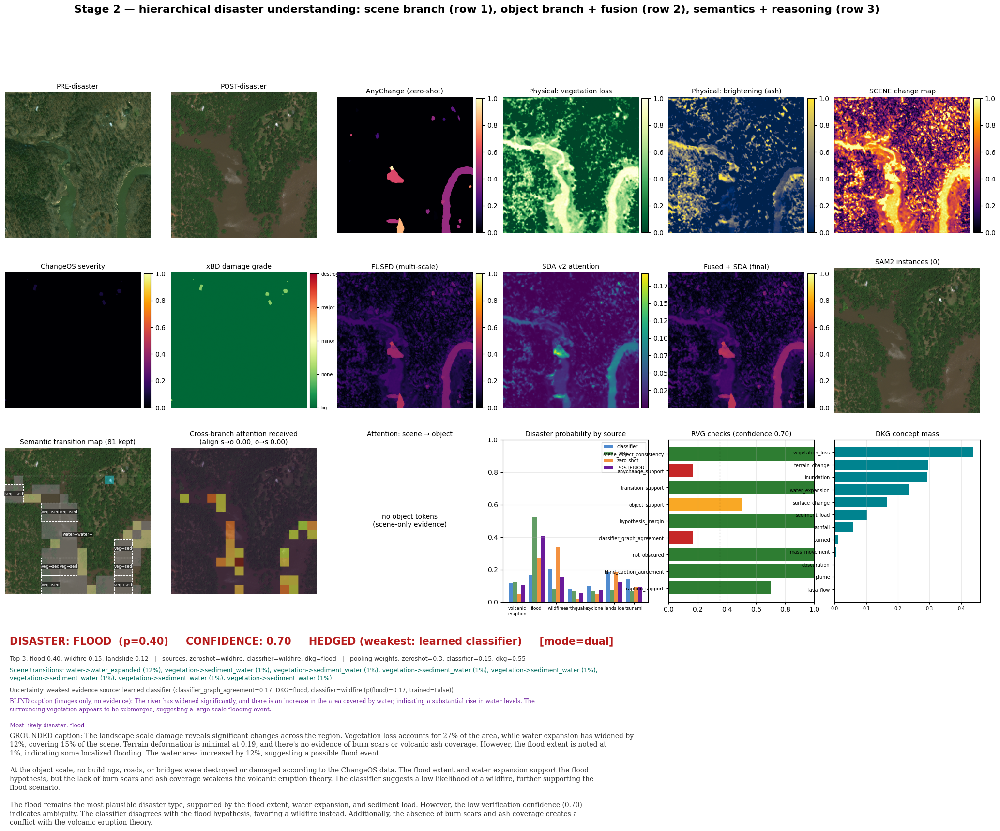

In [38]:
import textwrap
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

GROUP_COLORS = ListedColormap(plt.cm.tab20(np.linspace(0, 1, len(SCENE_GROUPS))).tolist())


def transition_label_map(result: PredictionResult) -> np.ndarray:
    """HxW map of the POST semantic group in every cell where a transition was kept.
    -1 means no transition, which is rendered transparent."""
    H, W = result.post.shape[:2]
    lab = -np.ones((H, W), int)
    for t in sorted(result.scene_evidence.transitions, key=lambda t: t.confidence):
        if t.kind != "patch" or t.dst_group not in SCENE_GROUPS:
            continue
        x0, y0, x1, y1 = t.where
        lab[y0:y1, x0:x1] = SCENE_GROUPS.index(t.dst_group)
    return lab


def _short(g: str) -> str:
    return {"vegetation": "veg", "sediment_water": "sed", "landslide": "slide",
            "water_expanded": "water+", "water_receded": "water-"}.get(g, g)


def visualize(result: PredictionResult, save_path: Optional[str] = None):
    """Four rows: scene branch, object branch + fusion, semantics + reasoning, verdict."""
    fig = plt.figure(figsize=(26, 17.5))
    gs = fig.add_gridspec(4, 6, height_ratios=[3, 3, 3.2, 2.3], hspace=0.16, wspace=0.14)

    def panel(r, c, img, title, cmap=None, vmin=None, vmax=None):
        ax = fig.add_subplot(gs[r, c])
        im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(title, fontsize=10); ax.axis("off")
        if cmap:
            fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        return ax

    # ---- row 0: inputs + SCENE branch -------------------------------------
    panel(0, 0, result.pre, "PRE-disaster")
    panel(0, 1, result.post, "POST-disaster")
    panel(0, 2, result.scene.change_prob, "AnyChange (zero-shot)", "magma", 0, 1)
    panel(0, 3, result.scene.physical["vegetation_loss"], "Physical: vegetation loss", "YlGn_r", 0, 1)
    panel(0, 4, result.scene.physical["brightening"], "Physical: brightening (ash)", "cividis", 0, 1)
    panel(0, 5, result.scene.scene_map, "SCENE change map", "inferno", 0, 1)

    # ---- row 1: OBJECT branch + fusion + SDA ------------------------------
    panel(1, 0, result.obj.damage_severity, "ChangeOS severity", "inferno", 0, 1)
    ax = fig.add_subplot(gs[1, 1])
    im = ax.imshow(result.obj.damage_grades, cmap="RdYlGn_r", vmin=0, vmax=4)
    ax.set_title("xBD damage grade", fontsize=10); ax.axis("off")
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, ticks=[0, 1, 2, 3, 4])
    cb.ax.set_yticklabels(["bg", "none", "minor", "major", "destroyed"], fontsize=7)

    panel(1, 2, result.fused.fused, "FUSED (multi-scale)", "inferno", 0, 1)
    panel(1, 3, result.sda_attention, "SDA v2 attention", "viridis")
    panel(1, 4, result.refined_map, "Fused + SDA (final)", "inferno", 0, 1)

    ax = fig.add_subplot(gs[1, 5])
    ax.imshow(result.post); ax.axis("off")
    ax.set_title(f"SAM2 instances ({len(result.instances)})", fontsize=10)
    colors = plt.cm.tab20(np.linspace(0, 1, max(len(result.instances), 1)))
    for k, inst in enumerate(result.instances):
        ov = np.zeros((*inst.mask.shape, 4)); ov[inst.mask] = (*colors[k][:3], 0.45)
        ax.imshow(ov)
        x0, y0, x1, y1 = inst.bbox
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                   edgecolor=colors[k], lw=1.4))
        tag = (inst.label or "").replace("a ", "").replace("an ", "")[:20]
        if inst.damage_grade:
            tag += f" [{XBD_DAMAGE_CLASSES.get(inst.damage_grade, '')}]"
        ax.text(x0, max(y0 - 3, 6), tag, color="white", fontsize=6,
                bbox=dict(facecolor=colors[k], alpha=0.85, pad=0.9, edgecolor="none"))

    # ---- row 2: semantics, attention, reasoning ---------------------------
    ax = fig.add_subplot(gs[2, 0])
    ax.imshow(result.post)
    lab = transition_label_map(result)
    ax.imshow(np.ma.masked_less(lab, 0), cmap=GROUP_COLORS, alpha=0.55,
              vmin=0, vmax=len(SCENE_GROUPS) - 1)
    top = sorted(result.scene_evidence.transitions, key=lambda t: -(t.confidence * t.weight))[:10]
    for t in top:
        x0, y0, x1, y1 = t.where
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                   edgecolor="white", lw=0.8, ls="--"))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2,
                f"{_short(t.src_group)}\u2192{_short(t.dst_group)}", color="white", fontsize=6,
                ha="center", va="center",
                bbox=dict(facecolor="black", alpha=0.55, pad=0.6, edgecolor="none"))
    ax.set_title(f"Semantic transition map ({len(result.scene_evidence.transitions)} kept)",
                 fontsize=10); ax.axis("off")

    ax = fig.add_subplot(gs[2, 1])
    ax.imshow(result.post)
    ax.imshow(result.tokens.attention_map, cmap="turbo", alpha=0.55, vmin=0, vmax=1)
    ax.set_title(f"Cross-branch attention received\n"
                 f"(align s\u2192o {result.tokens.align_scene_to_object:.2f}, "
                 f"o\u2192s {result.tokens.align_object_to_scene:.2f})", fontsize=10)
    ax.axis("off")

    ax = fig.add_subplot(gs[2, 2])
    A = result.tokens.A_scene_to_object
    if A.size:
        im = ax.imshow(A, cmap="magma", aspect="auto")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)
        ax.set_xlabel("object tokens", fontsize=8); ax.set_ylabel("scene tokens", fontsize=8)
        ax.set_xticks(range(A.shape[1]))
        ax.set_xticklabels([t.text[:14] for t in result.tokens.tokens["object"]],
                           rotation=90, fontsize=5)
        ax.set_yticks([]);
    else:
        ax.text(0.5, 0.5, "no object tokens\n(scene-only evidence)", ha="center", va="center")
        ax.axis("off")
    ax.set_title("Attention: scene \u2192 object", fontsize=10)

    ax = fig.add_subplot(gs[2, 3])
    names = [c.replace("_", "\n") for c in DISASTER_CLASSES]
    x = np.arange(len(DISASTER_CLASSES)); w = 0.2
    series = [("classifier", result.classifier["probs"] if result.classifier else None, "#1565c0"),
              ("DKG", result.dkg["prob_vector"], "#2e7d32"),
              ("zero-shot", result.zeroshot["probs"], "#ef6c00"),
              ("POSTERIOR", result.posterior.probs, "#6a1b9a")]
    for i, (nm, v, col) in enumerate(series):
        if v is None:
            continue
        ax.bar(x + (i - 1.5) * w, v, w, label=nm, color=col,
               alpha=1.0 if nm == "POSTERIOR" else 0.75)
    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=6.5)
    ax.set_ylim(0, 1); ax.legend(fontsize=7); ax.set_title("Disaster probability by source", fontsize=10)
    ax.grid(axis="y", alpha=0.25)

    ax = fig.add_subplot(gs[2, 4])
    ck = result.rvg.get("checks", {})
    if ck:
        keys = list(ck.keys())[::-1]
        vals = [ck[k] for k in keys]
        ax.barh(range(len(keys)), vals,
                color=["#c62828" if v < 0.35 else "#f9a825" if v < 0.7 else "#2e7d32" for v in vals])
        ax.set_yticks(range(len(keys))); ax.set_yticklabels([k[:26] for k in keys], fontsize=7)
        ax.set_xlim(0, 1); ax.axvline(0.35, color="k", ls=":", lw=0.8)
    ax.set_title(f"RVG checks (confidence {result.rvg['confidence']:.2f})", fontsize=10)
    ax.grid(axis="x", alpha=0.25)

    ax = fig.add_subplot(gs[2, 5])
    cm = result.dkg.get("concept_mass", {})
    items = sorted(cm.items(), key=lambda kv: kv[1])[-12:]
    if items:
        ax.barh([k for k, _ in items], [v for _, v in items], color="#00838f")
        ax.tick_params(labelsize=7)
    ax.set_title("DKG concept mass", fontsize=10); ax.grid(axis="x", alpha=0.25)

    # ---- row 3: verdict ----------------------------------------------------
    axc = fig.add_subplot(gs[3, :]); axc.axis("off")
    r = result.rvg
    y = [0.90]                     # running cursor so nothing overlaps or overflows

    def put(text, size=9, color="#333", family="sans-serif", weight="normal",
            width=195, gap=0.030):
        """Wrap to the axis width and advance the cursor by the lines used."""
        lines = []
        for para in str(text).split("\n"):
            lines += textwrap.wrap(para, width) or [""]
        axc.text(0.005, y[0], "\n".join(lines), fontsize=size, color=color,
                 family=family, weight=weight, va="top", linespacing=1.35)
        row_in = fig.get_size_inches()[1] * axc.get_position().height
        y[0] -= len(lines) * (1.35 * size / 72.0) / row_in + gap

    put(f"DISASTER: {result.disaster.upper()}  (p={result.posterior.prob:.2f})     "
        f"CONFIDENCE: {r['confidence']:.2f}     "
        f"{'HEDGED (weakest: ' + r['weakest_source'] + ')' if r['hedge'] else 'evidence agrees'}"
        f"     [mode={result.mode}]",
        size=15, weight="bold", width=120, gap=0.045,
        color="#b71c1c" if r["hedge"] else "#1b5e20")

    put("Top-3: " + ", ".join(f"{t['disaster']} {t['prob']:.2f}"
                              for t in result.posterior.top_k()) +
        "   |   sources: " + ", ".join(f"{k}={v}" for k, v in
                                       result.posterior.as_dict()["sources"].items()) +
        "   |   pooling weights: " + ", ".join(f"{k}={v:g}" for k, v in
                                               result.posterior.weights.items()))

    tr = sorted(result.scene_evidence.transitions, key=lambda t: -t.weight)[:8]
    put("Scene transitions: " +
        ("; ".join(f"{t.src_group}->{t.dst_group} ({100*t.weight:.0f}%)" for t in tr) or "none"),
        color="#00695c")

    put("Uncertainty: " + r["uncertainty_reason"], size=8.5, color="#444")

    if result.blind_caption:
        put("BLIND caption (images only, no evidence): " + result.blind_caption,
            size=8.5, color="#6a1b9a", family="serif", width=185)

    put("GROUNDED caption: " + result.caption, size=10, family="serif", width=175)

    plt.suptitle("Stage 2 — hierarchical disaster understanding: scene branch (row 1), object "
                 "branch + fusion (row 2), semantics + reasoning (row 3)",
                 fontsize=16, weight="bold")
    if save_path:
        plt.savefig(save_path, dpi=130, bbox_inches="tight")
        log.info("Saved -> %s", save_path)
    plt.show()


visualize(result, save_path=f"{CFG.out_dir}/prediction_stage2.png")


11:37:53 | INFO    | Saved -> /kaggle/working/outputs/semantic_transitions.png


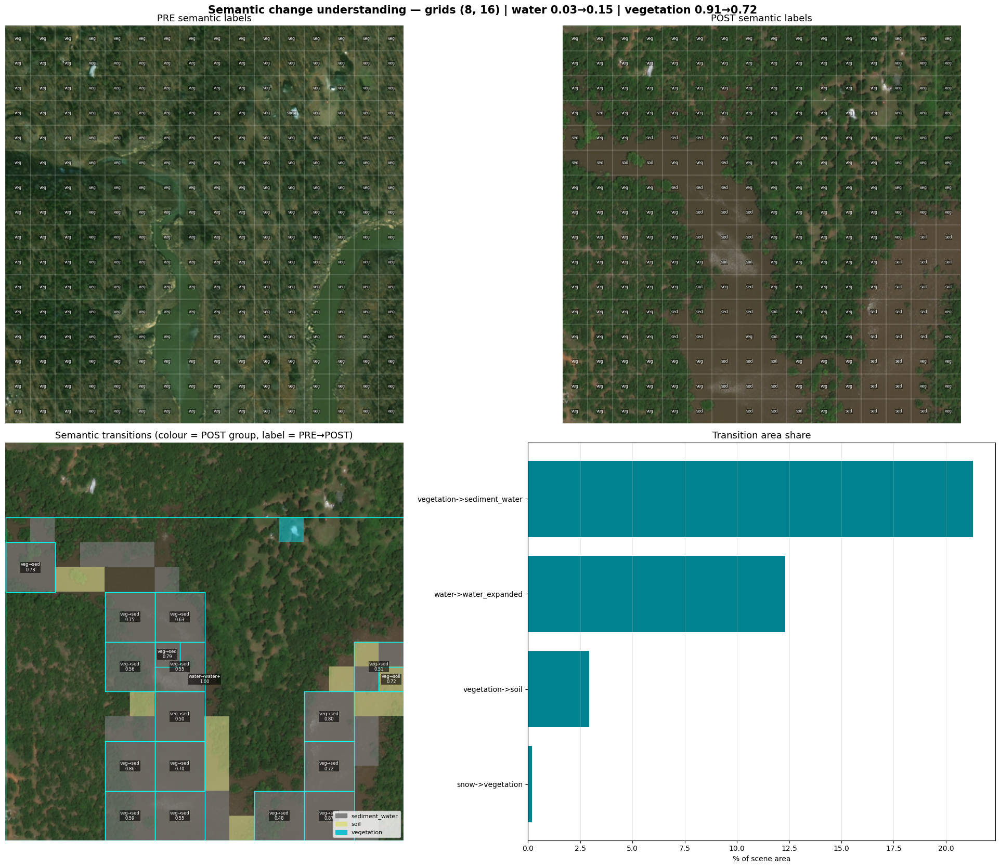

11:37:56 | INFO    | Saved -> /kaggle/working/outputs/cross_branch_attention.png


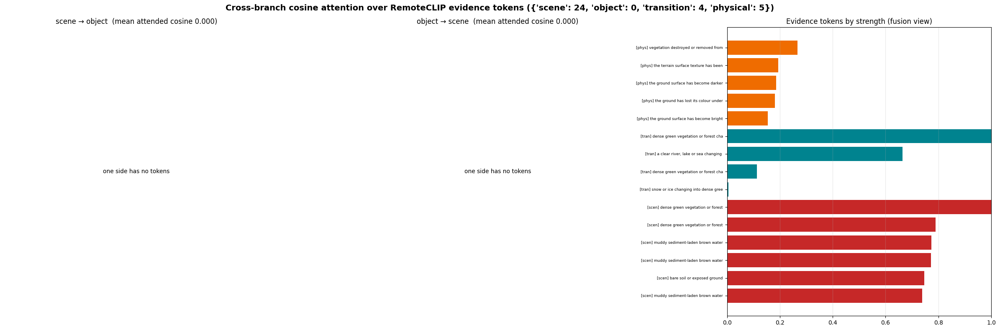

In [39]:
def visualize_transitions(result: PredictionResult, save_path: Optional[str] = None,
                          max_labels: int = 18):
    """Part 7: the semantic transition map, with the PRE and POST labels that produced
    each transition and the area share each transition covers."""
    sem = result.semantics
    pg = sem.main_grid
    fig, axes = plt.subplots(2, 2, figsize=(20, 17))
    ax = axes.ravel()

    for k, (img, side, title) in enumerate([(result.pre, "pre", "PRE semantic labels"),
                                            (result.post, "post", "POST semantic labels")]):
        ax[k].imshow(img); ax[k].axis("off"); ax[k].set_title(title, fontsize=13)
        if pg is None:
            continue
        o = pg.pre if side == "pre" else pg.post
        for i, (x0, y0, x1, y1) in enumerate(pg.boxes):
            ax[k].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                          edgecolor="white", lw=0.3, alpha=0.4))
            if o.conf[i] > 0.30:
                ax[k].text((x0 + x1) / 2, (y0 + y1) / 2, _short(o.groups[i]), color="white",
                           fontsize=5.5, ha="center", va="center",
                           bbox=dict(facecolor="black", alpha=0.4, pad=0.4, edgecolor="none"))

    ax[2].imshow(result.post)
    lab = transition_label_map(result)
    ax[2].imshow(np.ma.masked_less(lab, 0), cmap=GROUP_COLORS, alpha=0.6,
                 vmin=0, vmax=len(SCENE_GROUPS) - 1)
    shown = sorted(result.scene_evidence.transitions,
                   key=lambda t: -(t.confidence * t.weight))[:max_labels]
    for t in shown:
        x0, y0, x1, y1 = t.where
        ax[2].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                      edgecolor="cyan", lw=1.0))
        ax[2].text((x0 + x1) / 2, (y0 + y1) / 2,
                   f"{_short(t.src_group)}\u2192{_short(t.dst_group)}\n{t.confidence:.2f}",
                   color="white", fontsize=6, ha="center", va="center",
                   bbox=dict(facecolor="black", alpha=0.6, pad=0.6, edgecolor="none"))
    present = sorted({t.dst_group for t in result.scene_evidence.transitions
                      if t.dst_group in SCENE_GROUPS})
    ax[2].legend(handles=[mpatches.Patch(color=GROUP_COLORS(SCENE_GROUPS.index(g)), label=g)
                          for g in present], fontsize=8, loc="lower right", framealpha=0.8)
    ax[2].set_title("Semantic transitions (colour = POST group, label = PRE\u2192POST)", fontsize=13)
    ax[2].axis("off")

    agg: Dict[str, float] = {}
    for t in result.scene_evidence.transitions:
        agg[t.name] = agg.get(t.name, 0.0) + t.weight
    items = sorted(agg.items(), key=lambda kv: kv[1])[-14:]
    if items:
        ax[3].barh([k for k, _ in items], [100 * v for _, v in items], color="#00838f")
        ax[3].set_xlabel("% of scene area", fontsize=10)
    else:
        ax[3].text(0.5, 0.5, "no semantic transitions kept", ha="center", va="center")
    ax[3].set_title("Transition area share", fontsize=13)
    ax[3].grid(axis="x", alpha=0.3)

    plt.suptitle(f"Semantic change understanding — grids {tuple(sem.grids)} | "
                 f"water {sem.water_pre:.2f}\u2192{sem.water_post:.2f} | "
                 f"vegetation {sem.veg_pre:.2f}\u2192{sem.veg_post:.2f}",
                 fontsize=15, weight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=130, bbox_inches="tight"); log.info("Saved -> %s", save_path)
    plt.show()


def visualize_attention(result: PredictionResult, save_path: Optional[str] = None):
    """Part 7: the cross-branch attention matrices and the token-level fusion view."""
    tk = result.tokens
    fig, ax = plt.subplots(1, 3, figsize=(24, 8))

    def matrix(a, A, rows, cols, title):
        if A.size == 0:
            a.text(0.5, 0.5, "one side has no tokens", ha="center", va="center"); a.axis("off")
            a.set_title(title, fontsize=12); return
        im = a.imshow(A, cmap="magma", aspect="auto", vmin=0)
        plt.colorbar(im, ax=a, fraction=0.046)
        a.set_yticks(range(len(rows)))
        a.set_yticklabels([t.text[:34] for t in rows], fontsize=6)
        a.set_xticks(range(len(cols)))
        a.set_xticklabels([t.text[:24] for t in cols], rotation=90, fontsize=6)
        a.set_title(title, fontsize=12)

    matrix(ax[0], tk.A_scene_to_object, tk.tokens["scene"], tk.tokens["object"],
           f"scene \u2192 object  (mean attended cosine {tk.align_scene_to_object:.3f})")
    matrix(ax[1], tk.A_object_to_scene, tk.tokens["object"], tk.tokens["scene"],
           f"object \u2192 scene  (mean attended cosine {tk.align_object_to_scene:.3f})")

    kinds = ["scene", "object", "transition", "physical"]
    cols = {"scene": "#c62828", "object": "#1565c0", "transition": "#00838f", "physical": "#ef6c00"}
    y, labels, colors = [], [], []
    for k in kinds:
        for t in sorted(tk.tokens[k], key=lambda t: t.value)[-6:]:
            y.append(t.value); labels.append(f"[{k[:4]}] {t.text[:36]}"); colors.append(cols[k])
    if y:
        ax[2].barh(range(len(y)), y, color=colors)
        ax[2].set_yticks(range(len(y))); ax[2].set_yticklabels(labels, fontsize=6.5)
        ax[2].set_xlim(0, 1)
    ax[2].set_title("Evidence tokens by strength (fusion view)", fontsize=12)
    ax[2].grid(axis="x", alpha=0.3)

    plt.suptitle("Cross-branch cosine attention over RemoteCLIP evidence tokens "
                 f"({tk.counts()})", fontsize=14, weight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=130, bbox_inches="tight"); log.info("Saved -> %s", save_path)
    plt.show()


visualize_transitions(result, save_path=f"{CFG.out_dir}/semantic_transitions.png")
visualize_attention(result, save_path=f"{CFG.out_dir}/cross_branch_attention.png")


11:37:58 | INFO    | Saved -> /kaggle/working/outputs/dkg_graph.png


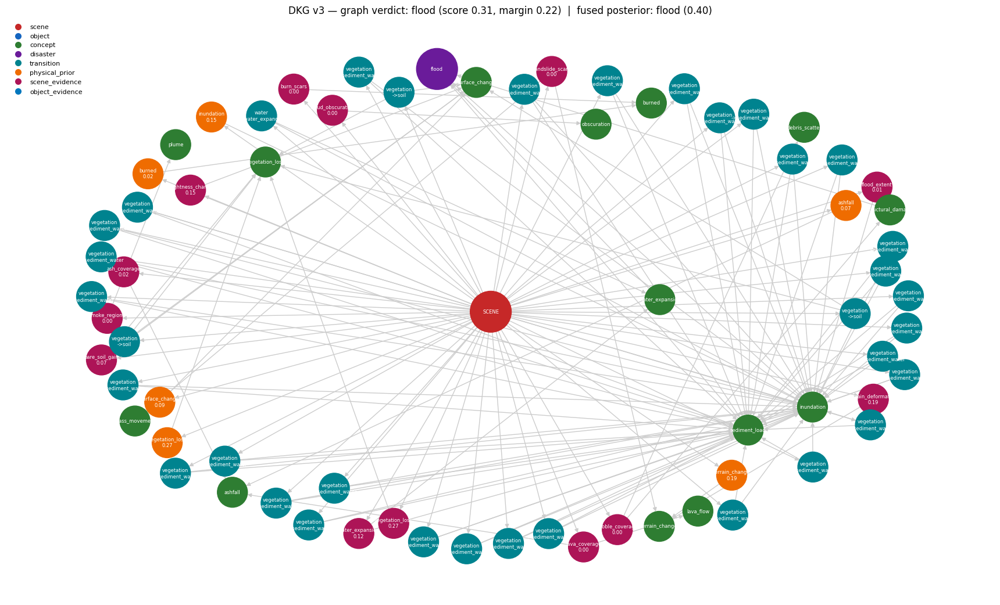

DISASTER DECISION — three opinions, one calibrated posterior
class                 classifier       DKG   zero-shot   POSTERIOR
volcanic_eruption          0.116     0.122       0.050       0.103
flood                      0.168     0.524       0.275       0.404
wildfire                   0.205     0.077       0.337       0.154
earthquake                 0.082     0.068       0.020       0.053
cyclone                    0.102     0.068       0.046       0.071
landslide                  0.183     0.073       0.183       0.122
tsunami                    0.144     0.068       0.090       0.092
----------------------------------------------------------------------------------------
pool weights: {'zeroshot': 0.3, 'classifier': 0.15, 'dkg': 0.55} | head trained: False
posterior: flood p=0.404 margin=0.250 entropy=0.879
RVG v3 REPORT   confidence=0.698   agreement=0.720   hedge=True
  scene_object_consistency      1.00  w=0.14  |############################| scene-driven hypothesis, coverage=

In [40]:
def visualize_graph(result: PredictionResult, max_nodes: int = 70,
                    save_path: Optional[str] = None):
    G = result.graph
    if G.number_of_nodes() == 0:
        print("DKG disabled for this run."); return
    if G.number_of_nodes() > max_nodes:
        # keep the scene root, all concepts/disasters/aggregated evidence, and the
        # heaviest individual transitions and instances
        keep = {n for n, d in G.nodes(data=True)
                if d.get("kind") in {"scene", "concept", "disaster", "physical_prior",
                                     "scene_evidence", "object_evidence"}}
        rest = [(n, d) for n, d in G.nodes(data=True)
                if d.get("kind") in {"transition", "object"}]
        rest.sort(key=lambda nd: -float(nd[1].get("conf", nd[1].get("change", 0.0))))
        keep |= {n for n, _ in rest[:max(0, max_nodes - len(keep))]}
        G = G.subgraph(keep).copy()

    plt.figure(figsize=(17, 10))
    pos = nx.spring_layout(G, seed=CFG.seed, k=1.2)
    colors = {"scene": "#c62828", "object": "#1565c0", "concept": "#2e7d32",
              "disaster": "#6a1b9a", "transition": "#00838f", "physical_prior": "#ef6c00",
              "scene_evidence": "#ad1457", "object_evidence": "#0277bd"}
    nc = [colors.get(G.nodes[n].get("kind"), "#888") for n in G.nodes]
    sizes = [2600 if G.nodes[n].get("kind") in ("disaster", "scene") else 1400 for n in G.nodes]

    labels = {}
    for n in G.nodes:
        d = G.nodes[n]; k = d.get("kind")
        if k == "object":
            labels[n] = (d.get("label", n) or n)[:16] + (f"\n{d['damage']}" if "damage" in d else "")
        elif k == "transition":
            labels[n] = f"{d['src']}\n->{d['dst']}"
        elif k == "physical_prior":
            labels[n] = n.replace("phys:", "") + f"\n{d.get('mass', 0):.2f}"
        elif k == "scene_evidence":
            labels[n] = n.replace("scene:", "") + f"\n{d.get('mass', 0):.2f}"
        elif k == "object_evidence":
            labels[n] = n.replace("objev:", "").replace("_frac", "") + f"\n{d.get('mass', 0):.2f}"
        else:
            labels[n] = n.replace("concept:", "").replace("disaster:", "")
    nx.draw(G, pos, labels=labels, node_color=nc, node_size=sizes,
            font_size=6, font_color="white", edge_color="#ccc", arrows=True)
    handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=v,
                          markersize=9, label=k) for k, v in colors.items()]
    plt.legend(handles=handles, loc="upper left", fontsize=8, frameon=False)
    plt.title(f"DKG v3 — graph verdict: {result.dkg['disaster']} "
              f"(score {result.dkg['score']:.2f}, margin {result.dkg['margin']:.2f})  |  "
              f"fused posterior: {result.disaster} ({result.posterior.prob:.2f})")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=130, bbox_inches="tight"); log.info("Saved -> %s", save_path)
    plt.show()


def print_reliability_report(result: PredictionResult):
    r = result.rvg
    print("=" * 88)
    print(f"RVG v3 REPORT   confidence={r['confidence']:.3f}   agreement={r['raw_agreement']:.3f}"
          f"   hedge={r['hedge']}")
    print("=" * 88)
    for k, v in r.get("checks", {}).items():
        w = r["weights"].get(k, 0.0)
        bar = "#" * int(round(28 * v))
        print(f"  {k:<28} {v:5.2f}  w={w:4.2f}  |{bar:<28}| {r['notes'].get(k, '')[:70]}")
    print(f"\n  weakest evidence source : {r['weakest_source']}  ({r['weakest_check']})")
    print(f"  reason for uncertainty  : {r['uncertainty_reason']}")
    if r.get("blind"):
        b = r["blind"]
        print("\n  BLIND-CAPTION VERIFICATION")
        print(f"    blind verdict     : {b['blind_disaster']}")
        print(f"    pipeline verdict  : {b['pipeline_disaster']}")
        print(f"    label match       : {b['label_match']}")
        print(f"    caption similarity: {b['semantic_similarity']}")
        print(f"    evidence mentions : blind {b['blind_grounding']:.2f} vs "
              f"grounded {b['grounded_grounding']:.2f}")
        print(f"    agreement score   : {b['agreement']}")
    print("=" * 88)


def print_classifier_report(result: PredictionResult):
    print("=" * 88)
    print("DISASTER DECISION — three opinions, one calibrated posterior")
    print("=" * 88)
    print(f"{'class':<20}{'classifier':>12}{'DKG':>10}{'zero-shot':>12}{'POSTERIOR':>12}")
    for i, c in enumerate(DISASTER_CLASSES):
        clf = f"{result.classifier['probs'][i]:.3f}" if result.classifier else "  off"
        print(f"{c:<20}{clf:>12}{result.dkg['prob_vector'][i]:>10.3f}"
              f"{result.zeroshot['probs'][i]:>12.3f}{result.posterior.probs[i]:>12.3f}")
    print("-" * 88)
    print(f"pool weights: {result.posterior.weights} | "
          f"head trained: {result.classifier['is_trained'] if result.classifier else 'n/a'}")
    print(f"posterior: {result.disaster} p={result.posterior.prob:.3f} "
          f"margin={result.posterior.margin:.3f} entropy={result.posterior.entropy:.3f}")
    print("=" * 88)


visualize_graph(result, save_path=f"{CFG.out_dir}/dkg_graph.png")
print_classifier_report(result)
print_reliability_report(result)


## 16 · Scene-branch verification

`verify_scene_branch` is an assertion, not a chart: it proves the scene branch produced valid
structured output **and** that `MultiScaleFusion` actually consumes it, by zeroing AnyChange and
measuring how much the fused field moves. It raises when the branch is silently dead. Carried over
from Stage 1 unchanged — it still guards the same failure.


=== SCENE BRANCH VERIFICATION ===
  anychange_ran                          True
  n_regions                              19
  region_prob                            [0.975, 0.847, 0.733, 0.592, 0.57, 0.494, 0.489, 0.471]
  region_angle_deg                       [64.3, 60.4, 57.0, 52.8, 52.1, 49.8, 49.7, 49.1]
  region_cosine                          [-0.434, -0.494, -0.545, -0.605, -0.614, -0.645, -0.647, -0.654]
  region_area                            [139, 1114, 79, 2136, 51, 144, 646, 136]
  mask_pixels_total                      14277
  anychange_prob_max                     0.9752
  anychange_coverage                     0.0538
  scene_map_mean                         0.494
  anychange_dominates_physical_frac      0.0027
  scene_map_equals_physical              False
  fusion_weight_anychange                0.35
  fusion_delta_mean                      0.00887
  fusion_delta_max                       0.34131
  fusion_pixels_changed_frac             0.0538
  fused_coverage_with   

11:38:01 | INFO    | Saved -> /kaggle/working/outputs/scene_branch.png


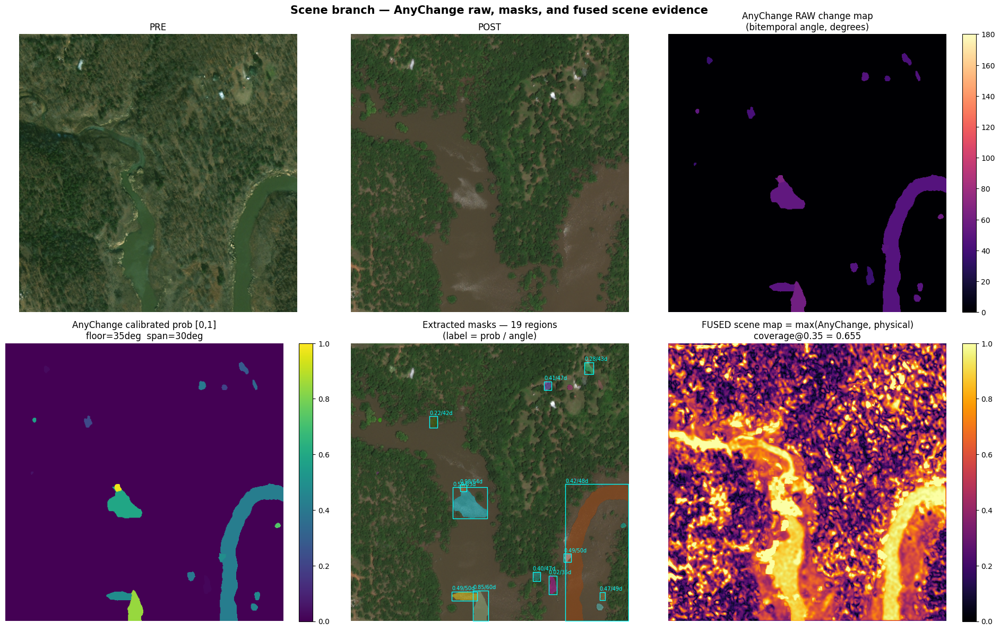

In [41]:
from dataclasses import replace as _dc_replace
import matplotlib.patches as mpatches


def verify_scene_branch(result: PredictionResult, fusion: MultiScaleFusion,
                        cfg: Config, strict: bool = True) -> Dict[str, Any]:
    """Requirements 6 and 7: prove the scene branch produced valid output AND that
    MultiScaleFusion consumes it. Returns the report; raises when strict."""
    scene, fused = result.scene, result.fused
    a, s, p = scene.change_prob, scene.scene_map, scene.physical["composite"]
    rep: Dict[str, Any] = {}
    problems: List[str] = []

    # --- 6a: the detector ran and returned structured regions ----------------
    rep["anychange_ran"] = bool(scene.anychange_ran)
    rep["n_regions"] = len(scene.regions)
    if scene.anychange_ran and rep["n_regions"] < cfg.anychange_min_regions:
        problems.append(f"AnyChange ran but returned {rep['n_regions']} regions "
                        f"(min {cfg.anychange_min_regions}).")
    if scene.regions:
        r0 = scene.regions[0]
        for f in ("mask", "cosine", "angle", "prob", "box", "area", "iou_pred"):
            if not hasattr(r0, f):
                problems.append(f"regions are not ChangeRegion objects (missing '{f}').")
        rep["region_prob"] = [round(float(r.prob), 3) for r in scene.regions[:8]]
        rep["region_angle_deg"] = [round(float(r.angle), 1) for r in scene.regions[:8]]
        rep["region_cosine"] = [round(float(r.cosine), 3) for r in scene.regions[:8]]
        rep["region_area"] = [int(r.area) for r in scene.regions[:8]]
        rep["mask_pixels_total"] = int(sum(int(r.mask.sum()) for r in scene.regions))

    # --- 6b: the maps are well formed ---------------------------------------
    for name, m in (("change_prob", a), ("scene_map", s)):
        if not np.isfinite(m).all():
            problems.append(f"{name} contains NaN/Inf.")
        if m.min() < -1e-6 or m.max() > 1 + 1e-6:
            problems.append(f"{name} outside [0,1]: [{m.min():.3f}, {m.max():.3f}]")
        if m.shape != (cfg.work_size, cfg.work_size):
            problems.append(f"{name} has shape {m.shape}, expected work grid.")
    rep["anychange_prob_max"] = round(float(a.max()), 4)
    rep["anychange_coverage"] = round(float((a > 0).mean()), 4)
    rep["scene_map_mean"] = round(float(s.mean()), 4)

    if scene.anychange_ran and float(a.max()) == 0.0:
        problems.append("AnyChange map is entirely zero — unpacking or calibration failed.")

    # --- 6c: AnyChange survives into scene_map ------------------------------
    dominant = float((a > p + 1e-6).mean())
    rep["anychange_dominates_physical_frac"] = round(dominant, 4)
    rep["scene_map_equals_physical"] = bool(np.allclose(s, np.clip(p, 0, 1), atol=1e-6))
    if scene.anychange_ran and rep["scene_map_equals_physical"]:
        problems.append("scene_map is identical to the physical composite — "
                        "AnyChange contributes nothing to the scene branch.")

    # --- 7: ablation, does fusion actually use it ---------------------------
    zeroed = _dc_replace(scene,
                         change_prob=np.zeros_like(a),
                         scene_map=np.clip(p, 0, 1))
    without = fusion(result.obj, zeroed)
    d = np.abs(fused.fused - without.fused)
    rep["fusion_weight_anychange"] = round(float(fusion.w[1]), 3)
    rep["fusion_delta_mean"] = round(float(d.mean()), 5)
    rep["fusion_delta_max"] = round(float(d.max()), 5)
    rep["fusion_pixels_changed_frac"] = round(float((d > 1e-4).mean()), 4)
    rep["fused_coverage_with"] = round(float((fused.fused > cfg.change_threshold).mean()), 4)
    rep["fused_coverage_without"] = round(float((without.fused > cfg.change_threshold).mean()), 4)
    if scene.anychange_ran and rep["fusion_delta_max"] <= 1e-4:
        problems.append("Zeroing AnyChange leaves the fused field unchanged — "
                        "fusion is not consuming the scene branch.")

    rep["problems"] = problems
    rep["ok"] = not problems
    for k, v in rep.items():
        if k != "problems":
            print(f"  {k:38s} {v}")
    if problems:
        print("\n  PROBLEMS:")
        for p_ in problems:
            print(f"   - {p_}")
        if strict:
            raise AssertionError("Scene-branch verification failed: " + " | ".join(problems))
    else:
        print("\n  scene branch verified: AnyChange -> scene_map -> fusion")
    return rep


def visualize_scene_branch(result: PredictionResult, cfg: Config,
                           save_path: Optional[str] = None, max_labels: int = 12):
    """Requirement 8: raw AnyChange map, the extracted mask instances, the fused
    scene map — plus the physical composite they are combined with."""
    scene = result.scene
    fig, axes = plt.subplots(2, 3, figsize=(19, 12))
    ax = axes.ravel()

    ax[0].imshow(result.pre);  ax[0].set_title("PRE", fontsize=12)
    ax[1].imshow(result.post); ax[1].set_title("POST", fontsize=12)

    im = ax[2].imshow(scene.raw_angle, cmap="magma", vmin=0, vmax=180)
    ax[2].set_title("AnyChange RAW change map\n(bitemporal angle, degrees)", fontsize=12)
    plt.colorbar(im, ax=ax[2], fraction=0.046)

    im = ax[3].imshow(scene.change_prob, cmap="viridis", vmin=0, vmax=1)
    ax[3].set_title(f"AnyChange calibrated prob [0,1]\n"
                    f"floor={180 - cfg.anychange_conf:.0f}deg  span={cfg.anychange_angle_span:.0f}deg",
                    fontsize=12)
    plt.colorbar(im, ax=ax[3], fraction=0.046)

    # extracted mask instances, one colour per region, strongest on top
    ax[4].imshow(result.post)
    overlay = np.zeros((*scene.change_prob.shape, 4), np.float32)
    rng = np.random.default_rng(0)
    for k, r in enumerate(sorted(scene.regions, key=lambda r: -r.area)):
        c = np.concatenate([rng.random(3), [0.45]])
        overlay[r.mask] = c
        if k < max_labels:
            x0, y0, x1, y1 = r.box
            ax[4].add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                               edgecolor="cyan", linewidth=1.0))
            ax[4].text(x0, max(y0 - 3, 6), f"{r.prob:.2f}/{r.angle:.0f}d",
                       color="cyan", fontsize=7)
    ax[4].imshow(overlay)
    ax[4].set_title(f"Extracted masks — {len(scene.regions)} regions\n"
                    f"(label = prob / angle)", fontsize=12)

    im = ax[5].imshow(scene.scene_map, cmap="inferno", vmin=0, vmax=1)
    ax[5].set_title(f"FUSED scene map = max(AnyChange, physical)\n"
                    f"coverage@{cfg.scene_change_thr:.2f} = "
                    f"{scene.coverage(cfg.scene_change_thr):.3f}", fontsize=12)
    plt.colorbar(im, ax=ax[5], fraction=0.046)

    for a_ in ax:
        a_.axis("off")
    plt.suptitle("Scene branch — AnyChange raw, masks, and fused scene evidence",
                 fontsize=15, weight="bold")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=140, bbox_inches="tight")
        log.info("Saved -> %s", save_path)
    plt.show()


print("=== SCENE BRANCH VERIFICATION ===")
scene_report = verify_scene_branch(result, fusion, CFG, strict=True)
visualize_scene_branch(result, CFG, save_path=f"{CFG.out_dir}/scene_branch.png")


## 17 · Persist the run

The full run record — evidence, transitions, all three opinions, the posterior, RVG checks, both
captions and the switch state — is written to `{CFG.out_dir}/prediction_stage2_{mode}.json`, so an
ablation sweep leaves one file per configuration for later comparison.


In [42]:
def run_record(result: PredictionResult, cfg: Config) -> dict:
    return {
        "config": {k: str(v) for k, v in asdict(cfg).items()},
        "mode": result.mode,
        "switches": result.switches,
        "scene_branch": {
            "anychange_ran": result.scene.anychange_ran,
            "anychange_regions": len(result.scene.regions),
            "physical_means": {k: round(float(v.mean()), 4)
                               for k, v in result.scene.physical.items()},
            "evidence": {k: round(result.scene_evidence[k], 5) for k in SCENE_FIELDS},
            "group_coverage_pre": {k: round(v, 4) for k, v in
                                   result.scene_evidence.group_cov_pre.items()},
            "group_coverage_post": {k: round(v, 4) for k, v in
                                    result.scene_evidence.group_cov_post.items()},
            "transitions": [{"src": t.src_group, "dst": t.dst_group,
                             "src_label": t.src_label, "dst_label": t.dst_label,
                             "conf": round(t.confidence, 3),
                             "transition_prob": round(t.transition_prob, 3),
                             "embed_similarity": round(t.embed_similarity, 3),
                             "weight": round(t.weight, 4), "grid": t.grid, "kind": t.kind,
                             "bbox": list(t.where)}
                            for t in result.scene_evidence.transitions],
        },
        "object_branch": {
            "damaged_area_frac": round(result.obj.damaged_area_frac, 5),
            "evidence": {k: round(result.object_evidence[k], 5) for k in OBJECT_FIELDS},
            "counts": result.object_evidence.counts,
            "grade_hist": {XBD_DAMAGE_CLASSES[g]: round(v, 5)
                           for g, v in result.object_evidence.grade_hist.items()},
            "instances": [{"label": i.label, "label_conf": round(i.label_conf, 3),
                           "change_score": round(i.change_score, 3),
                           "refined_score": round(i.refined_score, 3),
                           "area": i.area, "bbox": list(i.bbox),
                           "xbd_grade": XBD_DAMAGE_CLASSES.get(i.damage_grade)
                           if i.damage_grade is not None else None,
                           "transition": (i.transition.name if i.transition else None)}
                          for i in result.instances],
        },
        "fusion_scalars": {k: round(v, 5) for k, v in result.fused.scalars.items()},
        "sda_report": result.sda_report,
        "tokens": {"counts": result.tokens.counts(),
                   "align_scene_to_object": round(result.tokens.align_scene_to_object, 4),
                   "align_object_to_scene": round(result.tokens.align_object_to_scene, 4),
                   "top": [{"kind": t.kind, "text": t.text, "value": round(t.value, 3),
                            "meta": t.meta}
                           for k in ("scene", "object", "transition", "physical")
                           for t in result.tokens.tokens[k][:5]]},
        "dkg": {k: v for k, v in result.dkg.items() if k != "prob_vector"},
        "classifier": ({k: (v.tolist() if isinstance(v, np.ndarray) else v)
                        for k, v in result.classifier.items() if k != "embedding"}
                       if result.classifier else None),
        "zeroshot": {k: (v.tolist() if isinstance(v, np.ndarray) else v)
                     for k, v in result.zeroshot.items()},
        "posterior": result.posterior.as_dict(),
        "rvg_provisional": result.rvg_provisional,
        "rvg_final": result.rvg,
        "evidence_package": result.package.as_dict(),
        "blind_caption": result.blind_caption,
        "caption": result.caption,
        "timings": {k: round(v, 3) for k, v in result.timings.items()},
    }


record = run_record(result, CFG)
out_json = f"{CFG.out_dir}/prediction_stage2_{result.mode}.json"
Path(out_json).write_text(json.dumps(record, indent=2, default=str))
log.info("Saved run record -> %s", out_json)


11:38:03 | INFO    | Saved run record -> /kaggle/working/outputs/prediction_stage2_dual.json


## 18 · Training the head (optional, needs labels)

The head works untrained. To move it out of zero-shot mode, supply a CSV manifest:

```
pre,post,disaster,caption
/path/pre_0001.png,/path/post_0001.png,volcanic_eruption,optional reference caption
```

`disaster` must be one of `DISASTER_CLASSES`. Then:

```python
pairs = load_manifest("/kaggle/input/<your-dataset>/train.csv")
feats = extract_dataset_features(pipeline, pairs)      # cached to features_train.npz
train_head(classifier, feats, pairs)                   # fits + temperature-calibrates
```

Feature extraction is the expensive part and is cached, so re-training the head after changing its
width or dropout costs seconds. The fit uses a stratified split, early stopping on validation
accuracy, and post-hoc temperature scaling; `is_trained` then flips the pooling weights
automatically. xBD's `disaster_type` metadata is the obvious first source of labels.


In [43]:
@dataclass
class LabeledPair:
    pre: str
    post: str
    disaster: str
    reference_caption: Optional[str] = None


def load_manifest(path: str) -> List[LabeledPair]:
    """CSV with columns: pre,post,disaster[,caption]. Paths may be relative to the CSV.

    No dataset ships with this notebook and none is downloaded: supply your own
    labelled pairs (xBD `disaster_type` metadata, RSCC, or your own annotation) and the
    head trains on them. Without a manifest the head stays in its text-initialised
    zero-shot mode and the pipeline runs exactly as it does above.
    """
    import csv
    root = Path(path).parent
    pairs, bad = [], []
    with open(path, newline="") as f:
        for row in csv.DictReader(f):
            d = (row.get("disaster") or "").strip()
            if d not in DISASTER_CLASSES:
                bad.append(d); continue
            pre, post = Path(row["pre"]), Path(row["post"])
            pre = pre if pre.is_absolute() else root / pre
            post = post if post.is_absolute() else root / post
            pairs.append(LabeledPair(str(pre), str(post), d,
                                     (row.get("caption") or "").strip() or None))
    if bad:
        log.warning("Skipped %d rows with labels outside %s: %s",
                    len(bad), DISASTER_CLASSES, sorted(set(bad))[:5])
    log.info("Manifest: %d usable pairs | class counts %s",
             len(pairs), dict(Counter(p.disaster for p in pairs)))
    return pairs


def extract_dataset_features(pipeline: DisasterCaptioningPipeline, pairs: List[LabeledPair],
                             cache: Optional[str] = None, force: bool = False
                             ) -> Tuple[List[ClassifierFeatures], List[str]]:
    """Runs the frozen pipeline once per pair (no Qwen) and caches z/t to disk, so
    training and re-training cost one forward pass per pair in total."""
    if cache and Path(cache).is_file() and not force:
        d = np.load(cache, allow_pickle=True)
        if d["tab_dim"] == TAB_DIM and len(d["labels"]) == len(pairs):
            feats = [ClassifierFeatures(z, t, g, s, o) for z, t, g, s, o in
                     zip(d["z"], d["t"], d["g"], d["s"], d["o"])]
            log.info("Loaded cached features for %d pairs from %s", len(feats), cache)
            return feats, list(d["labels"])
        log.warning("Cache at %s does not match the current pairs/layout; recomputing.", cache)

    feats, labels = [], []
    for i, p in enumerate(pairs, 1):
        try:
            feats.append(pipeline.extract_features(p.pre, p.post))
            labels.append(p.disaster)
        except Exception as e:
            log.warning("[%d/%d] skipped %s (%s: %s)", i, len(pairs), p.pre,
                        type(e).__name__, e)
            continue
        if i % 10 == 0 or i == len(pairs):
            log.info("features %d/%d", i, len(pairs))
    if cache and feats:
        np.savez_compressed(
            cache, z=np.stack([f.z for f in feats]), t=np.stack([f.t for f in feats]),
            g=np.stack([f.global_post for f in feats]),
            s=np.stack([f.scene_repr for f in feats]),
            o=np.stack([f.object_repr for f in feats]),
            labels=np.array(labels), tab_dim=TAB_DIM)
        log.info("Cached %d feature vectors -> %s", len(feats), cache)
    return feats, labels


def train_head(pipeline: DisasterCaptioningPipeline, manifest_csv: str,
               cache: Optional[str] = None, **fit_kwargs) -> dict:
    """End-to-end: manifest -> frozen features -> trained, temperature-calibrated head.

    Only `DisasterClassifierHead` receives gradients. ChangeOS, AnyChange, SAM2,
    RemoteCLIP and Qwen are all frozen and are used purely as feature extractors.
    """
    pairs = load_manifest(manifest_csv)
    feats, labels = extract_dataset_features(pipeline, pairs,
                                             cache or f"{CFG.out_dir}/features_train.npz")
    hist = pipeline.classifier.fit(feats, labels, **fit_kwargs)
    print(f"best val accuracy {hist['best_val_acc']:.3f} "
          f"({hist['n_train']} train / {hist['n_val']} val), T={hist['temperature']:.2f}")
    return hist


# ---------------------------------------------------------------------------
# To train, point this at your own CSV and uncomment. The pipeline is fully
# functional without it -- the head is text-initialised, so `is_trained=False`
# simply means the pool leans on DKG and the zero-shot prior instead.
# ---------------------------------------------------------------------------
# history = train_head(pipeline, "/kaggle/input/<your-dataset>/train.csv")
# plt.plot([h["train_acc"] for h in history["curve"]], label="train")
# plt.plot([h["val_acc"] for h in history["curve"]], label="val")
# plt.xlabel("epoch"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show()
print("Classifier head:", "TRAINED" if classifier.is_trained else
      "zero-shot (text-initialised) — supply a manifest to train_head() to fine-tune")


Classifier head: zero-shot (text-initialised) — supply a manifest to train_head() to fine-tune


## 19 · Evaluation and ablation (Part 8)

* `profile()` — parameter counts, per-stage timings, peak VRAM.
* `contribution_analysis()` — a real per-image probe: it re-runs the DKG with the scene sources
  dropped, re-runs the classifier on masked features, re-pools, and reports how far the posterior
  moved (JSD) and whether the label flipped. Then the same for the object sources. This measures a
  posterior shift, not an attention weight.
* `run_ablation()` / `ablation_table()` — ten configurations covering every switch plus
  `object_only` (the Stage 0 baseline), tabulated side by side.
* `evaluate_dataset()` — accuracy, macro-F1, top-k accuracy, confusion matrix and caption metrics
  (BLEU / ROUGE / BERTScore when references are present) over a manifest.
* `compare_pipelines()` — Stage 0 vs Stage 2 on one pair, captions included.

Dataset evaluation and the A/B are left commented out because they need a manifest and extra Qwen
generations; the profile, contribution probe and ablation sweep run automatically on the current
pair.


In [44]:
# ---------------------------------------------------------------------------
# Caption / localisation metrics (unchanged from Stage 1)
# ---------------------------------------------------------------------------
def evaluate_captions(hypotheses: List[str], references: List[str]) -> dict:
    if not hypotheses or len(hypotheses) != len(references):
        raise ValueError("hypotheses and references must be non-empty and equal length")
    import sacrebleu
    from rouge_score import rouge_scorer
    import bert_score
    out = {"BLEU-4": round(sacrebleu.corpus_bleu(hypotheses, [references]).score, 2)}
    rs = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
    out["ROUGE-L"] = round(100 * float(np.mean(
        [rs.score(r, h)["rougeL"].fmeasure for h, r in zip(hypotheses, references)])), 2)
    _, _, f1 = bert_score.score(hypotheses, references, lang="en", verbose=False)
    out["BERTScore-F1"] = round(100 * float(f1.mean()), 2)
    return out


def evaluate_localization(pred_map, gt_mask, threshold=0.5) -> dict:
    p, g = (pred_map > threshold).astype(bool), gt_mask.astype(bool)
    tp = np.logical_and(p, g).sum(); fp = np.logical_and(p, ~g).sum()
    fn = np.logical_and(~p, g).sum()
    prec, rec = tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)
    return {"IoU": round(float(tp / (tp + fp + fn + 1e-9)), 4),
            "F1": round(float(2 * prec * rec / (prec + rec + 1e-9)), 4),
            "precision": round(float(prec), 4), "recall": round(float(rec), 4)}


def sda_ablation(result: PredictionResult, gt_mask, threshold=0.5) -> dict:
    before = evaluate_localization(result.fused.fused, gt_mask, threshold)
    after = evaluate_localization(result.refined_map, gt_mask, threshold)
    return {"without_SDA": before, "with_SDA": after,
            "delta_recall": round(after["recall"] - before["recall"], 4),
            "delta_IoU": round(after["IoU"] - before["IoU"], 4)}


def profile(result, models: dict) -> dict:
    params = {}
    for name, m in models.items():
        inner = getattr(m, "model", getattr(m, "head", m))
        if isinstance(inner, nn.Module):
            params[name] = round(sum(p.numel() for p in inner.parameters()) / 1e6, 3)
    trainable = round(sum(p.numel() for p in classifier.head.parameters()
                          if p.requires_grad) / 1e6, 3)
    return {"timings_s": {k: round(v, 3) for k, v in result.timings.items()},
            "params_M": params, "trainable_params_M": trainable,
            "peak_vram_GB": (round(torch.cuda.max_memory_allocated() / 1e9, 3)
                             if torch.cuda.is_available() else 0.0)}


# ---------------------------------------------------------------------------
# Per-image evidence contribution (Part 8): scene vs object
# ---------------------------------------------------------------------------
def _jsd(p: np.ndarray, q: np.ndarray) -> float:
    p = np.clip(p, 1e-9, 1); q = np.clip(q, 1e-9, 1)
    m = 0.5 * (p + q)
    kl = lambda a, b: float((a * np.log(a / b)).sum())
    return round(0.5 * kl(p, m) + 0.5 * kl(q, m), 4)


def contribution_analysis(result: PredictionResult, pipeline: DisasterCaptioningPipeline,
                          cfg: Config) -> dict:
    """How much does each branch actually move the answer on THIS image?

    Both reasoners are re-run with one branch removed: the graph is re-inferred from its
    concept mass with that branch's evidence sources dropped, and the classifier is
    re-run on features with that branch's block zeroed and its embedding removed from
    `z`. The two are then re-pooled, so the number is a real posterior shift, not an
    attention weight reinterpreted as an explanation.
    """
    base = result.posterior.probs
    d = DISASTER_CLASSES.index(result.posterior.label)
    by_source = result.dkg.get("concept_by_source", {})
    w = dict(result.posterior.weights)
    out = {"baseline": {"label": result.posterior.label, "prob": round(float(base[d]), 4)}}

    for branch, drop_sources, block, emb in (
            ("scene", {"scene", "transition", "physical"}, "scene", "scene"),
            ("object", {"object"}, "object", "object")):
        sources = {}
        if "dkg" in w and by_source:
            concepts = {c: {s: m for s, m in bs.items() if s not in drop_sources}
                        for c, bs in by_source.items()}
            concepts = {c: v for c, v in concepts.items() if any(v.values())}
            sources["dkg"] = pipeline.dkg.infer(nx.DiGraph(), concepts)["prob_vector"]
        if "classifier" in w and result.classifier is not None:
            f = result.features.masked(block, "concepts", drop_embedding=emb)
            sources["classifier"] = pipeline.classifier.predict(f)["probs"]
        if "zeroshot" in w:
            sources["zeroshot"] = result.zeroshot["probs"]
        if not sources:
            continue
        post = log_linear_pool(sources, w)
        out[f"without_{branch}"] = {
            "label": post.label, "prob_of_baseline_label": round(float(post.probs[d]), 4),
            "delta_prob": round(float(base[d] - post.probs[d]), 4),
            "label_flips": post.label != result.posterior.label,
            "jsd_vs_full": _jsd(base, post.probs)}
    out["scene_contribution"] = out.get("without_scene", {}).get("delta_prob", 0.0)
    out["object_contribution"] = out.get("without_object", {}).get("delta_prob", 0.0)
    return out


# ---------------------------------------------------------------------------
# Ablation switches (Part 8)
# ---------------------------------------------------------------------------
ABLATION_CONFIGS: Dict[str, Dict[str, Any]] = {
    "full (Stage 2)":     {},
    "-AnyChange":         {"use_anychange": False},
    "-ChangeOS":          {"use_changeos": False},
    "-semantic transitions": {"use_transitions": False},
    "-SDA":               {"use_sda": False},
    "-cross-branch attention": {"use_attention": False},
    "-DKG":               {"use_dkg": False},
    "-learned classifier": {"use_classifier": False},
    "-RVG":               {"use_rvg": False},
    "object_only (Stage 0)": {"mode": "object_only"},
}


def run_ablation(pipeline: DisasterCaptioningPipeline, pre_path: str, post_path: str,
                 configs: Optional[Dict[str, Dict[str, Any]]] = None,
                 generate_caption: bool = False) -> List[dict]:
    """Every row is the SAME loaded weights on the SAME pair with one module switched
    off, so a difference is attributable to that module and nothing else. Captions are
    off by default: two Qwen passes per row dominates the runtime otherwise."""
    configs = configs or ABLATION_CONFIGS
    cfg = pipeline.cfg
    saved = {k: getattr(cfg, k) for k in
             ("mode", "use_changeos", "use_anychange", "use_transitions", "use_sda",
              "use_dkg", "use_classifier", "use_rvg", "use_attention", "use_blind_pass")}
    rows = []
    try:
        for name, over in configs.items():
            for k, v in saved.items():
                setattr(cfg, k, v)
            for k, v in over.items():
                setattr(cfg, k, v)
            if not generate_caption:
                cfg.use_blind_pass = False
            log.info("=" * 26 + f"  ABLATION: {name}  " + "=" * 26)
            t0 = time.perf_counter()
            r = pipeline.predict(pre_path, post_path, generate_caption=generate_caption)
            rows.append({
                "config": name,
                "posterior": r.disaster,
                "p": round(r.posterior.prob, 3),
                "margin": round(r.posterior.margin, 3),
                "entropy": round(r.posterior.entropy, 3),
                "confidence": round(r.rvg["confidence"], 3),
                "hedge": r.rvg["hedge"],
                "dkg": r.dkg.get("disaster"),
                "clf": r.classifier["label"] if r.classifier else "-",
                "zs": r.zeroshot["label"],
                "transitions": len(r.scene_evidence.transitions),
                "instances": len(r.instances),
                "scene_cov": round(r.fused.scalars["scene_coverage"], 3),
                "concepts": len(r.dkg.get("concept_mass", {})),
                "tokens": sum(r.tokens.counts().values()),
                "sda_gain%": r.sda_report["area_gain_pct"],
                "sec": round(time.perf_counter() - t0, 1),
                "_result": r,
            })
    finally:
        for k, v in saved.items():
            setattr(cfg, k, v)

    cols = [c for c in rows[0] if not c.startswith("_")]
    widths = {c: max(len(c), max(len(str(r[c])) for r in rows)) + 2 for c in cols}
    line = "".join(f"{c:<{widths[c]}}" for c in cols)
    print("\n" + "=" * len(line)); print(line); print("=" * len(line))
    for r in rows:
        print("".join(f"{str(r[c]):<{widths[c]}}" for c in cols))
    print("=" * len(line))
    return rows


def ablation_table(rows: List[dict]):
    """The same rows as a pandas DataFrame, for pasting into the report."""
    import pandas as pd
    return pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in rows])


# ---------------------------------------------------------------------------
# Dataset evaluation (Part 8)
# ---------------------------------------------------------------------------
def confusion_matrix(y_true: List[str], y_pred: List[str],
                     classes: Sequence[str] = DISASTER_CLASSES) -> np.ndarray:
    idx = {c: i for i, c in enumerate(classes)}
    M = np.zeros((len(classes), len(classes)), int)
    for t, p in zip(y_true, y_pred):
        if t in idx and p in idx:
            M[idx[t], idx[p]] += 1
    return M


def plot_confusion(M: np.ndarray, classes: Sequence[str] = DISASTER_CLASSES,
                   title: str = "Confusion matrix", save_path: Optional[str] = None):
    fig, ax = plt.subplots(figsize=(8.5, 7))
    norm = M / np.clip(M.sum(1, keepdims=True), 1, None)
    im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{M[i, j]}", ha="center", va="center", fontsize=9,
                    color="white" if norm[i, j] > 0.5 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, label="row-normalised")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=130, bbox_inches="tight")
    plt.show()


def macro_f1(M: np.ndarray) -> float:
    f1 = []
    for i in range(M.shape[0]):
        tp = M[i, i]; fp = M[:, i].sum() - tp; fn = M[i, :].sum() - tp
        if tp + fp + fn == 0:
            continue
        p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
        f1.append(0.0 if p + r == 0 else 2 * p * r / (p + r))
    return round(float(np.mean(f1)) if f1 else 0.0, 4)


def evaluate_dataset(pipeline: DisasterCaptioningPipeline, pairs: List[LabeledPair],
                     generate_caption: bool = False, k: int = 3,
                     contributions: bool = True, save_prefix: Optional[str] = None) -> dict:
    """Classification accuracy, top-k accuracy, per-source accuracy, confusion matrix,
    the scene/object contribution summary and (with references) caption metrics."""
    y_true, per_source, topk_hits, rows = [], defaultdict(list), 0, []
    hyps, refs, contrib = [], [], []
    for i, p in enumerate(pairs, 1):
        try:
            r = pipeline.predict(p.pre, p.post, generate_caption=generate_caption)
        except Exception as e:
            log.warning("[%d/%d] skipped %s (%s: %s)", i, len(pairs), p.pre,
                        type(e).__name__, e)
            continue
        y_true.append(p.disaster)
        per_source["posterior"].append(r.posterior.label)
        per_source["dkg"].append(r.dkg.get("disaster", "undetermined"))
        per_source["classifier"].append(r.classifier["label"] if r.classifier else "undetermined")
        per_source["zeroshot"].append(r.zeroshot["label"])
        topk_hits += int(p.disaster in [t["disaster"] for t in r.posterior.top_k(k)])
        if contributions:
            contrib.append(contribution_analysis(r, pipeline, pipeline.cfg))
        if generate_caption and p.reference_caption:
            hyps.append(r.caption); refs.append(p.reference_caption)
        rows.append({"pre": p.pre, "true": p.disaster, "pred": r.posterior.label,
                     "p": round(r.posterior.prob, 3),
                     "confidence": round(r.rvg["confidence"], 3), "hedge": r.rvg["hedge"]})
        if i % 5 == 0 or i == len(pairs):
            log.info("evaluated %d/%d", i, len(pairs))

    n = len(y_true)
    if n == 0:
        raise RuntimeError("no pair evaluated successfully")
    acc = {s: round(float(np.mean([a == b for a, b in zip(y_true, preds)])), 4)
           for s, preds in per_source.items()}
    M = confusion_matrix(y_true, per_source["posterior"])
    out = {"n": n, "accuracy": acc["posterior"], f"top{k}_accuracy": round(topk_hits / n, 4),
           "accuracy_by_source": acc, "macro_F1": macro_f1(M),
           "confusion_matrix": M.tolist(), "classes": list(DISASTER_CLASSES),
           "per_pair": rows}
    if contrib:
        out["mean_scene_contribution"] = round(
            float(np.mean([c["scene_contribution"] for c in contrib])), 4)
        out["mean_object_contribution"] = round(
            float(np.mean([c["object_contribution"] for c in contrib])), 4)
        out["scene_flip_rate"] = round(float(np.mean(
            [c.get("without_scene", {}).get("label_flips", False) for c in contrib])), 4)
        out["object_flip_rate"] = round(float(np.mean(
            [c.get("without_object", {}).get("label_flips", False) for c in contrib])), 4)
    if hyps:
        out["caption_metrics"] = evaluate_captions(hyps, refs)

    print("\n" + "=" * 78)
    print(f"DATASET EVALUATION — {n} pairs")
    print("=" * 78)
    print(f"{'source':<16}{'accuracy':>10}")
    for s, v in acc.items():
        print(f"{s:<16}{v:>10.3f}")
    print(f"\ntop-{k} accuracy (fused posterior): {out[f'top{k}_accuracy']:.3f}")
    print(f"macro F1                        : {out['macro_F1']:.3f}")
    if contrib:
        print(f"mean scene contribution         : {out['mean_scene_contribution']:+.3f} "
              f"(label flips without scene: {out['scene_flip_rate']:.2f})")
        print(f"mean object contribution        : {out['mean_object_contribution']:+.3f} "
              f"(label flips without object: {out['object_flip_rate']:.2f})")
    if "caption_metrics" in out:
        print("caption metrics                 :", out["caption_metrics"])
    print("=" * 78)
    plot_confusion(M, title=f"Fused posterior — {n} pairs, acc {acc['posterior']:.2f}",
                   save_path=f"{save_prefix}_confusion.png" if save_prefix else None)
    if save_prefix:
        Path(f"{save_prefix}_eval.json").write_text(json.dumps(out, indent=2, default=str))
    return out


# ---------------------------------------------------------------------------
# Stage 0 vs Stage 2 A/B on one pair (kept from Stage 1)
# ---------------------------------------------------------------------------
def compare_pipelines(pre_path, post_path, generate_caption: bool = True
                      ) -> Dict[str, PredictionResult]:
    results, cfg = {}, pipeline.cfg
    original_mode = cfg.mode
    try:
        for m in ("object_only", "dual"):
            cfg.mode = m
            log.info("=" * 30 + f"  RUN: mode={m}  " + "=" * 30)
            results[m] = pipeline.predict(pre_path, post_path, generate_caption=generate_caption)
    finally:
        cfg.mode = original_mode

    old, new = results["object_only"], results["dual"]
    rows = [
        ("scene coverage (frac of image)", old.fused.scalars["scene_coverage"],
         new.fused.scalars["scene_coverage"]),
        ("AnyChange coverage", old.fused.scalars["anychange_coverage"],
         new.fused.scalars["anychange_coverage"]),
        ("semantic transitions found", len(old.scene_evidence.transitions),
         len(new.scene_evidence.transitions)),
        ("evidence tokens", sum(old.tokens.counts().values()),
         sum(new.tokens.counts().values())),
        ("SAM2 instances", len(old.instances), len(new.instances)),
        ("distinct DKG concepts", len(old.dkg["concept_mass"]), len(new.dkg["concept_mass"])),
        ("SDA area gain %", old.sda_report["area_gain_pct"], new.sda_report["area_gain_pct"]),
        ("fused mean severity", old.fused.scalars["fused_mean"], new.fused.scalars["fused_mean"]),
        ("posterior probability", old.posterior.prob, new.posterior.prob),
        ("posterior margin", old.posterior.margin, new.posterior.margin),
        ("RVG confidence", old.rvg["confidence"], new.rvg["confidence"]),
    ]
    print("\n" + "=" * 92)
    print(f"{'METRIC':<34}{'OBJECT-ONLY (Stage 0)':>28}{'DUAL + STAGE 2':>28}")
    print("=" * 92)
    for name, a, b in rows:
        fa = f"{a:.4f}" if isinstance(a, float) else str(a)
        fb = f"{b:.4f}" if isinstance(b, float) else str(b)
        print(f"{name:<34}{fa:>28}{fb:>28}")
    print(f"{'inferred disaster':<34}{old.disaster:>28}{new.disaster:>28}")
    print("=" * 92)
    for tag, r in (("OBJECT-ONLY (Stage 0)", old), ("DUAL + STAGE 2", new)):
        print(f"\n----- CAPTION: {tag} -----\n{r.caption}")
    return results


print(json.dumps(profile(result, {"changeos": changeos_det, "anychange": anychange_det,
                                  "sam2": refiner.predictor, "remoteclip": clip,
                                  "head": classifier, "qwen": captioner}),
                 indent=2, default=str))

print("\n--- PER-IMAGE EVIDENCE CONTRIBUTION ---")
print(json.dumps(contribution_analysis(result, pipeline, CFG), indent=2, default=str))

# Ablation over every switch on the current pair (no captions -> ~1 min per row):
ablation_rows = run_ablation(pipeline, pre_path, post_path, generate_caption=False)

# Multi-pair evaluation, once you have a labelled manifest:
# pairs = load_manifest("/kaggle/input/<your-dataset>/test.csv")
# metrics = evaluate_dataset(pipeline, pairs, generate_caption=False,
#                            save_prefix=f"{CFG.out_dir}/test")

# Stage 0 vs Stage 2 A/B (adds 4 Qwen generations):
# ab = compare_pipelines(pre_path, post_path)


11:38:03 | INFO    | ==========================  ABLATION: full (Stage 2)  ==========================


{
  "timings_s": {
    "object_branch": 0.863,
    "scene_branch": 44.099,
    "fusion": 0.005,
    "sda": 0.036,
    "evidence": 0.242,
    "reasoning": 0.008,
    "rvg": 0.002,
    "qwen_blind": 4.783,
    "qwen": 20.06,
    "total": 70.098
  },
  "params_M": {
    "sam2": 46.06,
    "remoteclip": 427.617,
    "head": 0.108,
    "qwen": 4692.258
  },
  "trainable_params_M": 0.108,
  "peak_vram_GB": 13.577
}

--- PER-IMAGE EVIDENCE CONTRIBUTION ---
{
  "baseline": {
    "label": "flood",
    "prob": 0.4041
  },
  "without_scene": {
    "label": "wildfire",
    "prob_of_baseline_label": 0.1977,
    "delta_prob": 0.2063,
    "label_flips": true,
    "jsd_vs_full": 0.0268
  },
  "without_object": {
    "label": "flood",
    "prob_of_baseline_label": 0.4041,
    "delta_prob": -0.0001,
    "label_flips": false,
    "jsd_vs_full": 0.0
  },
  "scene_contribution": 0.2063,
  "object_contribution": -0.0001
}


11:38:04 | WARNING | Changed area below min_instance_area; no instances segmented.
11:38:04 | INFO    | OBJECT branch: 0 instances, damaged area 0.0000
11:38:06 | INFO    | AnyChange: 19 raw masks -> 19 regions | angle 35.5-64.3 deg | prob mean 0.471 max 0.975 | coverage 0.054
11:38:45 | INFO    | Semantic transitions: 81 kept over grids (8, 16) | water 0.029->0.152 | veg 0.909->0.724
11:38:45 | INFO    | SCENE branch: anychange_ran=True, 81 changed transitions, coverage 0.655
11:38:45 | INFO    | Evidence: tokens={'scene': 24, 'object': 0, 'transition': 4, 'physical': 5} | align s->o 0.000, o->s 0.000
11:38:45 | INFO    | DKG=flood (0.31) | classifier=wildfire | zero-shot=wildfire | POSTERIOR=flood (0.40)
11:38:45 | INFO    | ==========================  ABLATION: -AnyChange  ==========================
11:38:46 | WARNING | Changed area below min_instance_area; no instances segmented.
11:38:46 | INFO    | OBJECT branch: 0 instances, damaged area 0.0000
11:39:23 | INFO    | Semantic tran


config                   posterior  p      margin  entropy  confidence  hedge  dkg           clf       zs        transitions  instances  scene_cov  concepts  tokens  sda_gain%  sec   
full (Stage 2)           flood      0.404  0.25    0.879    0.669       True   flood         wildfire  wildfire  81           0          0.655      14        33      36.45      42.5  
-AnyChange               flood      0.404  0.25    0.879    0.65        True   flood         wildfire  wildfire  81           0          0.655      14        33      -100.0     37.9  
-ChangeOS                flood      0.404  0.25    0.879    0.669       True   flood         wildfire  wildfire  81           0          0.655      14        33      36.21      39.6  
-semantic transitions    flood      0.282  0.089   0.945    0.422       True   flood         wildfire  wildfire  0            0          0.655      6         5       36.45      3.9   
-SDA                     flood      0.404  0.25    0.879    0.669       True   